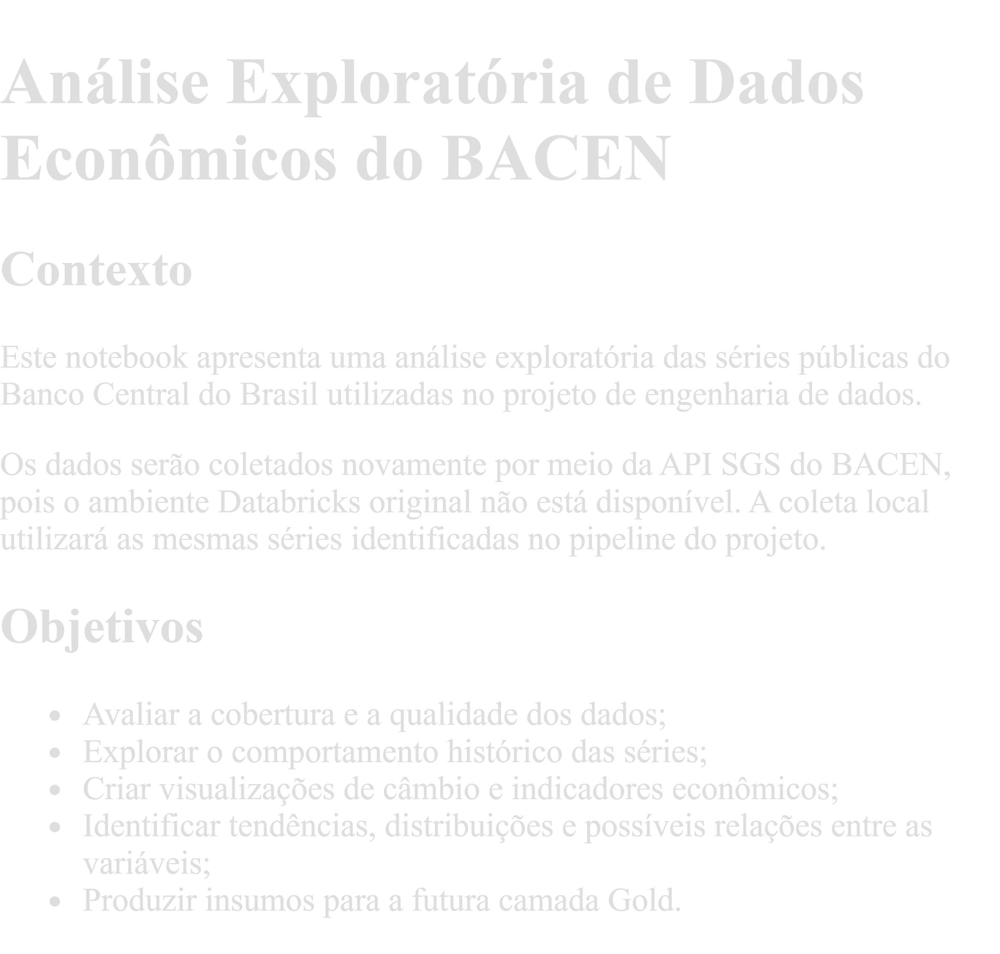

In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Código SGS 1: cotação do dólar em relação ao real
url_teste = (
    "https://api.bcb.gov.br/dados/serie/"
    "bcdata.sgs.1/dados/ultimos/10?formato=json"
)

resposta = requests.get(url_teste, timeout=60)

print("Status da requisição:", resposta.status_code)

Status da requisição: 200


In [3]:
dados_teste = resposta.json()

df_teste = pd.DataFrame(dados_teste)

df_teste

,data,valor
0,09/10/2026,4.9892
1,13/10/2026,5.0096
2,14/10/2026,5.0441
3,15/10/2026,5.0521
4,16/10/2026,5.0826
5,19/10/2026,5.0564
6,20/10/2026,5.0140
7,21/10/2026,5.0277
8,22/10/2026,5.0383
9,23/10/2026,5.0377


In [4]:
print("Quantidade de linhas e colunas:", df_teste.shape)

print("\nNomes das colunas:")
print(df_teste.columns.tolist())

print("\nTipos das colunas:")
df_teste.info()

Quantidade de linhas e colunas: (10, 2)

Nomes das colunas:
['data', 'valor']

Tipos das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   data    10 non-null     str  
 1   valor   10 non-null     str  
dtypes: str(2)
memory usage: 292.0 bytes


In [5]:
df_teste.head()

,data,valor
0,09/10/2026,4.9892
1,13/10/2026,5.0096
2,14/10/2026,5.0441
3,15/10/2026,5.0521
4,16/10/2026,5.0826


In [7]:
# Criar uma cópia para preservar os dados originais
df_teste_tratado = df_teste.copy()

# Converter a coluna data de texto para data
df_teste_tratado["data"] = pd.to_datetime(
    df_teste_tratado["data"],
    format="%d/%m/%Y"
)

# Converter a coluna valor de texto para número decimal
df_teste_tratado["valor"] = pd.to_numeric(
    df_teste_tratado["valor"],
    errors="coerce"
)

df_teste_tratado.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   data    10 non-null     datetime64[us]
 1   valor   10 non-null     float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 292.0 bytes


In [8]:
df_teste_tratado

,data,valor
0,2026-10-09,4.9892
1,2026-10-13,5.0096
2,2026-10-14,5.0441
3,2026-10-15,5.0521
4,2026-10-16,5.0826
5,2026-10-19,5.0564
6,2026-10-20,5.0140
7,2026-10-21,5.0277
8,2026-10-22,5.0383
9,2026-10-23,5.0377


In [9]:
print("Quantidade de registros:", len(df_teste_tratado))

print("\nValores nulos por coluna:")
print(df_teste_tratado.isnull().sum())

print("\nQuantidade de linhas duplicadas:")
print(df_teste_tratado.duplicated().sum())

Quantidade de registros: 10

Valores nulos por coluna:
data     0
valor    0
dtype: int64

Quantidade de linhas duplicadas:
0


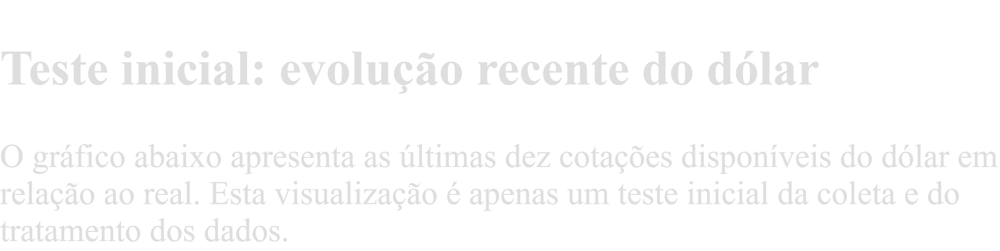

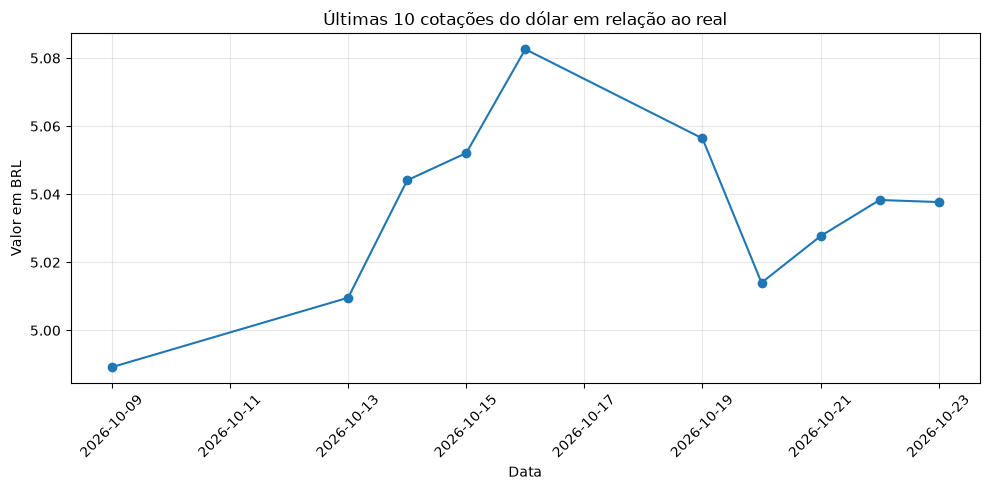

In [12]:
# Ordenar os registros da data mais antiga para a mais recente
df_teste_tratado = df_teste_tratado.sort_values("data")

# Criar a visualização
plt.figure(figsize=(10, 5))

plt.plot(
    df_teste_tratado["data"],
    df_teste_tratado["valor"],
    marker="o"
)

plt.title("Últimas 10 cotações do dólar em relação ao real")
plt.xlabel("Data")
plt.ylabel("Valor em BRL")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

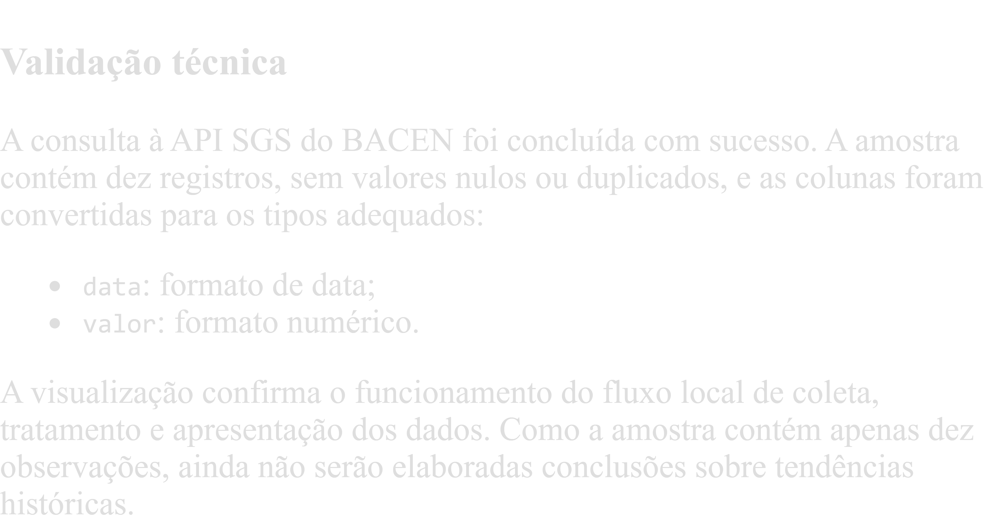

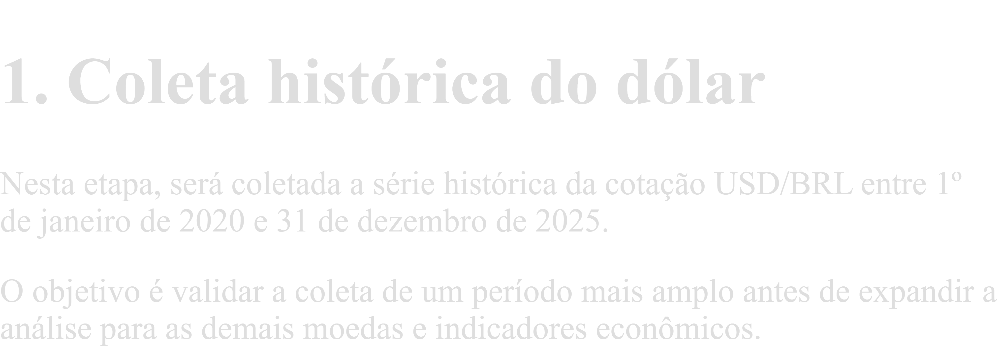

In [13]:
# Configuração da série histórica do dólar

codigo_serie = 1
data_inicial = "01/01/2020"
data_final = "31/12/2025"

url_dolar_historico = (
    f"https://api.bcb.gov.br/dados/serie/"
    f"bcdata.sgs.{codigo_serie}/dados"
)

parametros = {
    "formato": "json",
    "dataInicial": data_inicial,
    "dataFinal": data_final
}

print("Série SGS:", codigo_serie)
print("Período:", data_inicial, "a", data_final)

Série SGS: 1
Período: 01/01/2020 a 31/12/2025


In [14]:
resposta_dolar = requests.get(
    url_dolar_historico,
    params=parametros,
    timeout=60
)

print("Status da requisição:", resposta_dolar.status_code)
print("URL consultada:", resposta_dolar.url)

Status da requisição: 200
URL consultada: https://api.bcb.gov.br/dados/serie/bcdata.sgs.1/dados?formato=json&dataInicial=01%2F01%2F2020&dataFinal=31%2F12%2F2025


In [15]:
dados_dolar = resposta_dolar.json()

df_dolar_raw = pd.DataFrame(dados_dolar)

print("Quantidade de registros recebidos:", len(df_dolar_raw))

df_dolar_raw.head()

Quantidade de registros recebidos: 1507


,data,valor
0,02/01/2020,4.0213
1,03/01/2020,4.0522
2,06/01/2020,4.0554
3,07/01/2020,4.0841
4,08/01/2020,4.0672


In [16]:
df_dolar_raw.tail()

,data,valor
1502,24/12/2025,5.5350
1503,26/12/2025,5.5413
1504,29/12/2025,5.5739
1505,30/12/2025,5.5024
1506,31/12/2025,5.5024


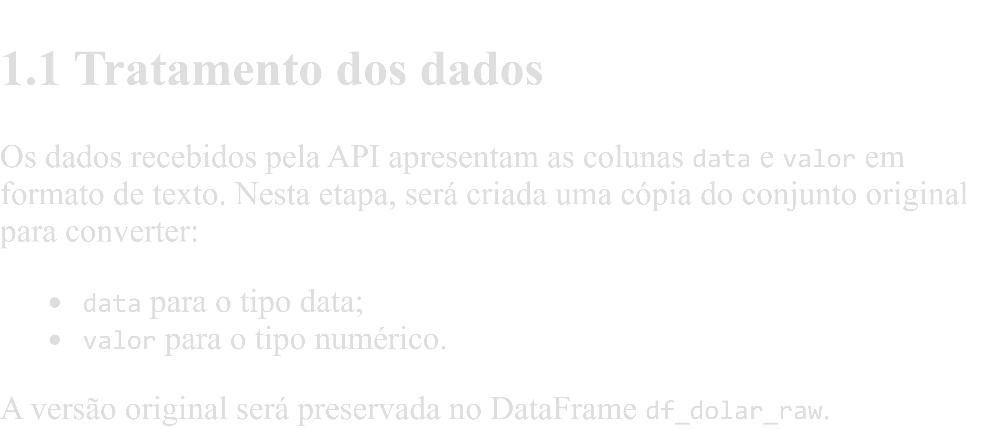

In [17]:
# Criar uma cópia para preservar os dados originais
df_dolar = df_dolar_raw.copy()

# Converter a data
df_dolar["data"] = pd.to_datetime(
    df_dolar["data"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Converter o valor
df_dolar["valor"] = pd.to_numeric(
    df_dolar["valor"],
    errors="coerce"
)

# Ordenar os registros por data
df_dolar = (
    df_dolar
    .sort_values("data")
    .reset_index(drop=True)
)

df_dolar.info()

<class 'pandas.DataFrame'>
RangeIndex: 1507 entries, 0 to 1506
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   data    1507 non-null   datetime64[us]
 1   valor   1507 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 23.7 KB


In [18]:
print("Primeiros registros:")
display(df_dolar.head())

print("Últimos registros:")
display(df_dolar.tail())

Primeiros registros:


,data,valor
0,2020-01-02,4.0213
1,2020-01-03,4.0522
2,2020-01-06,4.0554
3,2020-01-07,4.0841
4,2020-01-08,4.0672


Últimos registros:


,data,valor
1502,2025-12-24,5.5350
1503,2025-12-26,5.5413
1504,2025-12-29,5.5739
1505,2025-12-30,5.5024
1506,2025-12-31,5.5024


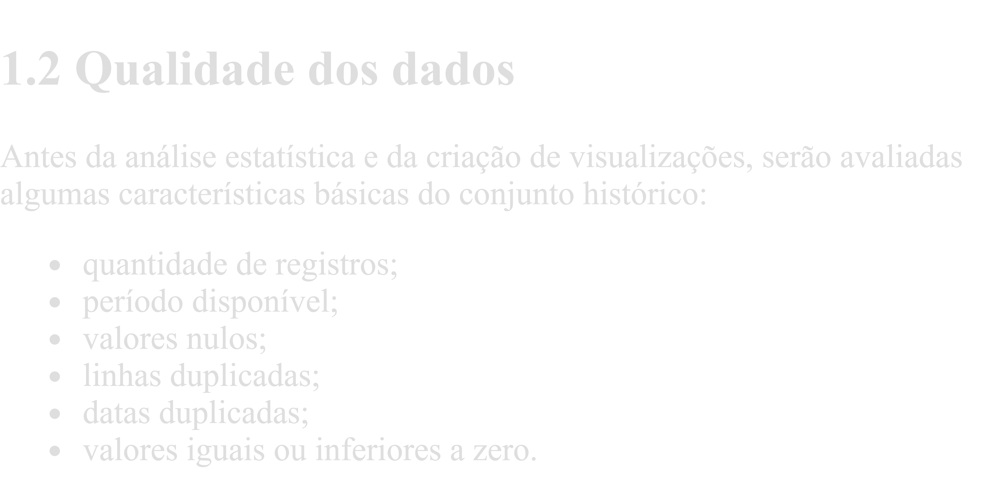

In [19]:
print("Quantidade de registros:", len(df_dolar))

print("\nPeríodo disponível:")
print("Data inicial:", df_dolar["data"].min())
print("Data final:", df_dolar["data"].max())

print("\nValores nulos por coluna:")
print(df_dolar.isnull().sum())

print("\nLinhas completamente duplicadas:")
print(df_dolar.duplicated().sum())

print("\nDatas duplicadas:")
print(df_dolar.duplicated(subset=["data"]).sum())

print("\nValores iguais ou inferiores a zero:")
print((df_dolar["valor"] <= 0).sum())

Quantidade de registros: 1507

Período disponível:
Data inicial: 2020-01-02 00:00:00
Data final: 2025-12-31 00:00:00

Valores nulos por coluna:
data     0
valor    0
dtype: int64

Linhas completamente duplicadas:
0

Datas duplicadas:
0

Valores iguais ou inferiores a zero:
0


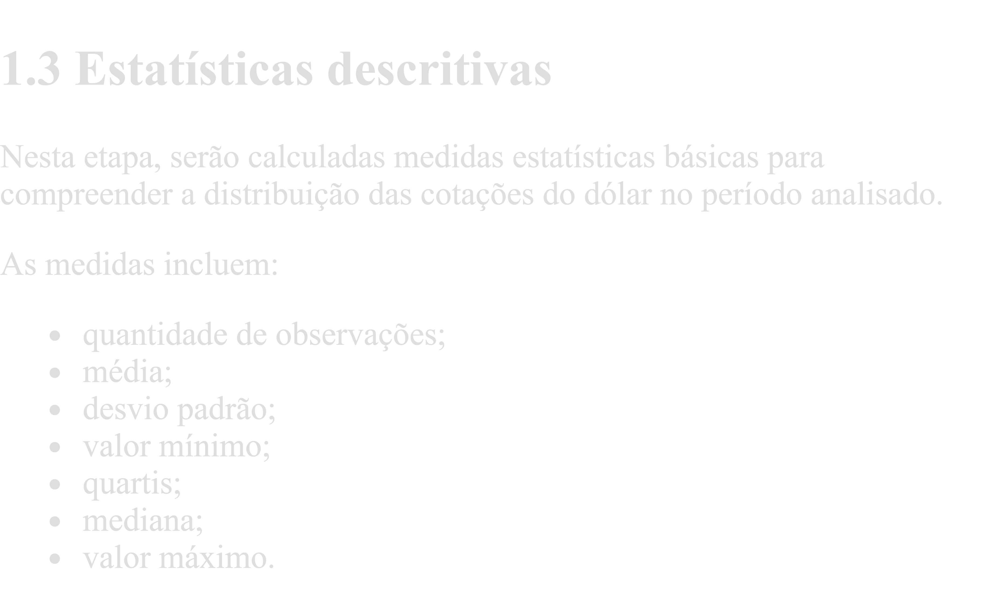

In [20]:
estatisticas_dolar = df_dolar["valor"].describe()

estatisticas_dolar

count    1507.000000
mean        5.282675
std         0.350876
min         4.021300
25%         5.060250
50%         5.293200
75%         5.521300
max         6.208600
Name: valor, dtype: float64

In [21]:
print(f"Quantidade de observações: {estatisticas_dolar['count']:.0f}")
print(f"Cotação média: R$ {estatisticas_dolar['mean']:.4f}")
print(f"Desvio padrão: R$ {estatisticas_dolar['std']:.4f}")
print(f"Menor cotação: R$ {estatisticas_dolar['min']:.4f}")
print(f"Primeiro quartil: R$ {estatisticas_dolar['25%']:.4f}")
print(f"Mediana: R$ {estatisticas_dolar['50%']:.4f}")
print(f"Terceiro quartil: R$ {estatisticas_dolar['75%']:.4f}")
print(f"Maior cotação: R$ {estatisticas_dolar['max']:.4f}")

Quantidade de observações: 1507
Cotação média: R$ 5.2827
Desvio padrão: R$ 0.3509
Menor cotação: R$ 4.0213
Primeiro quartil: R$ 5.0602
Mediana: R$ 5.2932
Terceiro quartil: R$ 5.5213
Maior cotação: R$ 6.2086


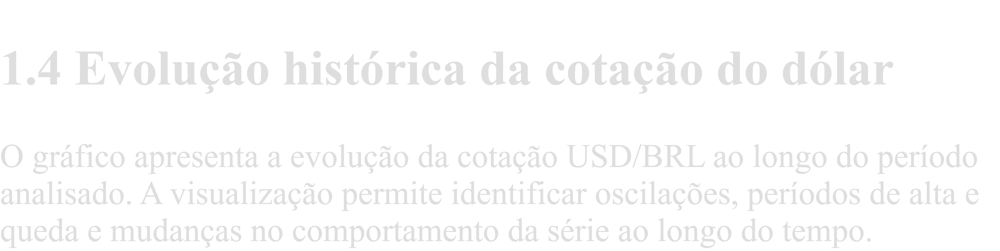

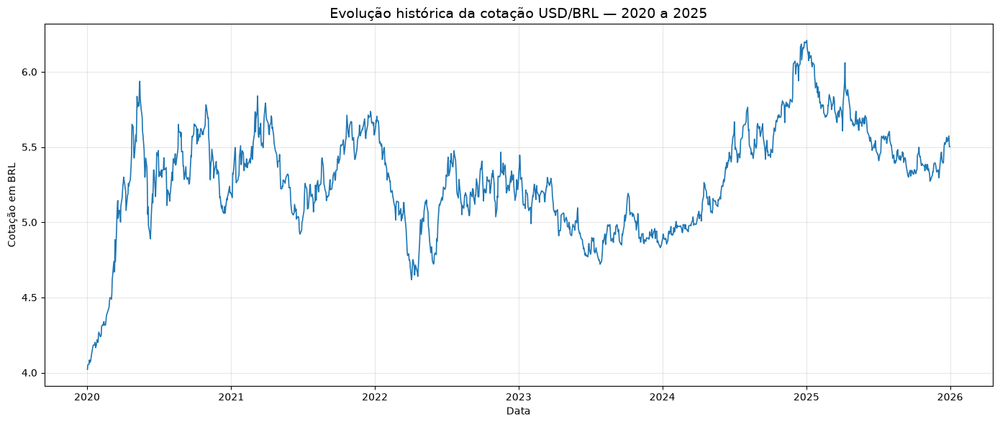

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar["data"],
    df_dolar["valor"],
    linewidth=1.2,
    color="#1f77b4"
)

plt.title(
    "Evolução histórica da cotação USD/BRL — 2020 a 2025",
    fontsize=14
)

plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

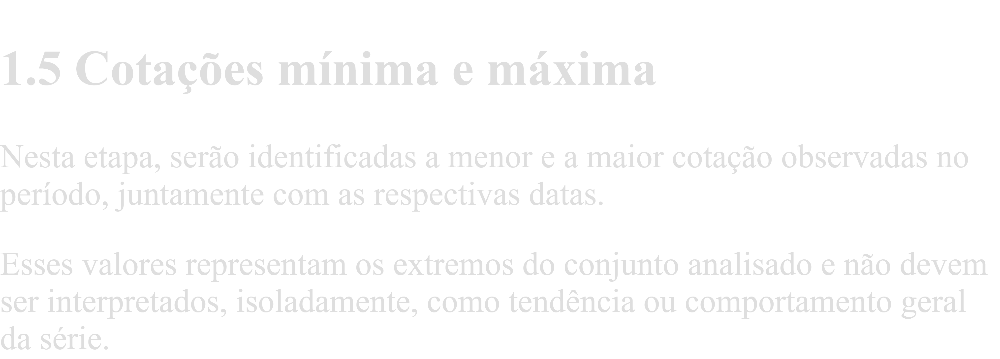

In [23]:
# Localizar os índices da menor e da maior cotação
indice_minimo = df_dolar["valor"].idxmin()
indice_maximo = df_dolar["valor"].idxmax()

# Recuperar os respectivos registros
registro_minimo = df_dolar.loc[indice_minimo]
registro_maximo = df_dolar.loc[indice_maximo]

print("Menor cotação do período")
print(f"Data: {registro_minimo['data']:%d/%m/%Y}")
print(f"Valor: R$ {registro_minimo['valor']:.4f}")

print("\nMaior cotação do período")
print(f"Data: {registro_maximo['data']:%d/%m/%Y}")
print(f"Valor: R$ {registro_maximo['valor']:.4f}")

Menor cotação do período
Data: 02/01/2020
Valor: R$ 4.0213

Maior cotação do período
Data: 02/01/2025
Valor: R$ 6.2086


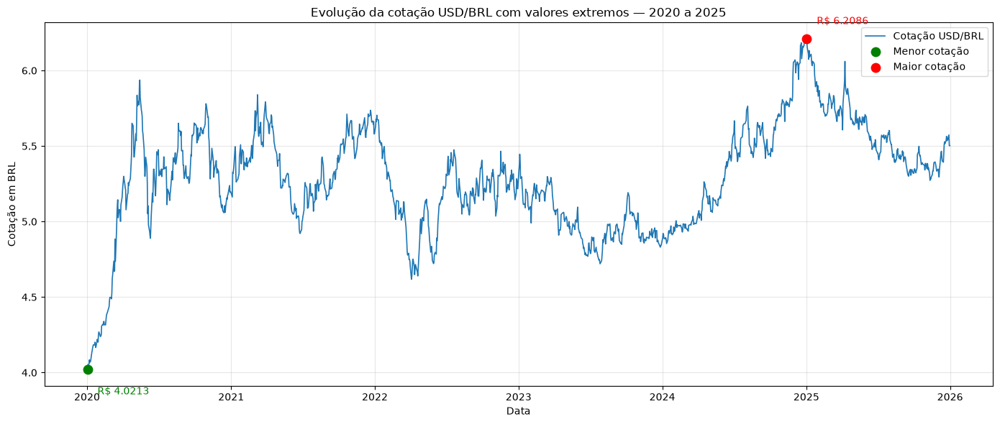

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar["data"],
    df_dolar["valor"],
    linewidth=1.2,
    color="#1f77b4",
    label="Cotação USD/BRL"
)

plt.scatter(
    registro_minimo["data"],
    registro_minimo["valor"],
    color="green",
    s=80,
    label="Menor cotação",
    zorder=3
)

plt.scatter(
    registro_maximo["data"],
    registro_maximo["valor"],
    color="red",
    s=80,
    label="Maior cotação",
    zorder=3
)

plt.annotate(
    f"R$ {registro_minimo['valor']:.4f}",
    xy=(registro_minimo["data"], registro_minimo["valor"]),
    xytext=(10, -25),
    textcoords="offset points",
    color="green"
)

plt.annotate(
    f"R$ {registro_maximo['valor']:.4f}",
    xy=(registro_maximo["data"], registro_maximo["valor"]),
    xytext=(10, 15),
    textcoords="offset points",
    color="red"
)

plt.title("Evolução da cotação USD/BRL com valores extremos — 2020 a 2025")
plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

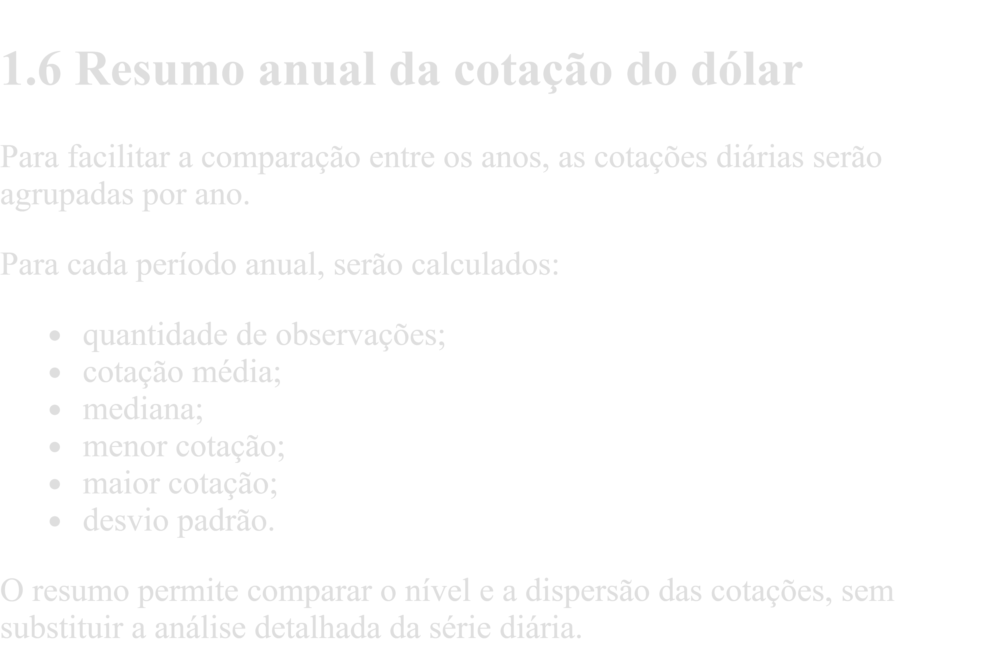

In [25]:
# Criar uma cópia para a análise anual
df_dolar_anual_base = df_dolar.copy()

# Extrair o ano da data
df_dolar_anual_base["ano"] = df_dolar_anual_base["data"].dt.year

df_dolar_anual_base.head()

,data,valor,ano
0,2020-01-02,4.0213,2020
1,2020-01-03,4.0522,2020
2,2020-01-06,4.0554,2020
3,2020-01-07,4.0841,2020
4,2020-01-08,4.0672,2020


In [26]:
resumo_anual_dolar = (
    df_dolar_anual_base
    .groupby("ano")
    .agg(
        observacoes=("valor", "count"),
        media=("valor", "mean"),
        mediana=("valor", "median"),
        minimo=("valor", "min"),
        maximo=("valor", "max"),
        desvio_padrao=("valor", "std")
    )
    .reset_index()
)

resumo_anual_dolar

,ano,observacoes,media,mediana,minimo,maximo,desvio_padrao
0,2020,251,5.157773,5.28540,4.0213,5.9372,0.470024
1,2021,251,5.395561,5.40240,4.9206,5.8397,0.209008
2,2022,251,5.165482,5.18840,4.6175,5.7042,0.223245
3,2023,249,4.995348,4.96780,4.7202,5.4459,0.148686
4,2024,253,5.392016,5.44120,4.8543,6.1991,0.360142
5,2025,252,5.585500,5.54345,5.2729,6.2086,0.212913


In [27]:
resumo_anual_exibicao = resumo_anual_dolar.copy()

colunas_numericas = [
    "media",
    "mediana",
    "minimo",
    "maximo",
    "desvio_padrao"
]

resumo_anual_exibicao[colunas_numericas] = (
    resumo_anual_exibicao[colunas_numericas].round(4)
)

resumo_anual_exibicao

,ano,observacoes,media,mediana,minimo,maximo,desvio_padrao
0,2020,251,5.1578,5.2854,4.0213,5.9372,0.4700
1,2021,251,5.3956,5.4024,4.9206,5.8397,0.2090
2,2022,251,5.1655,5.1884,4.6175,5.7042,0.2232
3,2023,249,4.9953,4.9678,4.7202,5.4459,0.1487
4,2024,253,5.3920,5.4412,4.8543,6.1991,0.3601
5,2025,252,5.5855,5.5434,5.2729,6.2086,0.2129


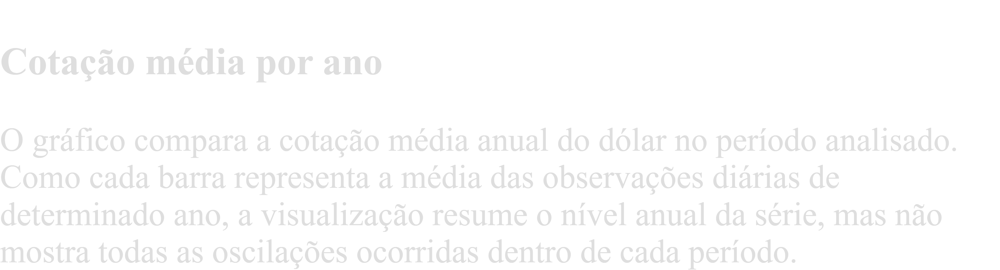

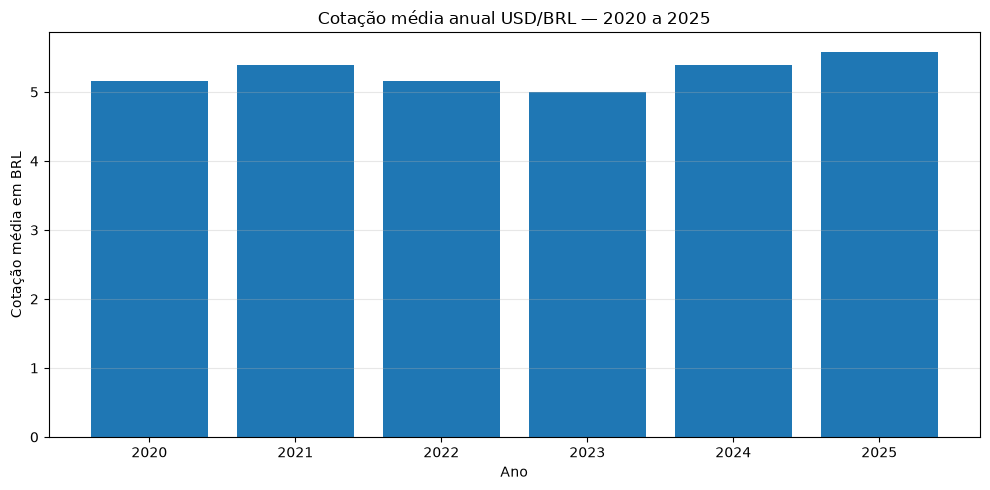

In [28]:
plt.figure(figsize=(10, 5))

plt.bar(
    resumo_anual_dolar["ano"].astype(str),
    resumo_anual_dolar["media"],
    color="#1f77b4"
)

plt.title("Cotação média anual USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Cotação média em BRL")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

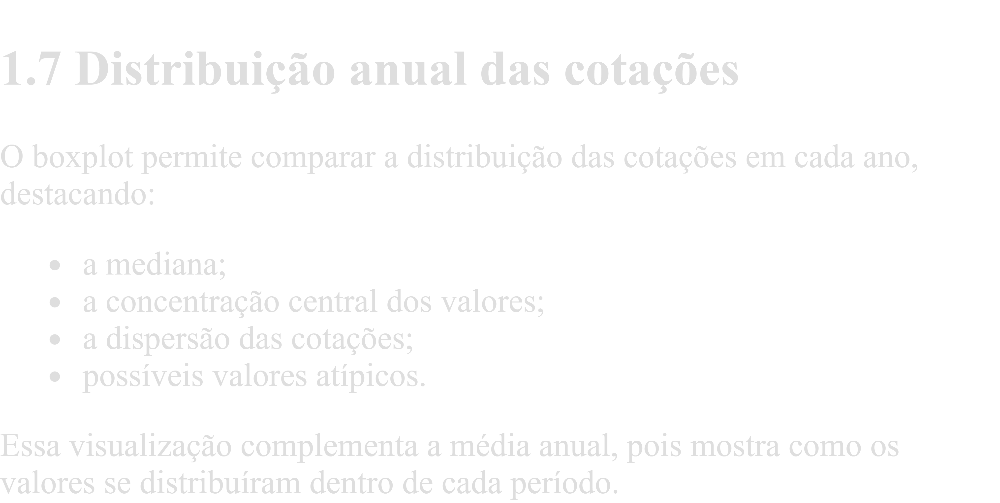

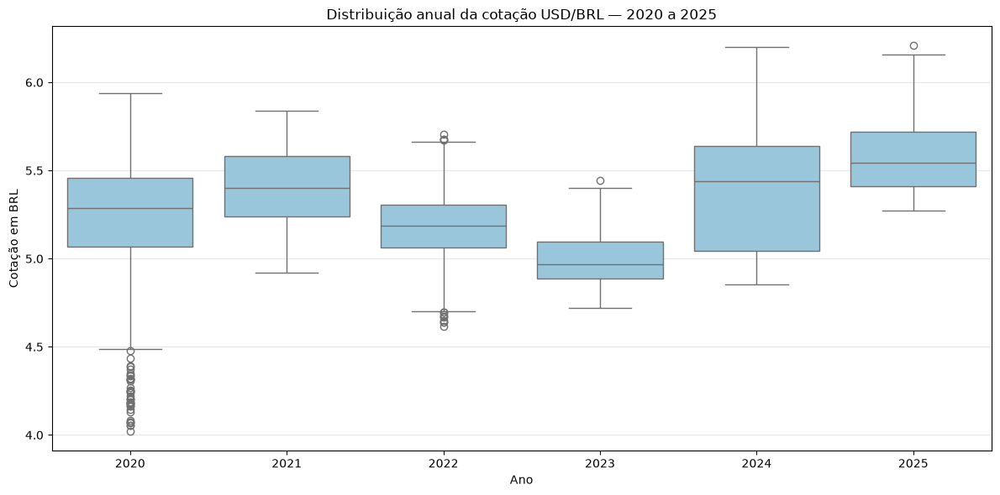

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_dolar_anual_base,
    x="ano",
    y="valor",
    color="#8ecae6"
)

plt.title("Distribuição anual da cotação USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Cotação em BRL")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [30]:
resumo_anual_dolar["amplitude"] = (
    resumo_anual_dolar["maximo"]
    - resumo_anual_dolar["minimo"]
)

amplitude_anual = resumo_anual_dolar[
    ["ano", "minimo", "maximo", "amplitude", "desvio_padrao"]
].copy()

amplitude_anual[
    ["minimo", "maximo", "amplitude", "desvio_padrao"]
] = amplitude_anual[
    ["minimo", "maximo", "amplitude", "desvio_padrao"]
].round(4)

amplitude_anual

,ano,minimo,maximo,amplitude,desvio_padrao
0,2020,4.0213,5.9372,1.9159,0.4700
1,2021,4.9206,5.8397,0.9191,0.2090
2,2022,4.6175,5.7042,1.0867,0.2232
3,2023,4.7202,5.4459,0.7257,0.1487
4,2024,4.8543,6.1991,1.3448,0.3601
5,2025,5.2729,6.2086,0.9357,0.2129


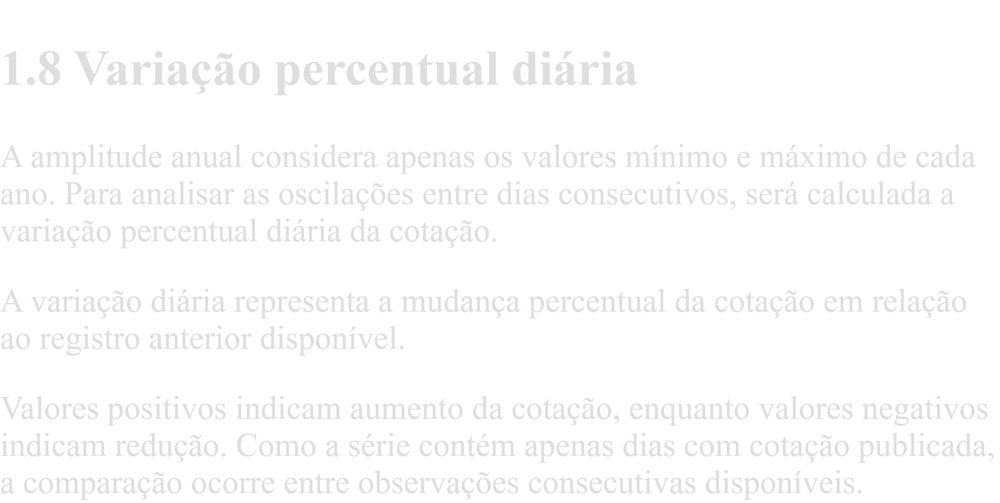

In [31]:
# Criar uma cópia para preservar o DataFrame tratado
df_dolar_variacao = df_dolar.copy()

# Calcular a variação percentual em relação à observação anterior
df_dolar_variacao["variacao_diaria_pct"] = (
    df_dolar_variacao["valor"]
    .pct_change(fill_method=None)
    .mul(100)
)

df_dolar_variacao.head()

,data,valor,variacao_diaria_pct
0,2020-01-02,4.0213,NaN
1,2020-01-03,4.0522,0.768408
2,2020-01-06,4.0554,0.078969
3,2020-01-07,4.0841,0.707698
4,2020-01-08,4.0672,-0.413800


In [32]:
estatisticas_variacao_diaria = (
    df_dolar_variacao["variacao_diaria_pct"]
    .describe()
)

estatisticas_variacao_diaria

count    1506.000000
mean        0.024979
std         0.912384
min        -4.505270
25%        -0.484455
50%         0.000000
75%         0.492357
max         4.482434
Name: variacao_diaria_pct, dtype: float64

In [33]:
maior_alta_diaria = df_dolar_variacao.loc[
    df_dolar_variacao["variacao_diaria_pct"].idxmax()
]

maior_queda_diaria = df_dolar_variacao.loc[
    df_dolar_variacao["variacao_diaria_pct"].idxmin()
]

print("Maior alta diária observada:")
print(f"Data: {maior_alta_diaria['data']:%d/%m/%Y}")
print(f"Cotação: R$ {maior_alta_diaria['valor']:.4f}")
print(
    f"Variação: "
    f"{maior_alta_diaria['variacao_diaria_pct']:.2f}%"
)

print("\nMaior queda diária observada:")
print(f"Data: {maior_queda_diaria['data']:%d/%m/%Y}")
print(f"Cotação: R$ {maior_queda_diaria['valor']:.4f}")
print(
    f"Variação: "
    f"{maior_queda_diaria['variacao_diaria_pct']:.2f}%"
)

Maior alta diária observada:
Data: 12/03/2020
Cotação: R$ 4.8833
Variação: 4.48%

Maior queda diária observada:
Data: 09/11/2020
Cotação: R$ 5.2821
Variação: -4.51%


In [48]:
# Recalcular os registros necessários para o resumo

# Menor e maior cotação do período
registro_minimo = df_dolar.loc[
    df_dolar["valor"].idxmin()
]

registro_maximo = df_dolar.loc[
    df_dolar["valor"].idxmax()
]

# Ano com maior e menor cotação média
ano_maior_media = resumo_anual_dolar.loc[
    resumo_anual_dolar["media"].idxmax()
]

ano_menor_media = resumo_anual_dolar.loc[
    resumo_anual_dolar["media"].idxmin()
]

# Ano com maior e menor volatilidade
ano_maior_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmax()
]

ano_menor_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmin()
]

# Criar a tabela consolidada
resumo_eda_dolar = pd.DataFrame({
    "Indicador": [
        "Data inicial",
        "Data final",
        "Quantidade de observações",
        "Cotação média",
        "Mediana",
        "Menor cotação",
        "Data da menor cotação",
        "Maior cotação",
        "Data da maior cotação",
        "Ano com maior média",
        "Maior média anual",
        "Ano com menor média",
        "Menor média anual",
        "Ano com maior volatilidade",
        "Maior volatilidade diária anual",
        "Ano com menor volatilidade",
        "Menor volatilidade diária anual"
    ],
    "Resultado": [
        df_dolar["data"].min().strftime("%d/%m/%Y"),
        df_dolar["data"].max().strftime("%d/%m/%Y"),
        f"{len(df_dolar)}",
        f"R$ {df_dolar['valor'].mean():.4f}",
        f"R$ {df_dolar['valor'].median():.4f}",
        f"R$ {registro_minimo['valor']:.4f}",
        registro_minimo["data"].strftime("%d/%m/%Y"),
        f"R$ {registro_maximo['valor']:.4f}",
        registro_maximo["data"].strftime("%d/%m/%Y"),
        f"{int(ano_maior_media['ano'])}",
        f"R$ {ano_maior_media['media']:.4f}",
        f"{int(ano_menor_media['ano'])}",
        f"R$ {ano_menor_media['media']:.4f}",
        f"{int(ano_maior_volatilidade['ano'])}",
        f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%",
        f"{int(ano_menor_volatilidade['ano'])}",
        f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
    ]
})

resumo_eda_dolar

,Indicador,Resultado
0,Data inicial,02/01/2020
1,Data final,31/12/2025
2,Quantidade de observações,1507
3,Cotação média,R$ 5.2827
4,Mediana,R$ 5.2932
5,Menor cotação,R$ 4.0213
6,Data da menor cotação,02/01/2020
7,Maior cotação,R$ 6.2086
8,Data da maior cotação,02/01/2025
9,Ano com maior média,2025


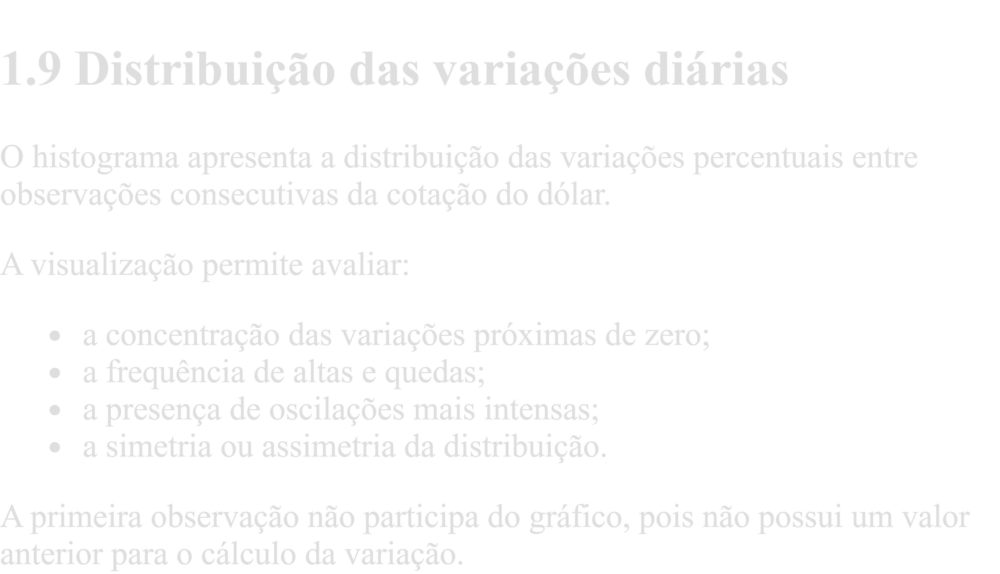

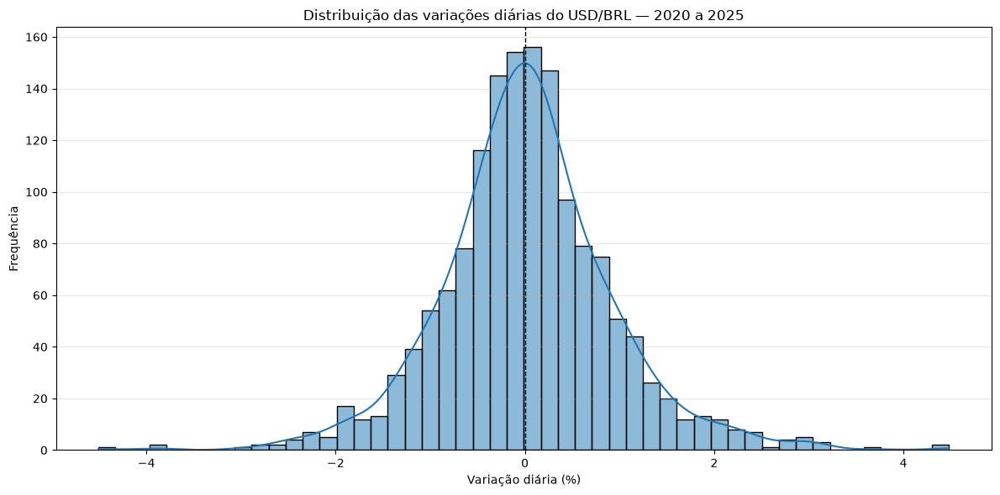

In [34]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_dolar_variacao,
    x="variacao_diaria_pct",
    bins=50,
    kde=True,
    color="#1f77b4"
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Distribuição das variações diárias do USD/BRL — 2020 a 2025")
plt.xlabel("Variação diária (%)")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [35]:
quantidade_altas = (
    df_dolar_variacao["variacao_diaria_pct"] > 0
).sum()

quantidade_quedas = (
    df_dolar_variacao["variacao_diaria_pct"] < 0
).sum()

quantidade_sem_variacao = (
    df_dolar_variacao["variacao_diaria_pct"] == 0
).sum()

total_variacoes_validas = (
    df_dolar_variacao["variacao_diaria_pct"]
    .notna()
    .sum()
)

print("Resumo das variações diárias")
print(f"Altas: {quantidade_altas}")
print(f"Quedas: {quantidade_quedas}")
print(f"Sem variação: {quantidade_sem_variacao}")
print(f"Total de variações válidas: {total_variacoes_validas}")

Resumo das variações diárias
Altas: 748
Quedas: 750
Sem variação: 8
Total de variações válidas: 1506


In [36]:
soma_classificacoes = (
    quantidade_altas
    + quantidade_quedas
    + quantidade_sem_variacao
)

print("Soma das classificações:", soma_classificacoes)
print("Total de variações válidas:", total_variacoes_validas)

print(
    "Contagens consistentes:",
    soma_classificacoes == total_variacoes_validas
)

Soma das classificações: 1506
Total de variações válidas: 1506
Contagens consistentes: True


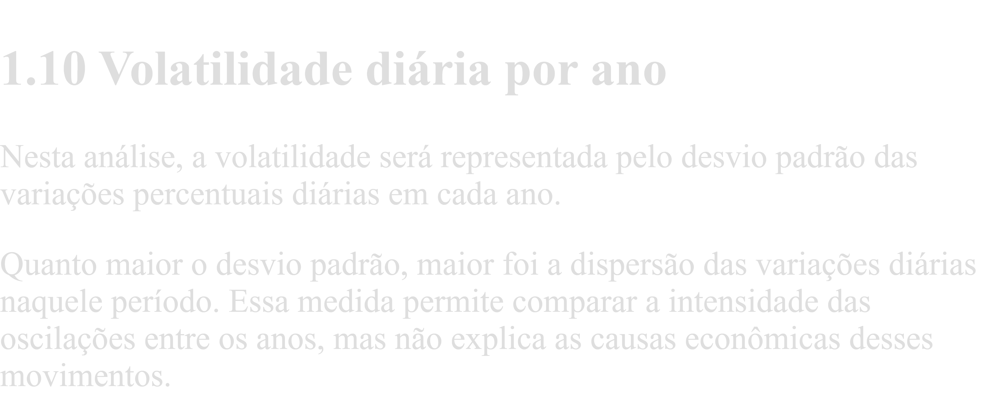

In [37]:
# Criar uma cópia para a análise de volatilidade
df_volatilidade = df_dolar_variacao.copy()

# Extrair o ano da data
df_volatilidade["ano"] = df_volatilidade["data"].dt.year

df_volatilidade.head()

,data,valor,variacao_diaria_pct,ano
0,2020-01-02,4.0213,NaN,2020
1,2020-01-03,4.0522,0.768408,2020
2,2020-01-06,4.0554,0.078969,2020
3,2020-01-07,4.0841,0.707698,2020
4,2020-01-08,4.0672,-0.413800,2020


In [38]:
volatilidade_anual = (
    df_volatilidade
    .groupby("ano")
    .agg(
        observacoes=("variacao_diaria_pct", "count"),
        variacao_media_pct=("variacao_diaria_pct", "mean"),
        volatilidade_pct=("variacao_diaria_pct", "std"),
        menor_variacao_pct=("variacao_diaria_pct", "min"),
        maior_variacao_pct=("variacao_diaria_pct", "max")
    )
    .reset_index()
)

volatilidade_anual

,ano,observacoes,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,2020,250,0.110781,1.280976,-4.505270,4.482434
1,2021,251,0.032682,0.928322,-2.868020,3.182505
2,2022,251,-0.021664,1.013967,-3.817556,3.152601
3,2023,249,-0.027329,0.741307,-2.558075,2.425897
4,2024,253,0.099765,0.699772,-1.939423,2.710539
5,2025,252,-0.044756,0.650954,-2.458543,3.049922


In [39]:
volatilidade_anual_exibicao = volatilidade_anual.copy()

colunas_percentuais = [
    "variacao_media_pct",
    "volatilidade_pct",
    "menor_variacao_pct",
    "maior_variacao_pct"
]

volatilidade_anual_exibicao[colunas_percentuais] = (
    volatilidade_anual_exibicao[colunas_percentuais]
    .round(4)
)

volatilidade_anual_exibicao

,ano,observacoes,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,2020,250,0.1108,1.2810,-4.5053,4.4824
1,2021,251,0.0327,0.9283,-2.8680,3.1825
2,2022,251,-0.0217,1.0140,-3.8176,3.1526
3,2023,249,-0.0273,0.7413,-2.5581,2.4259
4,2024,253,0.0998,0.6998,-1.9394,2.7105
5,2025,252,-0.0448,0.6510,-2.4585,3.0499


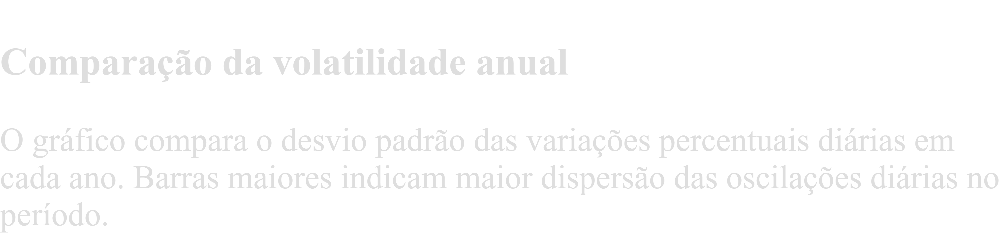

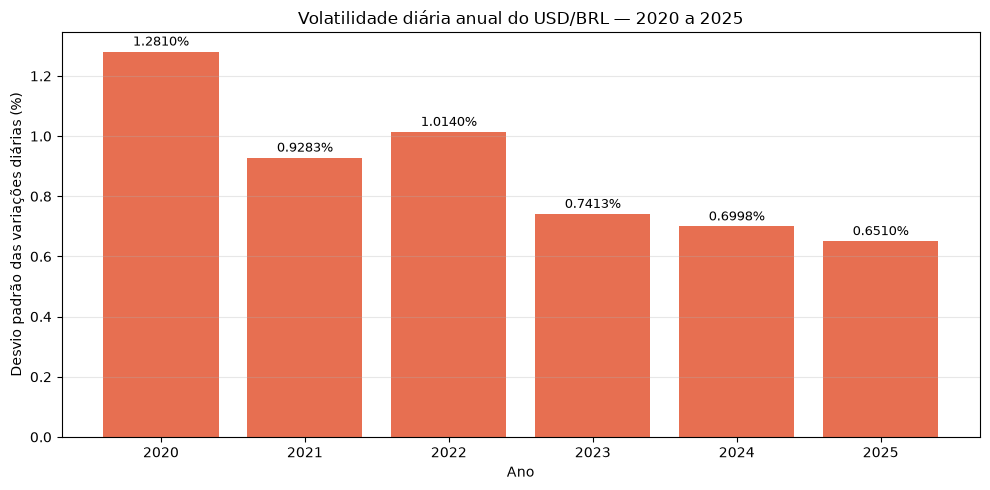

In [40]:
plt.figure(figsize=(10, 5))

barras = plt.bar(
    volatilidade_anual["ano"].astype(str),
    volatilidade_anual["volatilidade_pct"],
    color="#e76f51"
)

for barra, valor in zip(
    barras,
    volatilidade_anual["volatilidade_pct"]
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.01,
        f"{valor:.4f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title("Volatilidade diária anual do USD/BRL — 2020 a 2025")
plt.xlabel("Ano")
plt.ylabel("Desvio padrão das variações diárias (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [41]:
ano_maior_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmax()
]

ano_menor_volatilidade = volatilidade_anual.loc[
    volatilidade_anual["volatilidade_pct"].idxmin()
]

print("Ano com maior volatilidade diária:")
print(f"Ano: {int(ano_maior_volatilidade['ano'])}")
print(
    f"Volatilidade: "
    f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%"
)

print("\nAno com menor volatilidade diária:")
print(f"Ano: {int(ano_menor_volatilidade['ano'])}")
print(
    f"Volatilidade: "
    f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
)

Ano com maior volatilidade diária:
Ano: 2020
Volatilidade: 1.2810%

Ano com menor volatilidade diária:
Ano: 2025
Volatilidade: 0.6510%


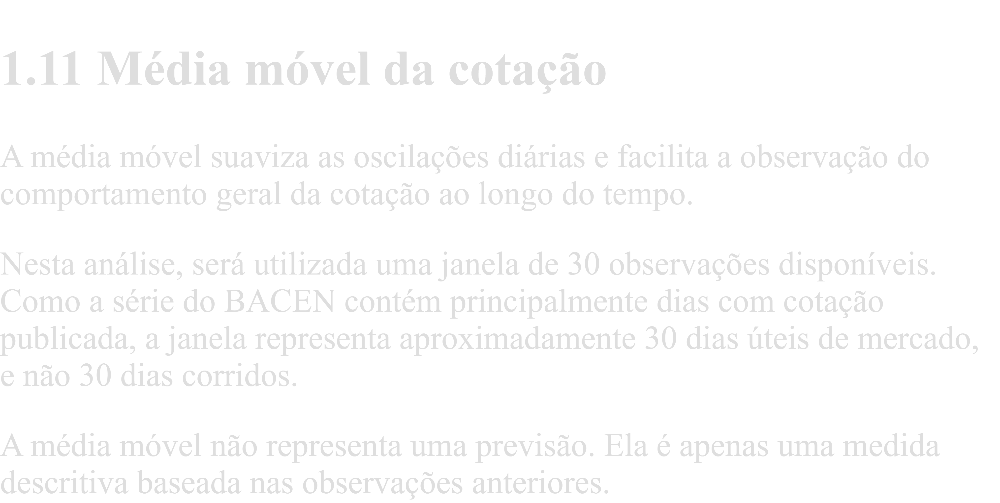

In [42]:
# Criar uma cópia para preservar o DataFrame tratado
df_dolar_media_movel = df_dolar.copy()

# Calcular a média móvel das últimas 30 observações
df_dolar_media_movel["media_movel_30"] = (
    df_dolar_media_movel["valor"]
    .rolling(window=30)
    .mean()
)

df_dolar_media_movel.head(35)

,data,valor,media_movel_30
0,2020-01-02,4.0213,NaN
1,2020-01-03,4.0522,NaN
2,2020-01-06,4.0554,NaN
3,2020-01-07,4.0841,NaN
4,2020-01-08,4.0672,NaN
5,2020-01-09,4.0744,NaN
6,2020-01-10,4.0745,NaN
7,2020-01-13,4.1309,NaN
8,2020-01-14,4.1443,NaN
9,2020-01-15,4.1622,NaN


In [43]:
print(
    "Quantidade de registros da série:",
    len(df_dolar_media_movel)
)

print(
    "Médias móveis calculadas:",
    df_dolar_media_movel["media_movel_30"].notna().sum()
)

print(
    "Registros iniciais sem média móvel:",
    df_dolar_media_movel["media_movel_30"].isna().sum()
)

Quantidade de registros da série: 1507
Médias móveis calculadas: 1478
Registros iniciais sem média móvel: 29


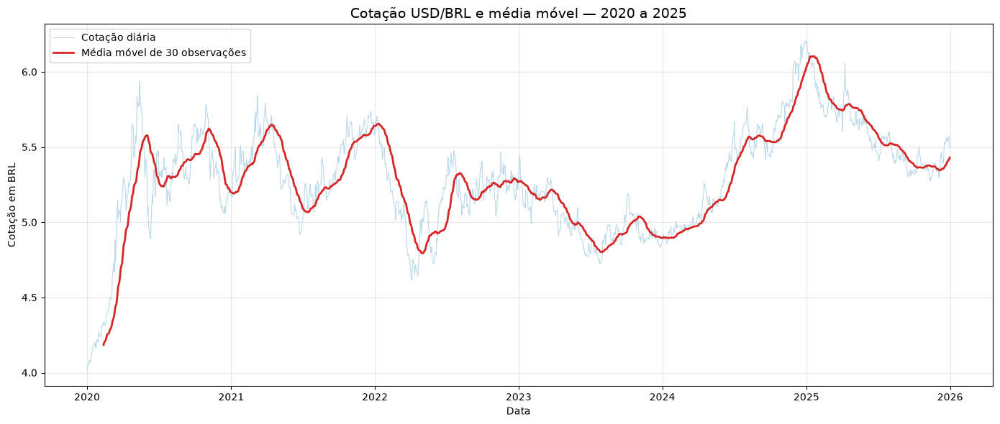

In [44]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_dolar_media_movel["data"],
    df_dolar_media_movel["valor"],
    color="#9ecae1",
    linewidth=0.8,
    alpha=0.7,
    label="Cotação diária"
)

plt.plot(
    df_dolar_media_movel["data"],
    df_dolar_media_movel["media_movel_30"],
    color="#d62728",
    linewidth=2,
    label="Média móvel de 30 observações"
)

plt.title(
    "Cotação USD/BRL e média móvel — 2020 a 2025",
    fontsize=14
)

plt.xlabel("Data")
plt.ylabel("Cotação em BRL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

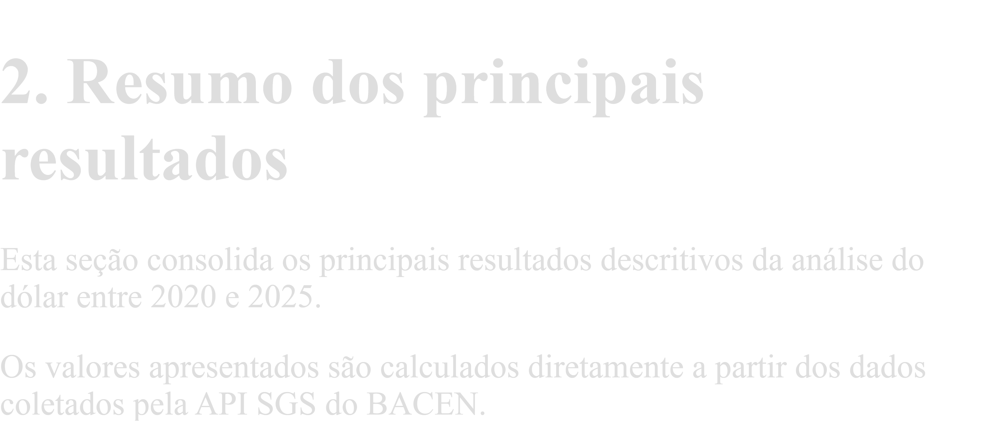

In [49]:
resumo_eda_dolar = pd.DataFrame({
    "Indicador": [
        "Data inicial",
        "Data final",
        "Quantidade de observações",
        "Cotação média",
        "Mediana",
        "Menor cotação",
        "Data da menor cotação",
        "Maior cotação",
        "Data da maior cotação",
        "Ano com maior média",
        "Maior média anual",
        "Ano com menor média",
        "Menor média anual",
        "Ano com maior volatilidade",
        "Maior volatilidade diária anual",
        "Ano com menor volatilidade",
        "Menor volatilidade diária anual"
    ],
    "Resultado": [
        df_dolar["data"].min().strftime("%d/%m/%Y"),
        df_dolar["data"].max().strftime("%d/%m/%Y"),
        f"{len(df_dolar)}",
        f"R$ {df_dolar['valor'].mean():.4f}",
        f"R$ {df_dolar['valor'].median():.4f}",
        f"R$ {registro_minimo['valor']:.4f}",
        registro_minimo["data"].strftime("%d/%m/%Y"),
        f"R$ {registro_maximo['valor']:.4f}",
        registro_maximo["data"].strftime("%d/%m/%Y"),
        f"{int(ano_maior_media['ano'])}",
        f"R$ {ano_maior_media['media']:.4f}",
        f"{int(ano_menor_media['ano'])}",
        f"R$ {ano_menor_media['media']:.4f}",
        f"{int(ano_maior_volatilidade['ano'])}",
        f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%",
        f"{int(ano_menor_volatilidade['ano'])}",
        f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%"
    ]
})

resumo_eda_dolar

,Indicador,Resultado
0,Data inicial,02/01/2020
1,Data final,31/12/2025
2,Quantidade de observações,1507
3,Cotação média,R$ 5.2827
4,Mediana,R$ 5.2932
5,Menor cotação,R$ 4.0213
6,Data da menor cotação,02/01/2020
7,Maior cotação,R$ 6.2086
8,Data da maior cotação,02/01/2025
9,Ano com maior média,2025


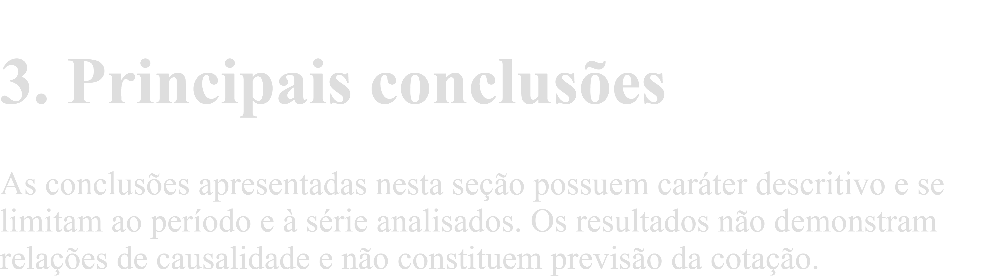

In [50]:
print("PRINCIPAIS RESULTADOS DO EDA\n")

print(
    f"1. O conjunto analisado compreende o período de "
    f"{df_dolar['data'].min():%d/%m/%Y} a "
    f"{df_dolar['data'].max():%d/%m/%Y}, "
    f"com {len(df_dolar)} observações."
)

print(
    f"\n2. A cotação média do período foi de "
    f"R$ {df_dolar['valor'].mean():.4f}, "
    f"enquanto a mediana foi de "
    f"R$ {df_dolar['valor'].median():.4f}."
)

print(
    f"\n3. A menor cotação observada foi de "
    f"R$ {registro_minimo['valor']:.4f}, "
    f"registrada em {registro_minimo['data']:%d/%m/%Y}."
)

print(
    f"\n4. A maior cotação observada foi de "
    f"R$ {registro_maximo['valor']:.4f}, "
    f"registrada em {registro_maximo['data']:%d/%m/%Y}."
)

print(
    f"\n5. O ano com a maior cotação média foi "
    f"{int(ano_maior_media['ano'])}, "
    f"com média de R$ {ano_maior_media['media']:.4f}."
)

print(
    f"\n6. O ano com a menor cotação média foi "
    f"{int(ano_menor_media['ano'])}, "
    f"com média de R$ {ano_menor_media['media']:.4f}."
)

print(
    f"\n7. O ano com maior volatilidade diária foi "
    f"{int(ano_maior_volatilidade['ano'])}, "
    f"com desvio padrão das variações de "
    f"{ano_maior_volatilidade['volatilidade_pct']:.4f}%."
)

print(
    f"\n8. O ano com menor volatilidade diária foi "
    f"{int(ano_menor_volatilidade['ano'])}, "
    f"com desvio padrão das variações de "
    f"{ano_menor_volatilidade['volatilidade_pct']:.4f}%."
)

print(
    "\n9. A média móvel de 30 observações suavizou as "
    "oscilações diárias e facilitou a visualização do "
    "comportamento geral da série."
)

PRINCIPAIS RESULTADOS DO EDA

1. O conjunto analisado compreende o período de 02/01/2020 a 31/12/2025, com 1507 observações.

2. A cotação média do período foi de R$ 5.2827, enquanto a mediana foi de R$ 5.2932.

3. A menor cotação observada foi de R$ 4.0213, registrada em 02/01/2020.

4. A maior cotação observada foi de R$ 6.2086, registrada em 02/01/2025.

5. O ano com a maior cotação média foi 2025, com média de R$ 5.5855.

6. O ano com a menor cotação média foi 2023, com média de R$ 4.9953.

7. O ano com maior volatilidade diária foi 2020, com desvio padrão das variações de 1.2810%.

8. O ano com menor volatilidade diária foi 2025, com desvio padrão das variações de 0.6510%.

9. A média móvel de 30 observações suavizou as oscilações diárias e facilitou a visualização do comportamento geral da série.


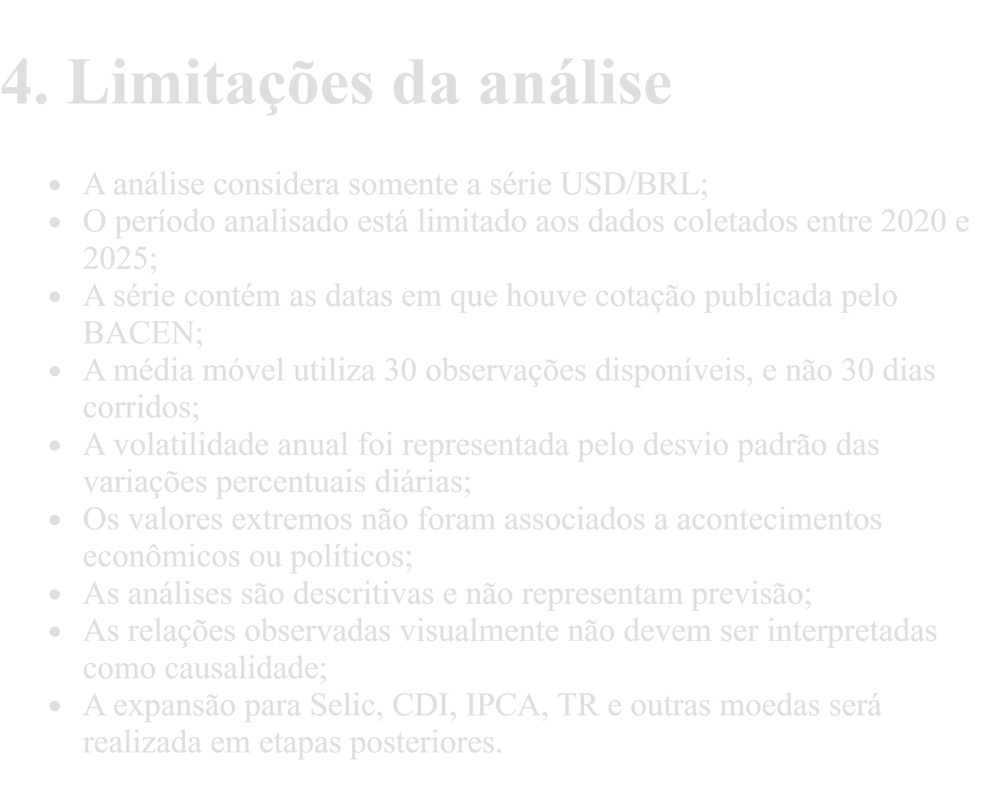

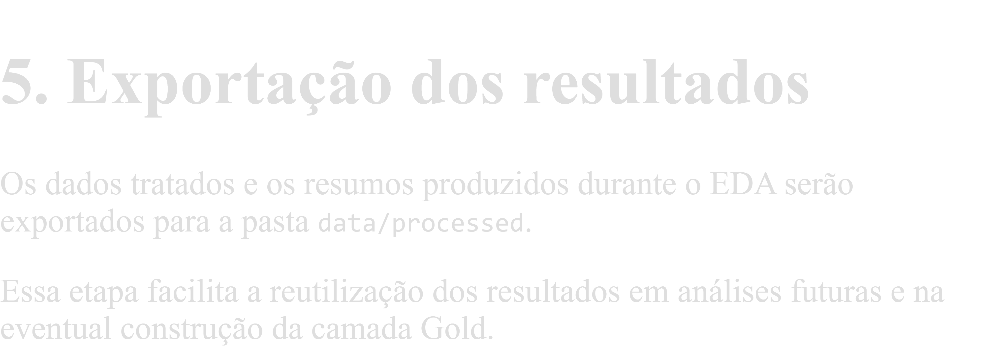

In [51]:
from pathlib import Path

# Definir a pasta de saída
pasta_processados = Path("../data/processed")

# Criar a pasta, caso ainda não exista
pasta_processados.mkdir(parents=True, exist_ok=True)

# Exportar os dados tratados
df_dolar.to_csv(
    pasta_processados / "dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar o resumo anual
resumo_anual_dolar.to_csv(
    pasta_processados / "resumo_anual_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar a volatilidade anual
volatilidade_anual.to_csv(
    pasta_processados / "volatilidade_anual_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Exportar o resumo consolidado do EDA
resumo_eda_dolar.to_csv(
    pasta_processados / "resumo_eda_dolar_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivos exportados com sucesso!")

Arquivos exportados com sucesso!


In [52]:
arquivos_exportados = sorted(pasta_processados.glob("*.csv"))

print("Arquivos encontrados:")

for arquivo in arquivos_exportados:
    print(f"- {arquivo.name}")

Arquivos encontrados:
- dolar_2020_2025.csv
- resumo_anual_dolar_2020_2025.csv
- resumo_eda_dolar_2020_2025.csv
- volatilidade_anual_dolar_2020_2025.csv


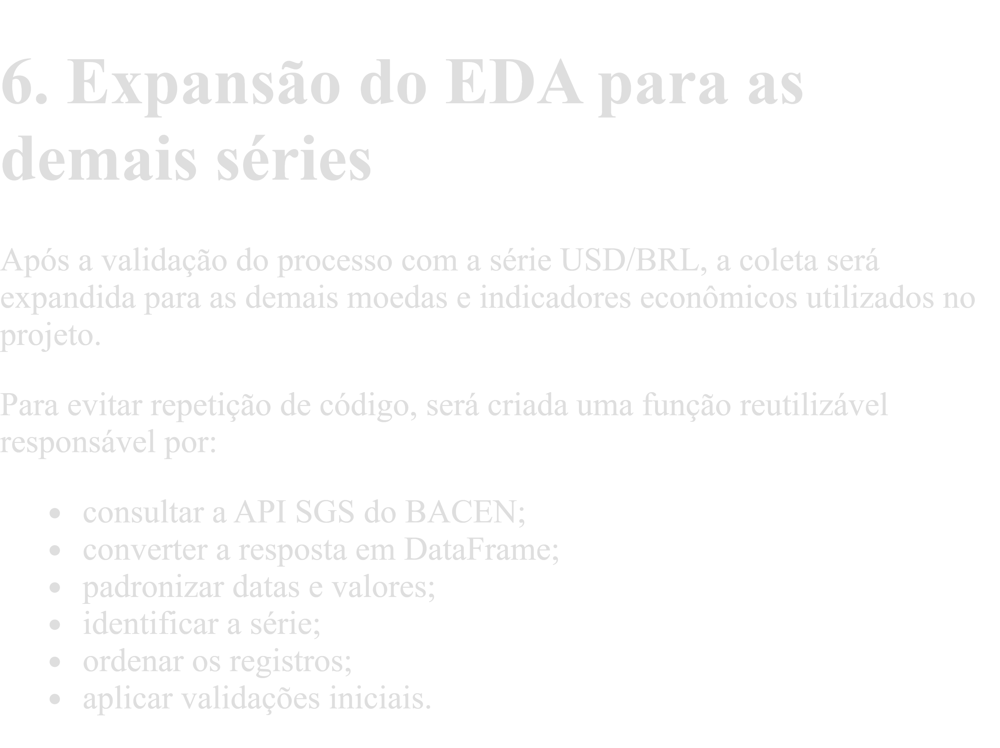

In [53]:
def coletar_serie_bacen(
    codigo,
    nome,
    data_inicial,
    data_final,
    timeout=60
):
    """
    Coleta e trata uma série do SGS/BACEN.

    Parâmetros
    ----------
    codigo : int
        Código da série no SGS.
    nome : str
        Nome utilizado para identificar a série.
    data_inicial : str
        Data inicial no formato dd/mm/aaaa.
    data_final : str
        Data final no formato dd/mm/aaaa.
    timeout : int
        Tempo máximo da requisição em segundos.

    Retorno
    -------
    pandas.DataFrame
        DataFrame com as colunas:
        serie, codigo_sgs, data e valor.
    """

    url = (
        "https://api.bcb.gov.br/dados/serie/"
        f"bcdata.sgs.{codigo}/dados"
    )

    parametros = {
        "formato": "json",
        "dataInicial": data_inicial,
        "dataFinal": data_final
    }

    resposta = requests.get(
        url,
        params=parametros,
        timeout=timeout
    )

    resposta.raise_for_status()

    dados = resposta.json()

    if not dados:
        raise ValueError(
            f"A série {nome} não retornou registros "
            f"no período solicitado."
        )

    dataframe = pd.DataFrame(dados)

    dataframe["data"] = pd.to_datetime(
        dataframe["data"],
        format="%d/%m/%Y",
        errors="coerce"
    )

    dataframe["valor"] = pd.to_numeric(
        dataframe["valor"],
        errors="coerce"
    )

    dataframe["serie"] = nome
    dataframe["codigo_sgs"] = codigo

    dataframe = (
        dataframe[
            ["serie", "codigo_sgs", "data", "valor"]
        ]
        .sort_values("data")
        .reset_index(drop=True)
    )

    return dataframe

In [54]:
df_teste_funcao = coletar_serie_bacen(
    codigo=1,
    nome="USD/BRL",
    data_inicial="01/01/2020",
    data_final="31/12/2025"
)

df_teste_funcao.head()


,serie,codigo_sgs,data,valor
0,USD/BRL,1,2020-01-02,4.0213
1,USD/BRL,1,2020-01-03,4.0522
2,USD/BRL,1,2020-01-06,4.0554
3,USD/BRL,1,2020-01-07,4.0841
4,USD/BRL,1,2020-01-08,4.0672


In [55]:
print("Quantidade de registros:", len(df_teste_funcao))

print("\nPeríodo:")
print("Inicial:", df_teste_funcao["data"].min())
print("Final:", df_teste_funcao["data"].max())

print("\nValores nulos:")
print(df_teste_funcao.isna().sum())

print("\nDatas duplicadas:")
print(
    df_teste_funcao
    .duplicated(subset=["serie", "data"])
    .sum()
)

Quantidade de registros: 1507

Período:
Inicial: 2020-01-02 00:00:00
Final: 2025-12-31 00:00:00

Valores nulos:
serie         0
codigo_sgs    0
data          0
valor         0
dtype: int64

Datas duplicadas:
0


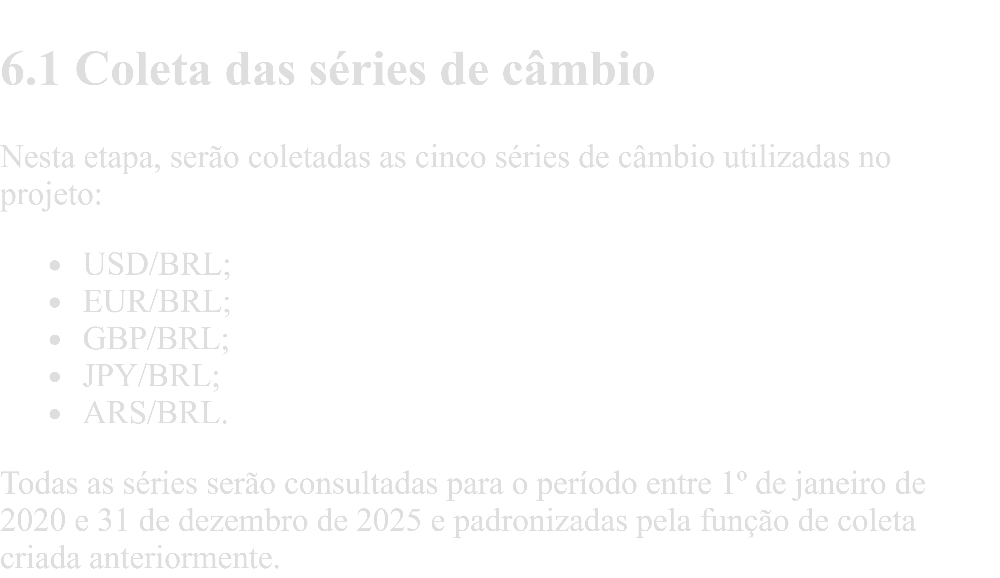

In [56]:
series_cambio = {
    "USD/BRL": 1,
    "EUR/BRL": 21619,
    "GBP/BRL": 21623,
    "JPY/BRL": 21621,
    "ARS/BRL": 21632
}

data_inicial_cambio = "01/01/2020"
data_final_cambio = "31/12/2025"

series_cambio

{'USD/BRL': 1,
 'EUR/BRL': 21619,
 'GBP/BRL': 21623,
 'JPY/BRL': 21621,
 'ARS/BRL': 21632}

In [60]:
import time
import json


def coletar_serie_bacen(
    codigo,
    nome,
    data_inicial,
    data_final,
    timeout=60,
    max_tentativas=3
):
    """
    Coleta e trata uma série do SGS/BACEN.

    Parâmetros
    ----------
    codigo : int
        Código da série no SGS.
    nome : str
        Nome utilizado para identificar a série.
    data_inicial : str
        Data inicial no formato dd/mm/aaaa.
    data_final : str
        Data final no formato dd/mm/aaaa.
    timeout : int
        Tempo máximo da requisição em segundos.
    max_tentativas : int
        Quantidade máxima de tentativas.

    Retorno
    -------
    pandas.DataFrame
        DataFrame com as colunas:
        serie, codigo_sgs, data e valor.
    """

    url = (
        "https://api.bcb.gov.br/dados/serie/"
        f"bcdata.sgs.{codigo}/dados"
    )

    parametros = {
        "formato": "json",
        "dataInicial": data_inicial,
        "dataFinal": data_final
    }

    headers = {
        "User-Agent": (
            "Mozilla/5.0 "
            "(Projeto acadêmico de análise de dados BACEN)"
        ),
        "Accept": "application/json"
    }

    ultimo_erro = None

    for tentativa in range(1, max_tentativas + 1):

        try:
            print(
                f"  Tentativa {tentativa}/{max_tentativas} "
                f"para {nome}..."
            )

            resposta = requests.get(
                url,
                params=parametros,
                headers=headers,
                timeout=timeout
            )

            print(
                f"  Status HTTP: {resposta.status_code}"
            )

            resposta.raise_for_status()

            if not resposta.text.strip():
                raise ValueError(
                    "A API retornou uma resposta vazia."
                )

            try:
                dados = resposta.json()

            except requests.exceptions.JSONDecodeError:
                inicio_resposta = resposta.text[:200]

                raise ValueError(
                    "A API retornou conteúdo diferente de JSON. "
                    f"Início da resposta: {inicio_resposta!r}"
                )

            if not dados:
                raise ValueError(
                    f"A série {nome} não retornou registros "
                    f"no período solicitado."
                )

            dataframe = pd.DataFrame(dados)

            colunas_esperadas = {"data", "valor"}

            if not colunas_esperadas.issubset(
                dataframe.columns
            ):
                raise ValueError(
                    "A resposta não contém as colunas "
                    "'data' e 'valor'."
                )

            dataframe["data"] = pd.to_datetime(
                dataframe["data"],
                format="%d/%m/%Y",
                errors="coerce"
            )

            dataframe["valor"] = pd.to_numeric(
                dataframe["valor"],
                errors="coerce"
            )

            dataframe["serie"] = nome
            dataframe["codigo_sgs"] = codigo

            dataframe = (
                dataframe[
                    ["serie", "codigo_sgs", "data", "valor"]
                ]
                .sort_values("data")
                .reset_index(drop=True)
            )

            print(
                f"  {nome}: "
                f"{len(dataframe)} registros coletados."
            )

            return dataframe

        except (
            requests.exceptions.RequestException,
            ValueError,
            json.JSONDecodeError
        ) as erro:

            ultimo_erro = erro

            print(
                f"  Falha na tentativa {tentativa}: {erro}"
            )

            if tentativa < max_tentativas:
                print("  Aguardando 5 segundos...")
                time.sleep(5)

    raise RuntimeError(
        f"Não foi possível coletar a série {nome} "
        f"após {max_tentativas} tentativas. "
        f"Último erro: {ultimo_erro}"
    )

In [61]:
df_teste_euro = coletar_serie_bacen(
    codigo=21619,
    nome="EUR/BRL",
    data_inicial="01/01/2020",
    data_final="31/12/2025"
)

df_teste_euro.head()

  Tentativa 1/3 para EUR/BRL...
  Status HTTP: 200
  EUR/BRL: 1506 registros coletados.


,serie,codigo_sgs,data,valor
0,EUR/BRL,21619,2020-01-02,4.5051
1,EUR/BRL,21619,2020-01-03,4.5247
2,EUR/BRL,21619,2020-01-06,4.5384
3,EUR/BRL,21619,2020-01-07,4.5513
4,EUR/BRL,21619,2020-01-08,4.5235


In [62]:
dataframes_cambio = []
falhas_cambio = []

for nome_serie, codigo_serie in series_cambio.items():

    print(f"\nColetando {nome_serie}...")

    try:
        dataframe_serie = coletar_serie_bacen(
            codigo=codigo_serie,
            nome=nome_serie,
            data_inicial=data_inicial_cambio,
            data_final=data_final_cambio
        )

        dataframes_cambio.append(dataframe_serie)

    except Exception as erro:
        falhas_cambio.append({
            "serie": nome_serie,
            "codigo_sgs": codigo_serie,
            "erro": str(erro)
        })

        print(f"Não foi possível coletar {nome_serie}.")

    # Evita muitas requisições consecutivas
    time.sleep(2)

print("\nColeta finalizada.")

print(
    "Séries coletadas com sucesso:",
    len(dataframes_cambio)
)

print(
    "Séries com falha:",
    len(falhas_cambio)
)


Coletando USD/BRL...
  Tentativa 1/3 para USD/BRL...
  Status HTTP: 200
  USD/BRL: 1507 registros coletados.

Coletando EUR/BRL...
  Tentativa 1/3 para EUR/BRL...
  Status HTTP: 200
  EUR/BRL: 1506 registros coletados.

Coletando GBP/BRL...
  Tentativa 1/3 para GBP/BRL...
  Status HTTP: 200
  GBP/BRL: 1506 registros coletados.

Coletando JPY/BRL...
  Tentativa 1/3 para JPY/BRL...
  Status HTTP: 200
  JPY/BRL: 1506 registros coletados.

Coletando ARS/BRL...
  Tentativa 1/3 para ARS/BRL...
  Status HTTP: 200
  ARS/BRL: 1506 registros coletados.

Coleta finalizada.
Séries coletadas com sucesso: 5
Séries com falha: 0


In [63]:
if falhas_cambio:
    df_falhas_cambio = pd.DataFrame(falhas_cambio)
    display(df_falhas_cambio)
else:
    print("Todas as séries foram coletadas com sucesso.")

Todas as séries foram coletadas com sucesso.


In [64]:
if dataframes_cambio:

    df_cambio = pd.concat(
        dataframes_cambio,
        ignore_index=True
    )

    print(
        "Quantidade total de registros:",
        len(df_cambio)
    )

    print("\nSéries presentes:")

    print(
        df_cambio["serie"]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

else:
    print("Nenhuma série foi coletada.")
    

Quantidade total de registros: 7531

Séries presentes:
['ARS/BRL', 'EUR/BRL', 'GBP/BRL', 'JPY/BRL', 'USD/BRL']


In [65]:
resumo_cobertura_cambio = (
    df_cambio
    .groupby(["serie", "codigo_sgs"])
    .agg(
        quantidade_registros=("valor", "count"),
        data_inicial=("data", "min"),
        data_final=("data", "max"),
        menor_valor=("valor", "min"),
        maior_valor=("valor", "max")
    )
    .reset_index()
)

resumo_cobertura_cambio

,serie,codigo_sgs,quantidade_registros,data_inicial,data_final,menor_valor,maior_valor
0,ARS/BRL,21632,1506,2020-01-02,2025-12-31,0.42890,0.68560
1,EUR/BRL,21619,1506,2020-01-02,2025-12-31,4.50510,6.94220
2,GBP/BRL,21623,1506,2020-01-02,2025-12-31,5.29830,8.11430
3,JPY/BRL,21621,1506,2020-01-02,2025-12-31,0.03228,0.05545
4,USD/BRL,1,1507,2020-01-02,2025-12-31,4.02130,6.20860


In [66]:
qualidade_cambio = (
    df_cambio
    .groupby("serie")
    .agg(
        registros=("valor", "size"),
        datas_nulas=("data", lambda coluna: coluna.isna().sum()),
        valores_nulos=("valor", lambda coluna: coluna.isna().sum()),
        valores_nao_positivos=(
            "valor",
            lambda coluna: (coluna <= 0).sum()
        )
    )
    .reset_index()
)

duplicidades_cambio = (
    df_cambio
    .duplicated(subset=["serie", "data"])
    .sum()
)

display(qualidade_cambio)

print(
    "Duplicidades por combinação série e data:",
    duplicidades_cambio
)

,serie,registros,datas_nulas,valores_nulos,valores_nao_positivos
0,ARS/BRL,1506,0,0,0
1,EUR/BRL,1506,0,0,0
2,GBP/BRL,1506,0,0,0
3,JPY/BRL,1506,0,0,0
4,USD/BRL,1507,0,0,0


Duplicidades por combinação série e data: 0


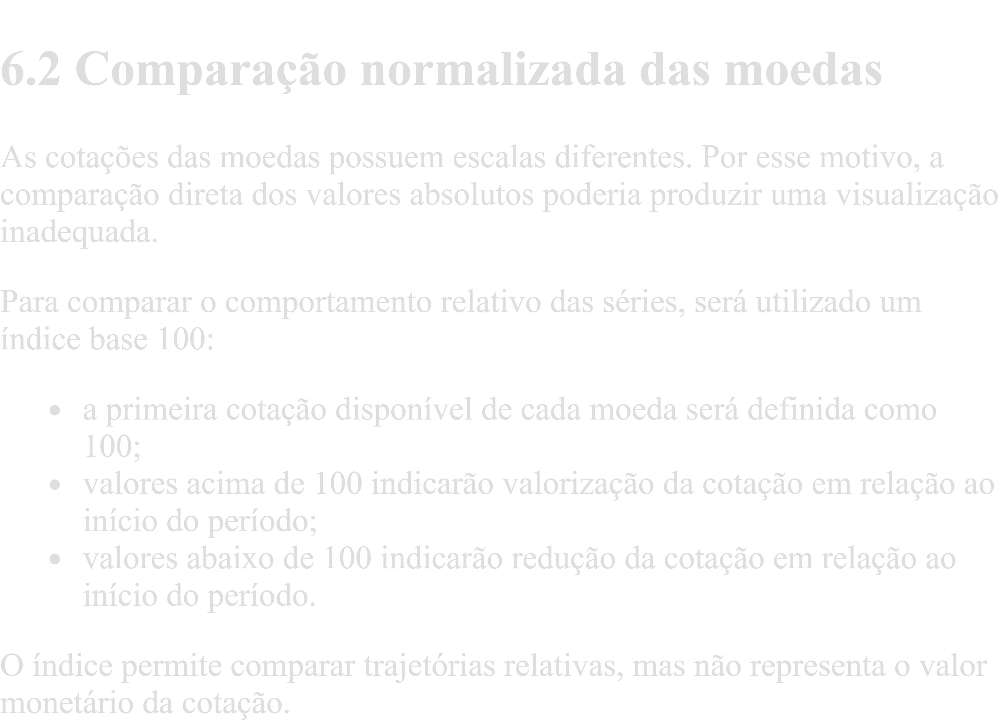

In [67]:
# Criar uma cópia para preservar o DataFrame consolidado
df_cambio_normalizado = df_cambio.copy()

# Garantir a ordenação por série e data
df_cambio_normalizado = (
    df_cambio_normalizado
    .sort_values(["serie", "data"])
    .reset_index(drop=True)
)

# Obter o primeiro valor disponível de cada série
df_cambio_normalizado["valor_inicial"] = (
    df_cambio_normalizado
    .groupby("serie")["valor"]
    .transform("first")
)

# Calcular o índice base 100
df_cambio_normalizado["indice_base_100"] = (
    df_cambio_normalizado["valor"]
    / df_cambio_normalizado["valor_inicial"]
    * 100
)

df_cambio_normalizado.head()

,serie,codigo_sgs,data,valor,valor_inicial,indice_base_100
0,ARS/BRL,21632,2020-01-02,0.4304,0.4304,100.000000
1,ARS/BRL,21632,2020-01-03,0.4314,0.4304,100.232342
2,ARS/BRL,21632,2020-01-06,0.4308,0.4304,100.092937
3,ARS/BRL,21632,2020-01-07,0.4321,0.4304,100.394981
4,ARS/BRL,21632,2020-01-08,0.4302,0.4304,99.953532


In [68]:
primeiros_indices = (
    df_cambio_normalizado
    .groupby("serie")
    .first()
    .reset_index()
    [["serie", "data", "valor", "valor_inicial", "indice_base_100"]]
)

primeiros_indices

,serie,data,valor,valor_inicial,indice_base_100
0,ARS/BRL,2020-01-02,0.43040,0.43040,100.0
1,EUR/BRL,2020-01-02,4.50510,4.50510,100.0
2,GBP/BRL,2020-01-02,5.30450,5.30450,100.0
3,JPY/BRL,2020-01-02,0.03715,0.03715,100.0
4,USD/BRL,2020-01-02,4.02130,4.02130,100.0


In [69]:
validacao_base_100 = (
    primeiros_indices["indice_base_100"]
    .round(6)
    .eq(100)
    .all()
)

print(
    "Todas as séries começam com índice 100:",
    validacao_base_100
)

Todas as séries começam com índice 100: True


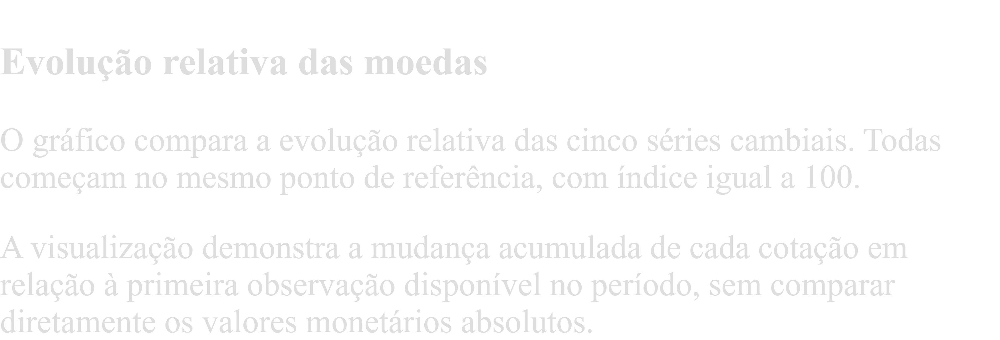

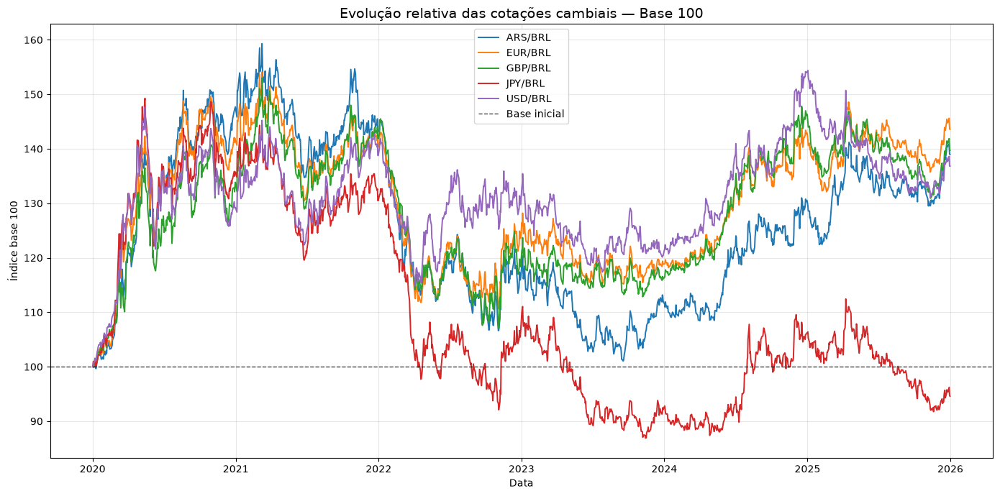

In [70]:
plt.figure(figsize=(14, 7))

for nome_serie, dados_serie in (
    df_cambio_normalizado.groupby("serie")
):
    plt.plot(
        dados_serie["data"],
        dados_serie["indice_base_100"],
        linewidth=1.4,
        label=nome_serie
    )

plt.axhline(
    y=100,
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    label="Base inicial"
)

plt.title(
    "Evolução relativa das cotações cambiais — Base 100",
    fontsize=14
)

plt.xlabel("Data")
plt.ylabel("Índice base 100")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

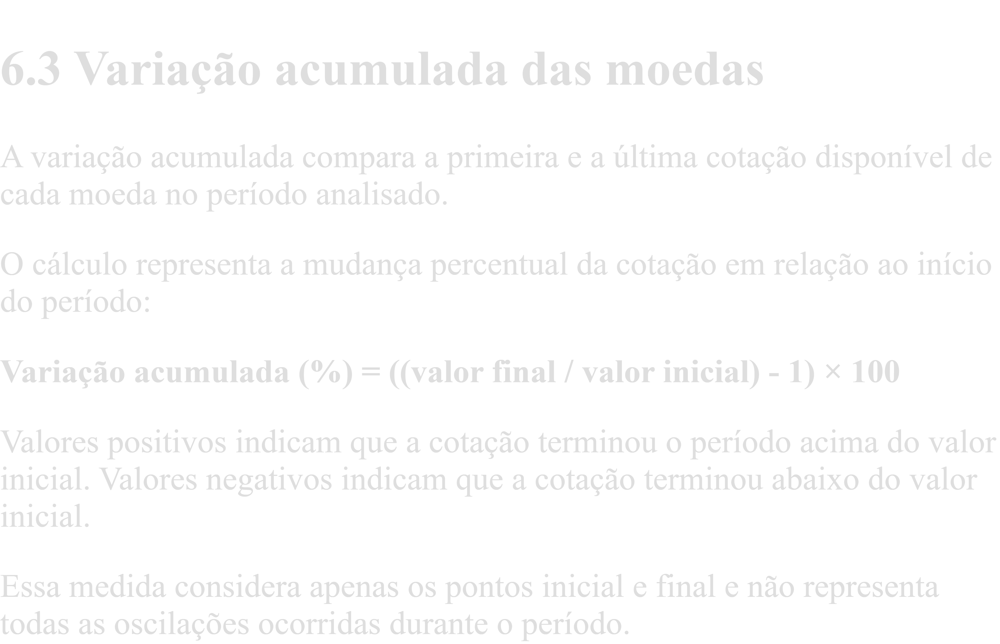

In [71]:
# Obter a primeira e a última observação de cada moeda
resumo_variacao_cambio = (
    df_cambio
    .sort_values(["serie", "data"])
    .groupby("serie")
    .agg(
        data_inicial=("data", "first"),
        valor_inicial=("valor", "first"),
        data_final=("data", "last"),
        valor_final=("valor", "last")
    )
    .reset_index()
)

# Calcular a variação acumulada
resumo_variacao_cambio["variacao_acumulada_pct"] = (
    (
        resumo_variacao_cambio["valor_final"]
        / resumo_variacao_cambio["valor_inicial"]
    )
    - 1
) * 100

resumo_variacao_cambio

,serie,data_inicial,valor_inicial,data_final,valor_final,variacao_acumulada_pct
0,ARS/BRL,2020-01-02,0.43040,2025-12-31,0.59810,38.963755
1,EUR/BRL,2020-01-02,4.50510,2025-12-31,6.46920,43.597256
2,GBP/BRL,2020-01-02,5.30450,2025-12-31,7.41120,39.715336
3,JPY/BRL,2020-01-02,0.03715,2025-12-31,0.03514,-5.410498
4,USD/BRL,2020-01-02,4.02130,2025-12-31,5.50240,36.831373


In [72]:
resumo_variacao_cambio_exibicao = (
    resumo_variacao_cambio.copy()
)

colunas_arredondar = [
    "valor_inicial",
    "valor_final",
    "variacao_acumulada_pct"
]

resumo_variacao_cambio_exibicao[
    colunas_arredondar
] = resumo_variacao_cambio_exibicao[
    colunas_arredondar
].round(4)

resumo_variacao_cambio_exibicao


,serie,data_inicial,valor_inicial,data_final,valor_final,variacao_acumulada_pct
0,ARS/BRL,2020-01-02,0.4304,2025-12-31,0.5981,38.9638
1,EUR/BRL,2020-01-02,4.5051,2025-12-31,6.4692,43.5973
2,GBP/BRL,2020-01-02,5.3045,2025-12-31,7.4112,39.7153
3,JPY/BRL,2020-01-02,0.0372,2025-12-31,0.0351,-5.4105
4,USD/BRL,2020-01-02,4.0213,2025-12-31,5.5024,36.8314


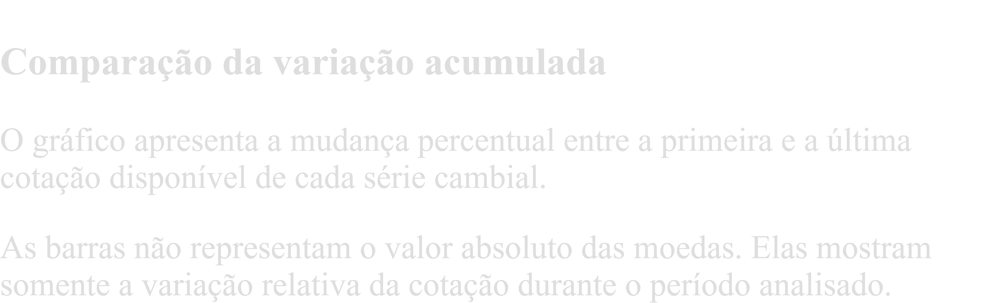

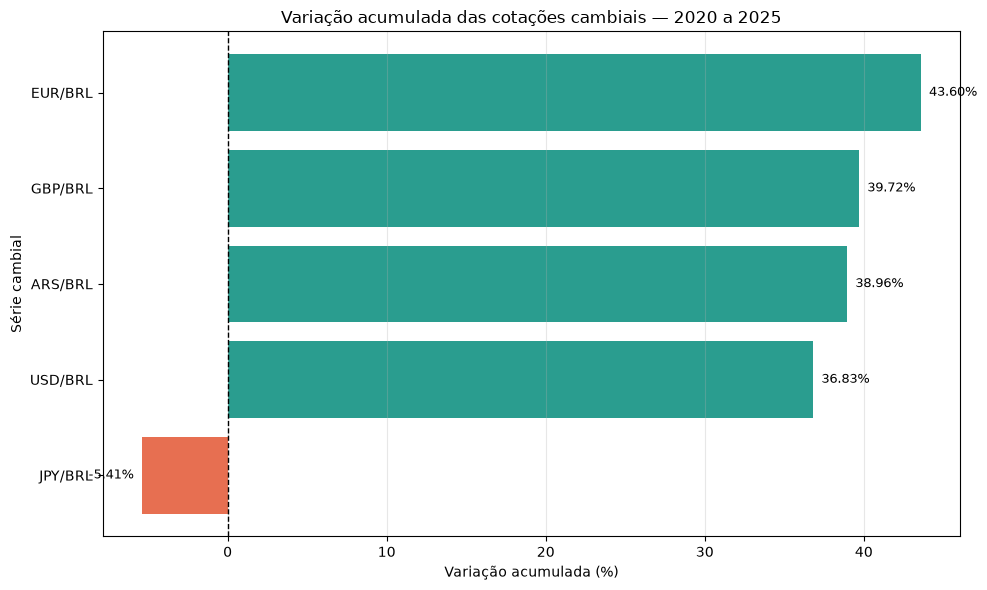

In [73]:
# Ordenar as moedas pela variação acumulada
resumo_variacao_ordenado = (
    resumo_variacao_cambio
    .sort_values("variacao_acumulada_pct")
    .reset_index(drop=True)
)

# Definir uma cor para valores positivos e outra para negativos
cores_barras = [
    "#2a9d8f" if valor >= 0 else "#e76f51"
    for valor in resumo_variacao_ordenado[
        "variacao_acumulada_pct"
    ]
]

plt.figure(figsize=(10, 6))

barras = plt.barh(
    resumo_variacao_ordenado["serie"],
    resumo_variacao_ordenado["variacao_acumulada_pct"],
    color=cores_barras
)

# Linha de referência em zero
plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

# Adicionar os valores nas barras
for barra, valor in zip(
    barras,
    resumo_variacao_ordenado["variacao_acumulada_pct"]
):
    deslocamento = 0.5 if valor >= 0 else -0.5
    alinhamento = "left" if valor >= 0 else "right"

    plt.text(
        valor + deslocamento,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}%",
        va="center",
        ha=alinhamento,
        fontsize=9
    )

plt.title(
    "Variação acumulada das cotações cambiais — 2020 a 2025"
)

plt.xlabel("Variação acumulada (%)")
plt.ylabel("Série cambial")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

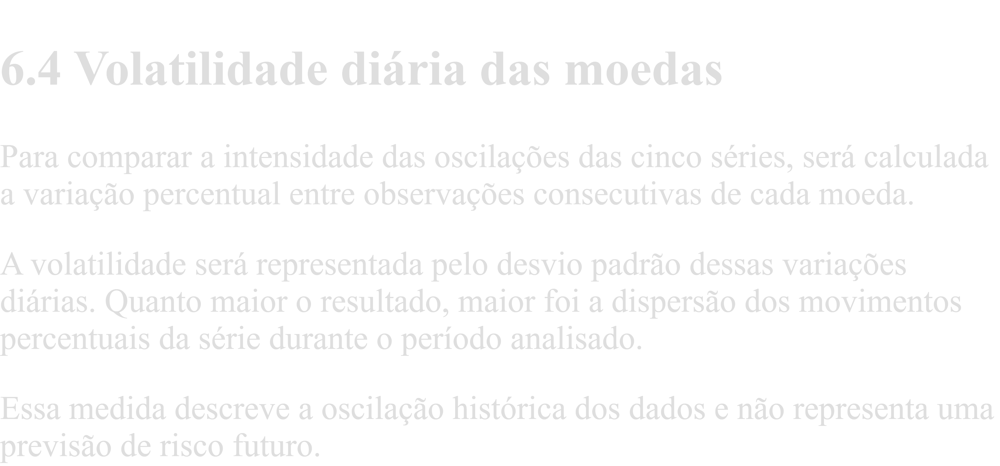

In [74]:
# Criar uma cópia para a análise de volatilidade
df_cambio_variacao = (
    df_cambio
    .sort_values(["serie", "data"])
    .reset_index(drop=True)
    .copy()
)

# Calcular a variação percentual dentro de cada série
df_cambio_variacao["variacao_diaria_pct"] = (
    df_cambio_variacao
    .groupby("serie")["valor"]
    .pct_change(fill_method=None)
    .mul(100)
)

df_cambio_variacao.head()


,serie,codigo_sgs,data,valor,variacao_diaria_pct
0,ARS/BRL,21632,2020-01-02,0.4304,NaN
1,ARS/BRL,21632,2020-01-03,0.4314,0.232342
2,ARS/BRL,21632,2020-01-06,0.4308,-0.139082
3,ARS/BRL,21632,2020-01-07,0.4321,0.301764
4,ARS/BRL,21632,2020-01-08,0.4302,-0.439713


In [75]:
nulos_variacao_por_serie = (
    df_cambio_variacao
    .groupby("serie")["variacao_diaria_pct"]
    .apply(lambda coluna: coluna.isna().sum())
    .reset_index(name="valores_nulos")
)

nulos_variacao_por_serie

,serie,valores_nulos
0,ARS/BRL,1
1,EUR/BRL,1
2,GBP/BRL,1
3,JPY/BRL,1
4,USD/BRL,1


In [76]:
volatilidade_cambio = (
    df_cambio_variacao
    .groupby("serie")
    .agg(
        observacoes_validas=(
            "variacao_diaria_pct",
            "count"
        ),
        variacao_media_pct=(
            "variacao_diaria_pct",
            "mean"
        ),
        volatilidade_pct=(
            "variacao_diaria_pct",
            "std"
        ),
        menor_variacao_pct=(
            "variacao_diaria_pct",
            "min"
        ),
        maior_variacao_pct=(
            "variacao_diaria_pct",
            "max"
        )
    )
    .reset_index()
    .sort_values(
        "volatilidade_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

volatilidade_cambio

,serie,observacoes_validas,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,JPY/BRL,1505,0.001781,1.048083,-6.405229,6.177387
1,ARS/BRL,1505,0.026355,0.948625,-4.144510,5.024175
2,GBP/BRL,1505,0.026405,0.915442,-4.417936,5.535979
3,USD/BRL,1506,0.024979,0.912384,-4.505270,4.482434
4,EUR/BRL,1505,0.028054,0.896463,-4.875226,5.085909


In [77]:
volatilidade_cambio_exibicao = (
    volatilidade_cambio.copy()
)

colunas_percentuais_cambio = [
    "variacao_media_pct",
    "volatilidade_pct",
    "menor_variacao_pct",
    "maior_variacao_pct"
]

volatilidade_cambio_exibicao[
    colunas_percentuais_cambio
] = volatilidade_cambio_exibicao[
    colunas_percentuais_cambio
].round(4)

volatilidade_cambio_exibicao

,serie,observacoes_validas,variacao_media_pct,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,JPY/BRL,1505,0.0018,1.0481,-6.4052,6.1774
1,ARS/BRL,1505,0.0264,0.9486,-4.1445,5.0242
2,GBP/BRL,1505,0.0264,0.9154,-4.4179,5.5360
3,USD/BRL,1506,0.0250,0.9124,-4.5053,4.4824
4,EUR/BRL,1505,0.0281,0.8965,-4.8752,5.0859


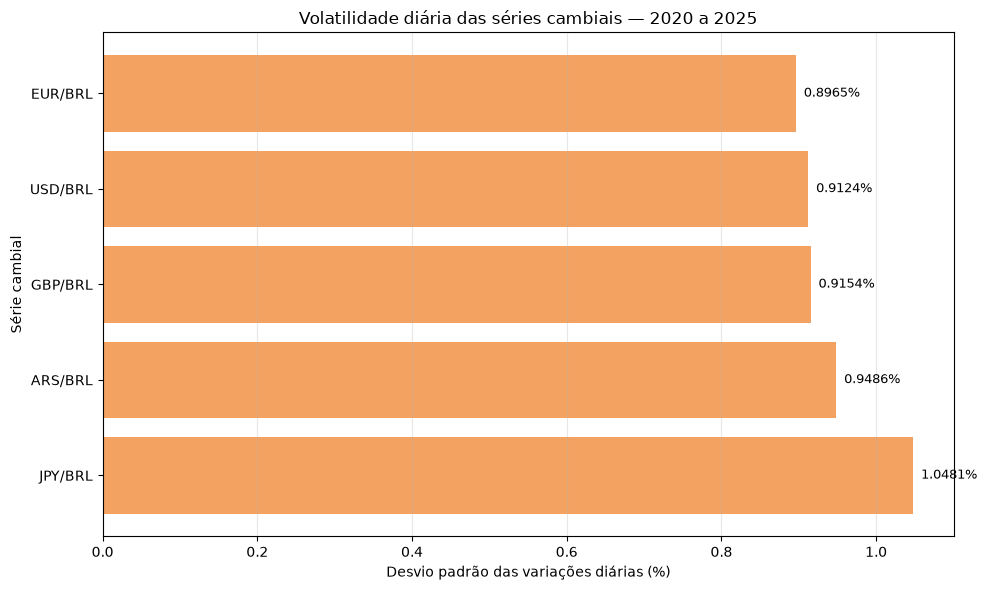

In [78]:
plt.figure(figsize=(10, 6))

barras = plt.barh(
    volatilidade_cambio["serie"],
    volatilidade_cambio["volatilidade_pct"],
    color="#f4a261"
)

for barra, valor in zip(
    barras,
    volatilidade_cambio["volatilidade_pct"]
):
    plt.text(
        barra.get_width() + 0.01,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.4f}%",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title(
    "Volatilidade diária das séries cambiais — 2020 a 2025"
)

plt.xlabel(
    "Desvio padrão das variações diárias (%)"
)

plt.ylabel("Série cambial")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

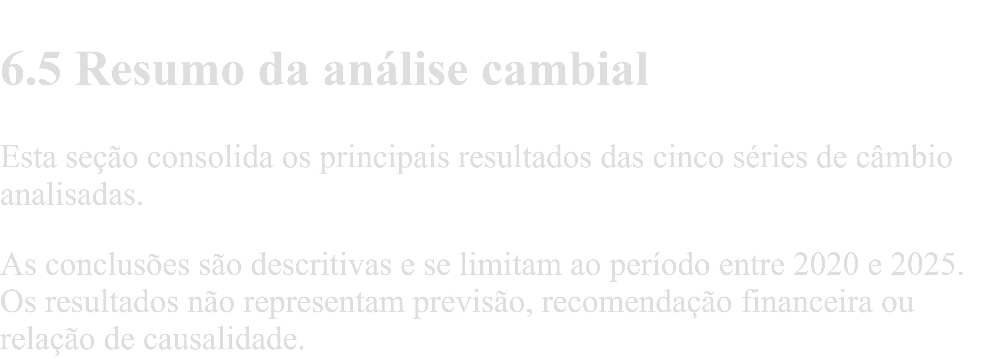

In [79]:
# Série com maior e menor variação acumulada
maior_variacao_acumulada = resumo_variacao_cambio.loc[
    resumo_variacao_cambio["variacao_acumulada_pct"].idxmax()
]

menor_variacao_acumulada = resumo_variacao_cambio.loc[
    resumo_variacao_cambio["variacao_acumulada_pct"].idxmin()
]

# Série com maior e menor volatilidade diária
maior_volatilidade_cambio = volatilidade_cambio.loc[
    volatilidade_cambio["volatilidade_pct"].idxmax()
]

menor_volatilidade_cambio = volatilidade_cambio.loc[
    volatilidade_cambio["volatilidade_pct"].idxmin()
]

print("DESTAQUES DA ANÁLISE CAMBIAL\n")

print(
    "Maior variação acumulada:"
    f"\nSérie: {maior_variacao_acumulada['serie']}"
    f"\nVariação: "
    f"{maior_variacao_acumulada['variacao_acumulada_pct']:.2f}%"
)

print(
    "\n\nMenor variação acumulada:"
    f"\nSérie: {menor_variacao_acumulada['serie']}"
    f"\nVariação: "
    f"{menor_variacao_acumulada['variacao_acumulada_pct']:.2f}%"
)

print(
    "\n\nMaior volatilidade diária:"
    f"\nSérie: {maior_volatilidade_cambio['serie']}"
    f"\nVolatilidade: "
    f"{maior_volatilidade_cambio['volatilidade_pct']:.4f}%"
)

print(
    "\n\nMenor volatilidade diária:"
    f"\nSérie: {menor_volatilidade_cambio['serie']}"
    f"\nVolatilidade: "
    f"{menor_volatilidade_cambio['volatilidade_pct']:.4f}%"
)

DESTAQUES DA ANÁLISE CAMBIAL

Maior variação acumulada:
Série: EUR/BRL
Variação: 43.60%


Menor variação acumulada:
Série: JPY/BRL
Variação: -5.41%


Maior volatilidade diária:
Série: JPY/BRL
Volatilidade: 1.0481%


Menor volatilidade diária:
Série: EUR/BRL
Volatilidade: 0.8965%


In [80]:
resumo_eda_cambio = (
    resumo_variacao_cambio[
        [
            "serie",
            "data_inicial",
            "valor_inicial",
            "data_final",
            "valor_final",
            "variacao_acumulada_pct"
        ]
    ]
    .merge(
        volatilidade_cambio[
            [
                "serie",
                "observacoes_validas",
                "volatilidade_pct",
                "menor_variacao_pct",
                "maior_variacao_pct"
            ]
        ],
        on="serie",
        how="left"
    )
)

resumo_eda_cambio = resumo_eda_cambio.sort_values(
    "serie"
).reset_index(drop=True)

resumo_eda_cambio

,serie,data_inicial,valor_inicial,data_final,valor_final,variacao_acumulada_pct,observacoes_validas,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,ARS/BRL,2020-01-02,0.43040,2025-12-31,0.59810,38.963755,1505,0.948625,-4.144510,5.024175
1,EUR/BRL,2020-01-02,4.50510,2025-12-31,6.46920,43.597256,1505,0.896463,-4.875226,5.085909
2,GBP/BRL,2020-01-02,5.30450,2025-12-31,7.41120,39.715336,1505,0.915442,-4.417936,5.535979
3,JPY/BRL,2020-01-02,0.03715,2025-12-31,0.03514,-5.410498,1505,1.048083,-6.405229,6.177387
4,USD/BRL,2020-01-02,4.02130,2025-12-31,5.50240,36.831373,1506,0.912384,-4.505270,4.482434


In [81]:
resumo_eda_cambio_exibicao = resumo_eda_cambio.copy()

colunas_decimais = [
    "valor_inicial",
    "valor_final",
    "variacao_acumulada_pct",
    "volatilidade_pct",
    "menor_variacao_pct",
    "maior_variacao_pct"
]

resumo_eda_cambio_exibicao[colunas_decimais] = (
    resumo_eda_cambio_exibicao[colunas_decimais]
    .round(4)
)

resumo_eda_cambio_exibicao

,serie,data_inicial,valor_inicial,data_final,valor_final,variacao_acumulada_pct,observacoes_validas,volatilidade_pct,menor_variacao_pct,maior_variacao_pct
0,ARS/BRL,2020-01-02,0.4304,2025-12-31,0.5981,38.9638,1505,0.9486,-4.1445,5.0242
1,EUR/BRL,2020-01-02,4.5051,2025-12-31,6.4692,43.5973,1505,0.8965,-4.8752,5.0859
2,GBP/BRL,2020-01-02,5.3045,2025-12-31,7.4112,39.7153,1505,0.9154,-4.4179,5.5360
3,JPY/BRL,2020-01-02,0.0372,2025-12-31,0.0351,-5.4105,1505,1.0481,-6.4052,6.1774
4,USD/BRL,2020-01-02,4.0213,2025-12-31,5.5024,36.8314,1506,0.9124,-4.5053,4.4824


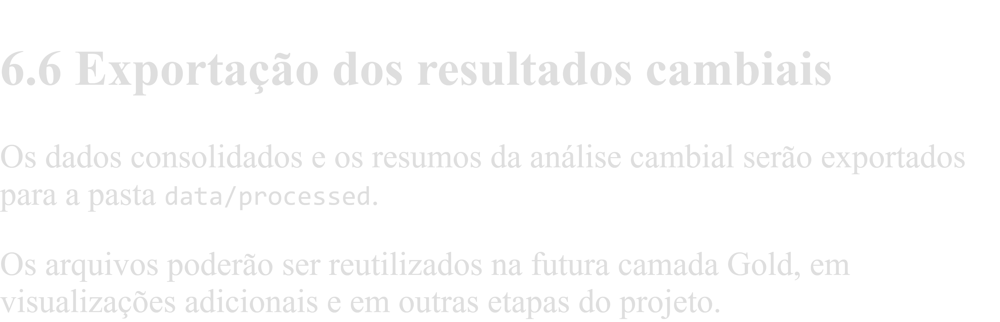

In [82]:
# A variável pasta_processados foi criada na análise do dólar
pasta_processados.mkdir(
    parents=True,
    exist_ok=True
)

# Conjunto consolidado das cinco moedas
df_cambio.to_csv(
    pasta_processados / "cambio_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Série normalizada em índice base 100
df_cambio_normalizado.to_csv(
    pasta_processados / "cambio_base_100_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Variação acumulada
resumo_variacao_cambio.to_csv(
    pasta_processados
    / "variacao_acumulada_cambio_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Volatilidade das moedas
volatilidade_cambio.to_csv(
    pasta_processados
    / "volatilidade_cambio_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

# Resumo geral cambial
resumo_eda_cambio.to_csv(
    pasta_processados
    / "resumo_eda_cambio_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Resultados cambiais exportados com sucesso!")

Resultados cambiais exportados com sucesso!


In [83]:
arquivos_cambio_exportados = sorted(
    pasta_processados.glob("*cambio*.csv")
)

print("Arquivos cambiais exportados:\n")

for arquivo in arquivos_cambio_exportados:
    print(f"- {arquivo.name}")

Arquivos cambiais exportados:

- cambio_2020_2025.csv
- cambio_base_100_2020_2025.csv
- resumo_eda_cambio_2020_2025.csv
- variacao_acumulada_cambio_2020_2025.csv
- volatilidade_cambio_2020_2025.csv


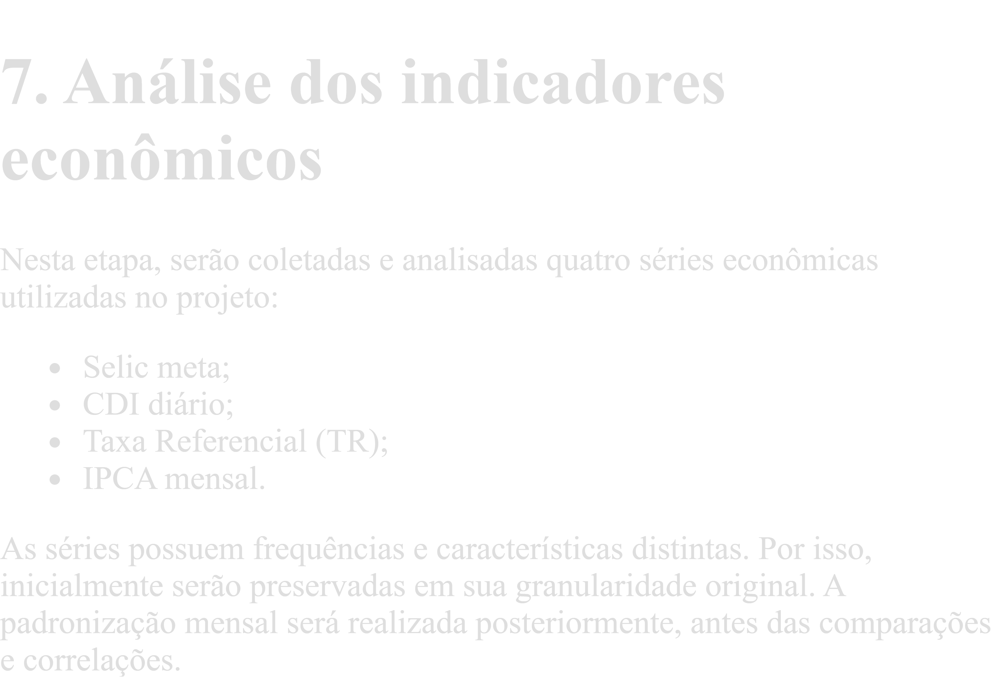

In [84]:
series_indicadores = {
    "SELIC": 432,
    "CDI": 12,
    "TR": 226,
    "IPCA": 433
}

data_inicial_indicadores = "01/01/2020"
data_final_indicadores = "31/12/2025"

series_indicadores

{'SELIC': 432, 'CDI': 12, 'TR': 226, 'IPCA': 433}

In [85]:
dataframes_indicadores = []
falhas_indicadores = []

for nome_serie, codigo_serie in series_indicadores.items():

    print(f"\nColetando {nome_serie}...")

    try:
        dataframe_serie = coletar_serie_bacen(
            codigo=codigo_serie,
            nome=nome_serie,
            data_inicial=data_inicial_indicadores,
            data_final=data_final_indicadores
        )

        dataframes_indicadores.append(dataframe_serie)

    except Exception as erro:
        falhas_indicadores.append({
            "serie": nome_serie,
            "codigo_sgs": codigo_serie,
            "erro": str(erro)
        })

        print(
            f"Não foi possível coletar {nome_serie}."
        )

    # Evitar consultas consecutivas muito rápidas
    time.sleep(2)

print("\nColeta finalizada.")

print(
    "Séries coletadas com sucesso:",
    len(dataframes_indicadores)
)

print(
    "Séries com falha:",
    len(falhas_indicadores)
)


Coletando SELIC...
  Tentativa 1/3 para SELIC...
  Status HTTP: 200
  SELIC: 2192 registros coletados.

Coletando CDI...
  Tentativa 1/3 para CDI...
  Status HTTP: 200
  CDI: 1507 registros coletados.

Coletando TR...
  Tentativa 1/3 para TR...
  Status HTTP: 200
  TR: 2232 registros coletados.

Coletando IPCA...
  Tentativa 1/3 para IPCA...
  Status HTTP: 200
  IPCA: 72 registros coletados.

Coleta finalizada.
Séries coletadas com sucesso: 4
Séries com falha: 0


In [86]:
if falhas_indicadores:

    df_falhas_indicadores = pd.DataFrame(
        falhas_indicadores
    )

    display(df_falhas_indicadores)

else:
    print(
        "Todos os indicadores foram coletados "
        "com sucesso."
    )

Todos os indicadores foram coletados com sucesso.


In [87]:
if dataframes_indicadores:

    df_indicadores = pd.concat(
        dataframes_indicadores,
        ignore_index=True
    )

    df_indicadores = (
        df_indicadores
        .sort_values(["serie", "data"])
        .reset_index(drop=True)
    )

    print(
        "Quantidade total de registros:",
        len(df_indicadores)
    )

    print("\nSéries presentes:")

    print(
        df_indicadores["serie"]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

else:
    print(
        "Nenhum indicador foi coletado."
    )

Quantidade total de registros: 6003

Séries presentes:
['CDI', 'IPCA', 'SELIC', 'TR']


In [88]:
resumo_cobertura_indicadores = (
    df_indicadores
    .groupby(["serie", "codigo_sgs"])
    .agg(
        quantidade_registros=("valor", "count"),
        data_inicial=("data", "min"),
        data_final=("data", "max"),
        menor_valor=("valor", "min"),
        maior_valor=("valor", "max")
    )
    .reset_index()
)

resumo_cobertura_indicadores

,serie,codigo_sgs,quantidade_registros,data_inicial,data_final,menor_valor,maior_valor
0,CDI,12,1507,2020-01-02,2025-12-31,0.007469,0.055131
1,IPCA,433,72,2020-01-01,2025-12-01,-0.680000,1.620000
2,SELIC,432,2192,2020-01-01,2025-12-31,2.000000,15.000000
3,TR,226,2232,2020-01-01,2025-12-31,0.000000,0.244300


In [89]:
qualidade_indicadores = (
    df_indicadores
    .groupby("serie")
    .agg(
        registros=("valor", "size"),
        datas_nulas=(
            "data",
            lambda coluna: coluna.isna().sum()
        ),
        valores_nulos=(
            "valor",
            lambda coluna: coluna.isna().sum()
        )
    )
    .reset_index()
)

duplicidades_indicadores = (
    df_indicadores
    .duplicated(subset=["serie", "data"])
    .sum()
)

display(qualidade_indicadores)

print(
    "Duplicidades por combinação série e data:",
    duplicidades_indicadores
)

,serie,registros,datas_nulas,valores_nulos
0,CDI,1507,0,0
1,IPCA,72,0,0
2,SELIC,2192,0,0
3,TR,2232,0,0


Duplicidades por combinação série e data: 40


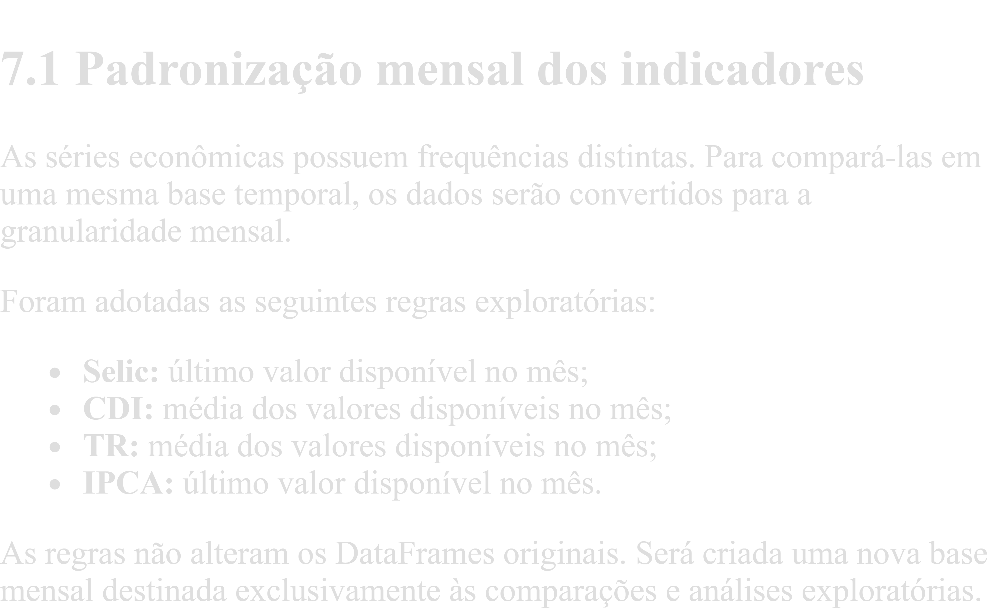

In [90]:
df_selic = (
    df_indicadores
    .query("serie == 'SELIC'")
    .sort_values("data")
    .copy()
)

df_cdi = (
    df_indicadores
    .query("serie == 'CDI'")
    .sort_values("data")
    .copy()
)

df_tr = (
    df_indicadores
    .query("serie == 'TR'")
    .sort_values("data")
    .copy()
)

df_ipca = (
    df_indicadores
    .query("serie == 'IPCA'")
    .sort_values("data")
    .copy()
)

print("Registros por série:")
print("Selic:", len(df_selic))
print("CDI:", len(df_cdi))
print("TR:", len(df_tr))
print("IPCA:", len(df_ipca))

Registros por série:
Selic: 2192
CDI: 1507
TR: 2232
IPCA: 72


In [91]:
for dataframe in [
    df_selic,
    df_cdi,
    df_tr,
    df_ipca
]:
    dataframe["mes"] = (
        dataframe["data"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

In [102]:
# Selic: último valor disponível do mês
selic_mensal = (
    df_selic
    .groupby("mes", as_index=False)
    .agg(selic=("valor", "last"))
)

# CDI: média dos valores disponíveis no mês
# Converter a taxa diária do CDI em taxa anual equivalente
df_cdi["cdi_anual_equivalente"] = (
    (
        1 + df_cdi["valor"] / 100
    ) ** 252
    - 1
) * 100

# Calcular a média mensal da taxa anual equivalente
cdi_mensal = (
    df_cdi
    .groupby("mes", as_index=False)
    .agg(
        cdi=("cdi_anual_equivalente", "mean")
    )
)

cdi_mensal.head()

# TR: média dos valores disponíveis no mês
tr_mensal = (
    df_tr
    .groupby("mes", as_index=False)
    .agg(tr=("valor", "mean"))
)

# IPCA: último valor disponível do mês
ipca_mensal = (
    df_ipca
    .groupby("mes", as_index=False)
    .agg(ipca=("valor", "last"))
)

print("Meses por série:")
print("Selic:", len(selic_mensal))
print("CDI:", len(cdi_mensal))
print("TR:", len(tr_mensal))
print("IPCA:", len(ipca_mensal))

Meses por série:
Selic: 72
CDI: 72
TR: 72
IPCA: 72


In [103]:
df_indicadores_mensais = (
    selic_mensal
    .merge(
        cdi_mensal,
        on="mes",
        how="outer"
    )
    .merge(
        tr_mensal,
        on="mes",
        how="outer"
    )
    .merge(
        ipca_mensal,
        on="mes",
        how="outer"
    )
    .sort_values("mes")
    .reset_index(drop=True)
)

df_indicadores_mensais.head()

,mes,selic,cdi,tr,ipca
0,2020-01-01,4.50,4.400116,0.0,0.21
1,2020-02-01,4.25,4.191684,0.0,0.25
2,2020-03-01,3.75,3.945446,0.0,0.07
3,2020-04-01,3.75,3.649983,0.0,-0.31
4,2020-05-01,3.00,3.012526,0.0,-0.38


In [104]:
print(
    "Quantidade de meses:",
    len(df_indicadores_mensais)
)

print("\nPeríodo mensal:")
print(
    "Inicial:",
    df_indicadores_mensais["mes"].min()
)
print(
    "Final:",
    df_indicadores_mensais["mes"].max()
)

print("\nValores nulos por coluna:")
print(
    df_indicadores_mensais
    .isna()
    .sum()
)

print("\nMeses duplicados:")
print(
    df_indicadores_mensais
    .duplicated(subset=["mes"])
    .sum()
)

Quantidade de meses: 72

Período mensal:
Inicial: 2020-01-01 00:00:00
Final: 2025-12-01 00:00:00

Valores nulos por coluna:
mes      0
selic    0
cdi      0
tr       0
ipca     0
dtype: int64

Meses duplicados:
0


In [95]:
periodo_mensal_esperado = pd.date_range(
    start="2020-01-01",
    end="2025-12-01",
    freq="MS"
)

print(
    "Quantidade esperada de meses:",
    len(periodo_mensal_esperado)
)

print(
    "Quantidade encontrada:",
    len(df_indicadores_mensais)
)

Quantidade esperada de meses: 72
Quantidade encontrada: 72


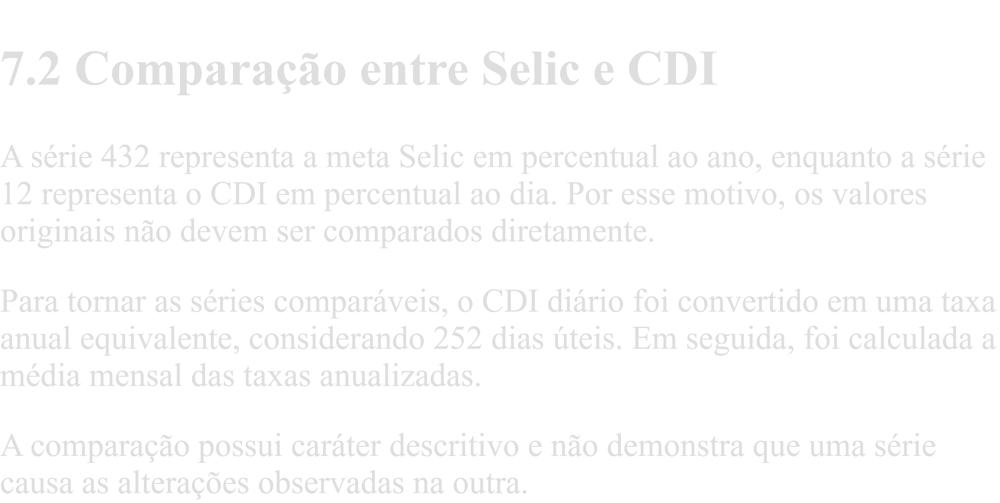

In [105]:
ccomparacao_selic_cdi_valida = (
    df_indicadores_mensais[
        ["mes", "selic", "cdi"]
    ]
    .dropna(subset=["selic", "cdi"])
    .sort_values("mes")
    .reset_index(drop=True)
)

comparacao_selic_cdi_valida.head()


,mes,selic,cdi,diferenca_selic_cdi
0,2020-01-01,4.50,0.017089,4.482911
1,2020-02-01,4.25,0.016296,4.233704
2,2020-03-01,3.75,0.015356,3.734644
3,2020-04-01,3.75,0.014227,3.735773
4,2020-05-01,3.00,0.011777,2.988223


In [97]:
comparacao_selic_cdi_valida = (
    comparacao_selic_cdi
    .dropna(subset=["selic", "cdi"])
    .sort_values("mes")
    .reset_index(drop=True)
)

print(
    "Quantidade de meses utilizados:",
    len(comparacao_selic_cdi_valida)
)

print(
    "Período utilizado:",
    comparacao_selic_cdi_valida["mes"].min(),
    "a",
    comparacao_selic_cdi_valida["mes"].max()
)

comparacao_selic_cdi_valida.head()

Quantidade de meses utilizados: 72
Período utilizado: 2020-01-01 00:00:00 a 2025-12-01 00:00:00


,mes,selic,cdi
0,2020-01-01,4.50,0.017089
1,2020-02-01,4.25,0.016296
2,2020-03-01,3.75,0.015356
3,2020-04-01,3.75,0.014227
4,2020-05-01,3.00,0.011777


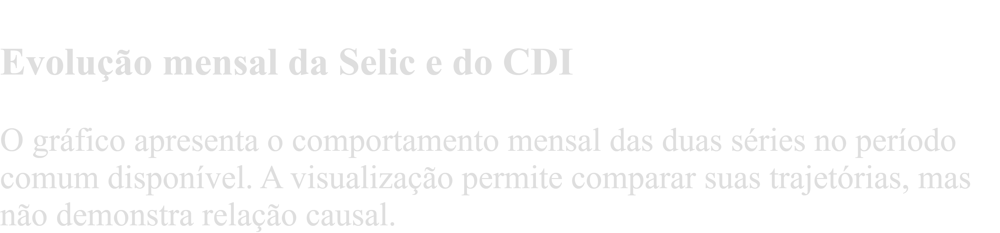

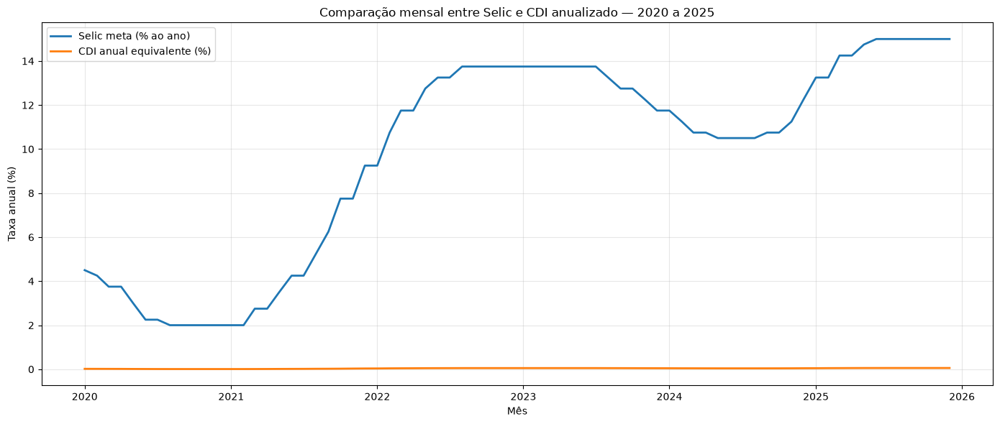

In [106]:
plt.figure(figsize=(14, 6))

plt.plot(
    comparacao_selic_cdi_valida["mes"],
    comparacao_selic_cdi_valida["selic"],
    linewidth=2,
    label="Selic meta (% ao ano)"
)

plt.plot(
    comparacao_selic_cdi_valida["mes"],
    comparacao_selic_cdi_valida["cdi"],
    linewidth=2,
    label="CDI anual equivalente (%)"
)

plt.title(
    "Comparação mensal entre Selic e CDI anualizado — 2020 a 2025"
)

plt.xlabel("Mês")
plt.ylabel("Taxa anual (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [99]:
comparacao_selic_cdi_valida["diferenca_selic_cdi"] = (
    comparacao_selic_cdi_valida["selic"]
    - comparacao_selic_cdi_valida["cdi"]
)

comparacao_selic_cdi_valida.head()

,mes,selic,cdi,diferenca_selic_cdi
0,2020-01-01,4.50,0.017089,4.482911
1,2020-02-01,4.25,0.016296,4.233704
2,2020-03-01,3.75,0.015356,3.734644
3,2020-04-01,3.75,0.014227,3.735773
4,2020-05-01,3.00,0.011777,2.988223


In [100]:
estatisticas_diferenca_selic_cdi = (
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi"
    ]
    .describe()
)

estatisticas_diferenca_selic_cdi

count    72.000000
mean      9.800539
std       4.617960
min       1.992392
25%       4.421025
50%      11.456941
75%      13.699212
max      14.945431
Name: diferenca_selic_cdi, dtype: float64

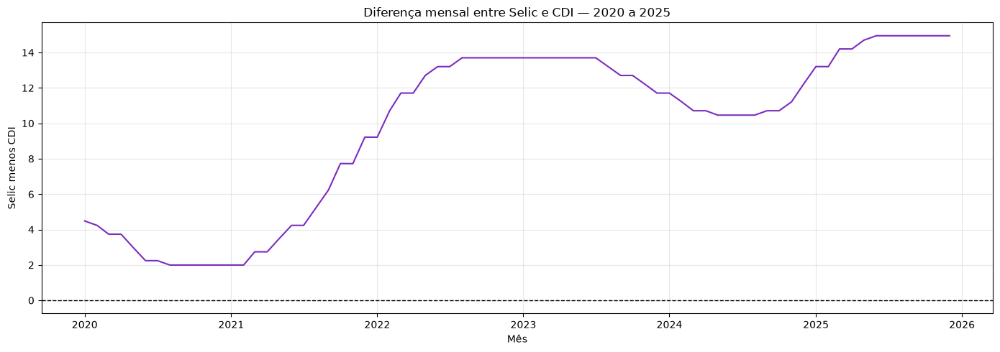

In [107]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparacao_selic_cdi_valida["mes"],
    comparacao_selic_cdi_valida["diferenca_selic_cdi"],
    color="#7b2cbf",
    linewidth=1.5
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Diferença mensal entre Selic e CDI — 2020 a 2025"
)

plt.xlabel("Mês")
plt.ylabel("Selic menos CDI")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [108]:
comparacao_selic_cdi = (
    df_indicadores_mensais[
        ["mes", "selic", "cdi"]
    ]
    .copy()
)

print("Quantidade total de meses:", len(comparacao_selic_cdi))

print("\nValores nulos por coluna:")
print(
    comparacao_selic_cdi[
        ["selic", "cdi"]
    ].isna().sum()
)

Quantidade total de meses: 72

Valores nulos por coluna:
selic    0
cdi      0
dtype: int64


In [109]:
comparacao_selic_cdi_valida = (
    comparacao_selic_cdi
    .dropna(subset=["selic", "cdi"])
    .sort_values("mes")
    .reset_index(drop=True)
)

print(
    "Meses utilizados na comparação:",
    len(comparacao_selic_cdi_valida)
)

print(
    "Período utilizado:",
    comparacao_selic_cdi_valida["mes"].min(),
    "a",
    comparacao_selic_cdi_valida["mes"].max()
)

comparacao_selic_cdi_valida.head()



Meses utilizados na comparação: 72
Período utilizado: 2020-01-01 00:00:00 a 2025-12-01 00:00:00


,mes,selic,cdi
0,2020-01-01,4.50,4.400116
1,2020-02-01,4.25,4.191684
2,2020-03-01,3.75,3.945446
3,2020-04-01,3.75,3.649983
4,2020-05-01,3.00,3.012526


In [110]:
validacao_faixas_selic_cdi = pd.DataFrame({
    "serie": ["Selic", "CDI anual equivalente"],
    "minimo": [
        comparacao_selic_cdi_valida["selic"].min(),
        comparacao_selic_cdi_valida["cdi"].min()
    ],
    "media": [
        comparacao_selic_cdi_valida["selic"].mean(),
        comparacao_selic_cdi_valida["cdi"].mean()
    ],
    "mediana": [
        comparacao_selic_cdi_valida["selic"].median(),
        comparacao_selic_cdi_valida["cdi"].median()
    ],
    "maximo": [
        comparacao_selic_cdi_valida["selic"].max(),
        comparacao_selic_cdi_valida["cdi"].max()
    ]
})

validacao_faixas_selic_cdi.round(4)

,serie,minimo,media,mediana,maximo
0,Selic,2.0000,9.8368,11.50,15.0
1,CDI anual equivalente,1.8999,9.6662,11.15,14.9


In [111]:
comparacao_selic_cdi_valida["diferenca_selic_cdi_pp"] = (
    comparacao_selic_cdi_valida["selic"]
    - comparacao_selic_cdi_valida["cdi"]
)

comparacao_selic_cdi_valida.head()

,mes,selic,cdi,diferenca_selic_cdi_pp
0,2020-01-01,4.50,4.400116,0.099884
1,2020-02-01,4.25,4.191684,0.058316
2,2020-03-01,3.75,3.945446,-0.195446
3,2020-04-01,3.75,3.649983,0.100017
4,2020-05-01,3.00,3.012526,-0.012526


In [112]:
print(
    "Valores nulos na diferença:",
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ].isna().sum()
)

print(
    "Valores infinitos na diferença:",
    np.isinf(
        comparacao_selic_cdi_valida[
            "diferenca_selic_cdi_pp"
        ]
    ).sum()
)

print(
    "Meses duplicados:",
    comparacao_selic_cdi_valida
    .duplicated(subset=["mes"])
    .sum()
)

Valores nulos na diferença: 0
Valores infinitos na diferença: 0
Meses duplicados: 0


In [113]:
estatisticas_diferenca_selic_cdi = (
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ]
    .describe()
)

estatisticas_diferenca_selic_cdi

count    72.000000
mean      0.170597
std       0.260172
min      -0.328626
25%       0.099964
50%       0.100019
75%       0.172756
max       1.449896
Name: diferenca_selic_cdi_pp, dtype: float64

In [114]:
print("ESTATÍSTICAS DA DIFERENÇA SELIC − CDI\n")

print(
    f"Quantidade de meses: "
    f"{estatisticas_diferenca_selic_cdi['count']:.0f}"
)

print(
    f"Diferença média: "
    f"{estatisticas_diferenca_selic_cdi['mean']:.4f} p.p."
)

print(
    f"Mediana: "
    f"{estatisticas_diferenca_selic_cdi['50%']:.4f} p.p."
)

print(
    f"Menor diferença: "
    f"{estatisticas_diferenca_selic_cdi['min']:.4f} p.p."
)

print(
    f"Maior diferença: "
    f"{estatisticas_diferenca_selic_cdi['max']:.4f} p.p."
)

print(
    f"Desvio padrão: "
    f"{estatisticas_diferenca_selic_cdi['std']:.4f} p.p."
)

ESTATÍSTICAS DA DIFERENÇA SELIC − CDI

Quantidade de meses: 72
Diferença média: 0.1706 p.p.
Mediana: 0.1000 p.p.
Menor diferença: -0.3286 p.p.
Maior diferença: 1.4499 p.p.
Desvio padrão: 0.2602 p.p.


In [115]:
mes_maior_diferenca = comparacao_selic_cdi_valida.loc[
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ].idxmax()
]

mes_menor_diferenca = comparacao_selic_cdi_valida.loc[
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ].idxmin()
]

print("MAIOR DIFERENÇA SELIC − CDI")
print(f"Mês: {mes_maior_diferenca['mes']:%m/%Y}")
print(f"Selic: {mes_maior_diferenca['selic']:.4f}% a.a.")
print(f"CDI: {mes_maior_diferenca['cdi']:.4f}% a.a.")
print(
    f"Diferença: "
    f"{mes_maior_diferenca['diferenca_selic_cdi_pp']:.4f} p.p."
)

print("\nMENOR DIFERENÇA SELIC − CDI")
print(f"Mês: {mes_menor_diferenca['mes']:%m/%Y}")
print(f"Selic: {mes_menor_diferenca['selic']:.4f}% a.a.")
print(f"CDI: {mes_menor_diferenca['cdi']:.4f}% a.a.")
print(
    f"Diferença: "
    f"{mes_menor_diferenca['diferenca_selic_cdi_pp']:.4f} p.p."
)

MAIOR DIFERENÇA SELIC − CDI
Mês: 10/2021
Selic: 7.7500% a.a.
CDI: 6.3001% a.a.
Diferença: 1.4499 p.p.

MENOR DIFERENÇA SELIC − CDI
Mês: 06/2020
Selic: 2.2500% a.a.
CDI: 2.5786% a.a.
Diferença: -0.3286 p.p.


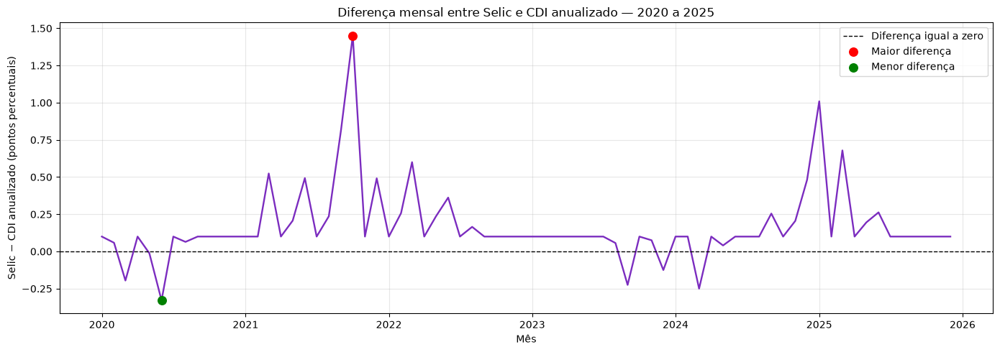

In [116]:
plt.figure(figsize=(14, 5))

plt.plot(
    comparacao_selic_cdi_valida["mes"],
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ],
    color="#7b2cbf",
    linewidth=1.7
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Diferença igual a zero"
)

plt.scatter(
    mes_maior_diferenca["mes"],
    mes_maior_diferenca["diferenca_selic_cdi_pp"],
    color="red",
    s=70,
    label="Maior diferença",
    zorder=3
)

plt.scatter(
    mes_menor_diferenca["mes"],
    mes_menor_diferenca["diferenca_selic_cdi_pp"],
    color="green",
    s=70,
    label="Menor diferença",
    zorder=3
)

plt.title(
    "Diferença mensal entre Selic e CDI anualizado — 2020 a 2025"
)

plt.xlabel("Mês")
plt.ylabel("Selic − CDI anualizado (pontos percentuais)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [117]:
amostra_validacao = (
    comparacao_selic_cdi_valida
    .head(5)
    .copy()
)

amostra_validacao["diferenca_recalculada"] = (
    amostra_validacao["selic"]
    - amostra_validacao["cdi"]
)

amostra_validacao["calculo_consistente"] = np.isclose(
    amostra_validacao["diferenca_selic_cdi_pp"],
    amostra_validacao["diferenca_recalculada"]
)

amostra_validacao[
    [
        "mes",
        "selic",
        "cdi",
        "diferenca_selic_cdi_pp",
        "diferenca_recalculada",
        "calculo_consistente"
    ]
]

,mes,selic,cdi,diferenca_selic_cdi_pp,diferenca_recalculada,calculo_consistente
0,2020-01-01,4.50,4.400116,0.099884,0.099884,True
1,2020-02-01,4.25,4.191684,0.058316,0.058316,True
2,2020-03-01,3.75,3.945446,-0.195446,-0.195446,True
3,2020-04-01,3.75,3.649983,0.100017,0.100017,True
4,2020-05-01,3.00,3.012526,-0.012526,-0.012526,True


In [118]:
calculo_consistente_toda_base = np.isclose(
    comparacao_selic_cdi_valida[
        "diferenca_selic_cdi_pp"
    ],
    (
        comparacao_selic_cdi_valida["selic"]
        - comparacao_selic_cdi_valida["cdi"]
    )
).all()

print(
    "Diferença validada em todos os meses:",
    calculo_consistente_toda_base
)

Diferença validada em todos os meses: True


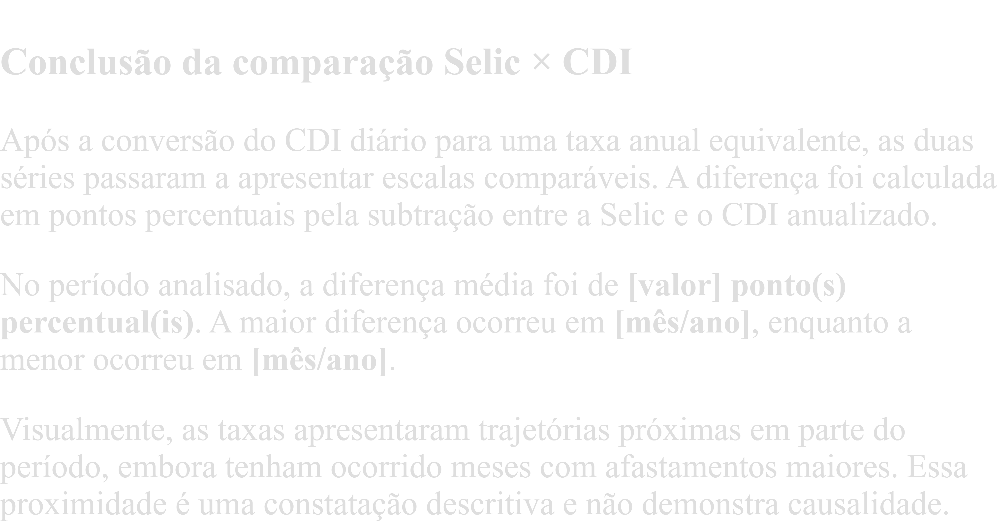

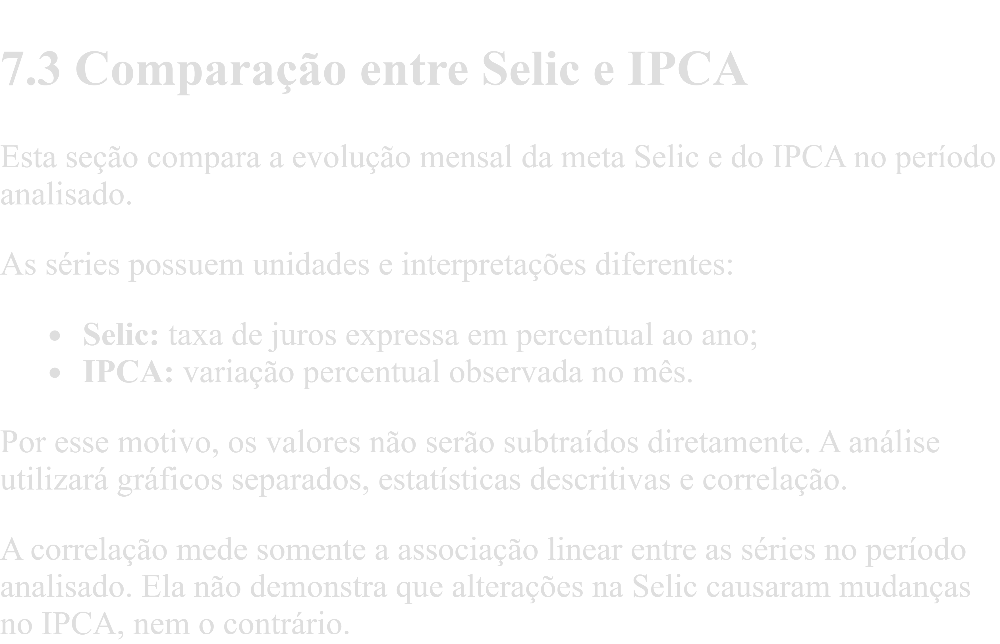

In [121]:
# ============================================================
# COMPARAÇÃO ENTRE SELIC E IPCA
# ============================================================

# 1. Selecionar as colunas necessárias
comparacao_selic_ipca = (
    df_indicadores_mensais[
        ["mes", "selic", "ipca"]
    ]
    .copy()
)

# 2. Garantir que os valores estejam em formato numérico
comparacao_selic_ipca["selic"] = pd.to_numeric(
    comparacao_selic_ipca["selic"],
    errors="coerce"
)

comparacao_selic_ipca["ipca"] = pd.to_numeric(
    comparacao_selic_ipca["ipca"],
    errors="coerce"
)

# 3. Ordenar cronologicamente
comparacao_selic_ipca = (
    comparacao_selic_ipca
    .sort_values("mes")
    .reset_index(drop=True)
)

# 4. Verificar a cobertura antes de excluir valores ausentes
print("COBERTURA INICIAL\n")

print(
    "Quantidade total de meses:",
    len(comparacao_selic_ipca)
)

print("\nValores nulos por coluna:")
print(
    comparacao_selic_ipca[
        ["selic", "ipca"]
    ].isna().sum()
)

print(
    "\nMeses com Selic e IPCA disponíveis:",
    comparacao_selic_ipca[
        ["selic", "ipca"]
    ].notna().all(axis=1).sum()
)

# 5. Manter somente os meses com as duas séries disponíveis
comparacao_selic_ipca_valida = (
    comparacao_selic_ipca
    .dropna(subset=["selic", "ipca"])
    .sort_values("mes")
    .reset_index(drop=True)
)

print("\nBASE VÁLIDA PARA COMPARAÇÃO\n")

print(
    "Quantidade de meses utilizados:",
    len(comparacao_selic_ipca_valida)
)

print(
    "Data inicial:",
    comparacao_selic_ipca_valida["mes"].min()
)

print(
    "Data final:",
    comparacao_selic_ipca_valida["mes"].max()
)

print(
    "Meses duplicados:",
    comparacao_selic_ipca_valida
    .duplicated(subset=["mes"])
    .sum()
)

# 6. Verificar valores infinitos
quantidade_infinitos = np.isinf(
    comparacao_selic_ipca_valida[
        ["selic", "ipca"]
    ]
).sum()

print("\nValores infinitos:")
print(quantidade_infinitos)

# 7. Exibir os primeiros registros
display(
    comparacao_selic_ipca_valida.head()
)

COBERTURA INICIAL

Quantidade total de meses: 72

Valores nulos por coluna:
selic    0
ipca     0
dtype: int64

Meses com Selic e IPCA disponíveis: 72

BASE VÁLIDA PARA COMPARAÇÃO

Quantidade de meses utilizados: 72
Data inicial: 2020-01-01 00:00:00
Data final: 2025-12-01 00:00:00
Meses duplicados: 0

Valores infinitos:
selic    0
ipca     0
dtype: int64


,mes,selic,ipca
0,2020-01-01,4.50,0.21
1,2020-02-01,4.25,0.25
2,2020-03-01,3.75,0.07
3,2020-04-01,3.75,-0.31
4,2020-05-01,3.00,-0.38


In [122]:
# ============================================================
# ESTATÍSTICAS DESCRITIVAS
# ============================================================

estatisticas_selic_ipca = (
    comparacao_selic_ipca_valida[
        ["selic", "ipca"]
    ]
    .describe()
    .transpose()
    .reset_index()
    .rename(columns={"index": "serie"})
)

estatisticas_selic_ipca_exibicao = (
    estatisticas_selic_ipca.copy()
)

colunas_estatisticas = [
    "mean",
    "std",
    "min",
    "25%",
    "50%",
    "75%",
    "max"
]

estatisticas_selic_ipca_exibicao[
    colunas_estatisticas
] = estatisticas_selic_ipca_exibicao[
    colunas_estatisticas
].round(4)

estatisticas_selic_ipca_exibicao

,serie,count,mean,std,min,25%,50%,75%,max
0,selic,72.0,9.8368,4.6349,2.00,4.4375,11.500,13.750,15.00
1,ipca,72.0,0.4608,0.4252,-0.68,0.2375,0.425,0.715,1.62


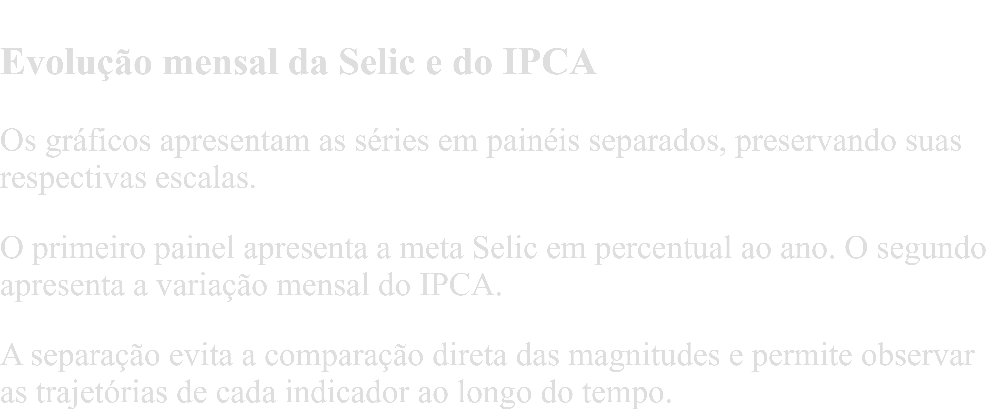

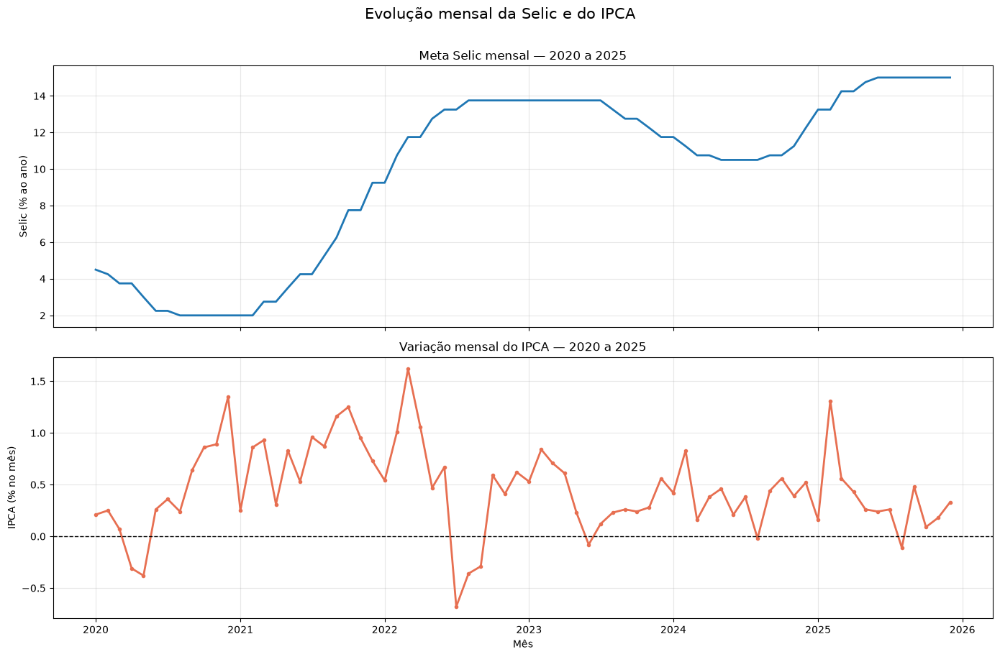

In [123]:
# ============================================================
# GRÁFICO EM DOIS PAINÉIS
# ============================================================

fig, eixos = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(14, 9),
    sharex=True
)

# Painel da Selic
eixos[0].plot(
    comparacao_selic_ipca_valida["mes"],
    comparacao_selic_ipca_valida["selic"],
    color="#1f77b4",
    linewidth=2
)

eixos[0].set_title(
    "Meta Selic mensal — 2020 a 2025"
)

eixos[0].set_ylabel(
    "Selic (% ao ano)"
)

eixos[0].grid(
    alpha=0.3
)

# Painel do IPCA
eixos[1].plot(
    comparacao_selic_ipca_valida["mes"],
    comparacao_selic_ipca_valida["ipca"],
    color="#e76f51",
    linewidth=2,
    marker="o",
    markersize=3
)

eixos[1].axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

eixos[1].set_title(
    "Variação mensal do IPCA — 2020 a 2025"
)

eixos[1].set_xlabel(
    "Mês"
)

eixos[1].set_ylabel(
    "IPCA (% no mês)"
)

eixos[1].grid(
    alpha=0.3
)

fig.suptitle(
    "Evolução mensal da Selic e do IPCA",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

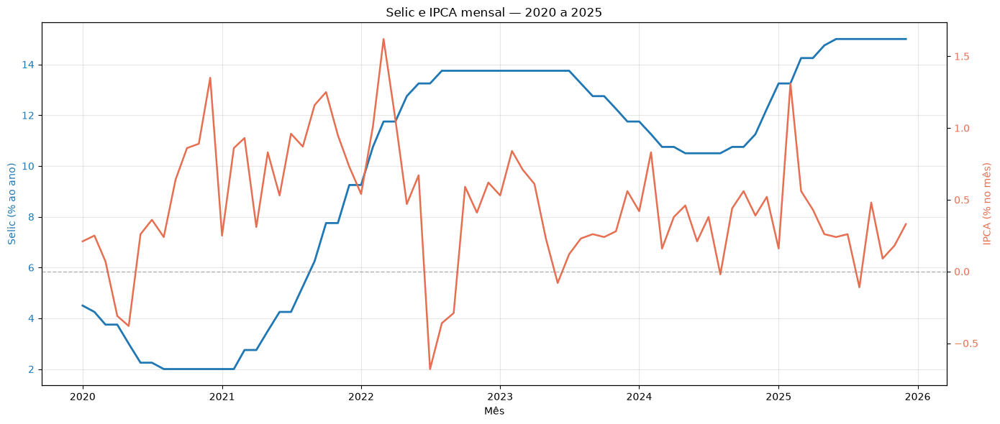

In [124]:
# ============================================================
# GRÁFICO COMPLEMENTAR COM DOIS EIXOS
# ============================================================

fig, eixo_selic = plt.subplots(
    figsize=(14, 6)
)

# Selic no eixo esquerdo
cor_selic = "#1f77b4"

eixo_selic.plot(
    comparacao_selic_ipca_valida["mes"],
    comparacao_selic_ipca_valida["selic"],
    color=cor_selic,
    linewidth=2,
    label="Selic"
)

eixo_selic.set_xlabel(
    "Mês"
)

eixo_selic.set_ylabel(
    "Selic (% ao ano)",
    color=cor_selic
)

eixo_selic.tick_params(
    axis="y",
    labelcolor=cor_selic
)

eixo_selic.grid(
    alpha=0.3
)

# IPCA no eixo direito
eixo_ipca = eixo_selic.twinx()

cor_ipca = "#e76f51"

eixo_ipca.plot(
    comparacao_selic_ipca_valida["mes"],
    comparacao_selic_ipca_valida["ipca"],
    color=cor_ipca,
    linewidth=1.8,
    label="IPCA"
)

eixo_ipca.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1,
    alpha=0.6
)

eixo_ipca.set_ylabel(
    "IPCA (% no mês)",
    color=cor_ipca
)

eixo_ipca.tick_params(
    axis="y",
    labelcolor=cor_ipca
)

plt.title(
    "Selic e IPCA mensal — 2020 a 2025"
)

fig.tight_layout()
plt.show()


In [125]:
# ============================================================
# IDENTIFICAÇÃO DOS VALORES EXTREMOS
# ============================================================

mes_maior_selic = comparacao_selic_ipca_valida.loc[
    comparacao_selic_ipca_valida[
        "selic"
    ].idxmax()
]

mes_menor_selic = comparacao_selic_ipca_valida.loc[
    comparacao_selic_ipca_valida[
        "selic"
    ].idxmin()
]

mes_maior_ipca = comparacao_selic_ipca_valida.loc[
    comparacao_selic_ipca_valida[
        "ipca"
    ].idxmax()
]

mes_menor_ipca = comparacao_selic_ipca_valida.loc[
    comparacao_selic_ipca_valida[
        "ipca"
    ].idxmin()
]

print("VALORES EXTREMOS DA SELIC\n")

print(
    f"Maior Selic: "
    f"{mes_maior_selic['selic']:.4f}% ao ano"
)

print(
    f"Mês: "
    f"{mes_maior_selic['mes']:%m/%Y}"
)

print(
    f"\nMenor Selic: "
    f"{mes_menor_selic['selic']:.4f}% ao ano"
)

print(
    f"Mês: "
    f"{mes_menor_selic['mes']:%m/%Y}"
)

print("\nVALORES EXTREMOS DO IPCA\n")

print(
    f"Maior IPCA mensal: "
    f"{mes_maior_ipca['ipca']:.4f}%"
)

print(
    f"Mês: "
    f"{mes_maior_ipca['mes']:%m/%Y}"
)

print(
    f"\nMenor IPCA mensal: "
    f"{mes_menor_ipca['ipca']:.4f}%"
)

print(
    f"Mês: "
    f"{mes_menor_ipca['mes']:%m/%Y}"
)

VALORES EXTREMOS DA SELIC

Maior Selic: 15.0000% ao ano
Mês: 06/2025

Menor Selic: 2.0000% ao ano
Mês: 08/2020

VALORES EXTREMOS DO IPCA

Maior IPCA mensal: 1.6200%
Mês: 03/2022

Menor IPCA mensal: -0.6800%
Mês: 07/2022


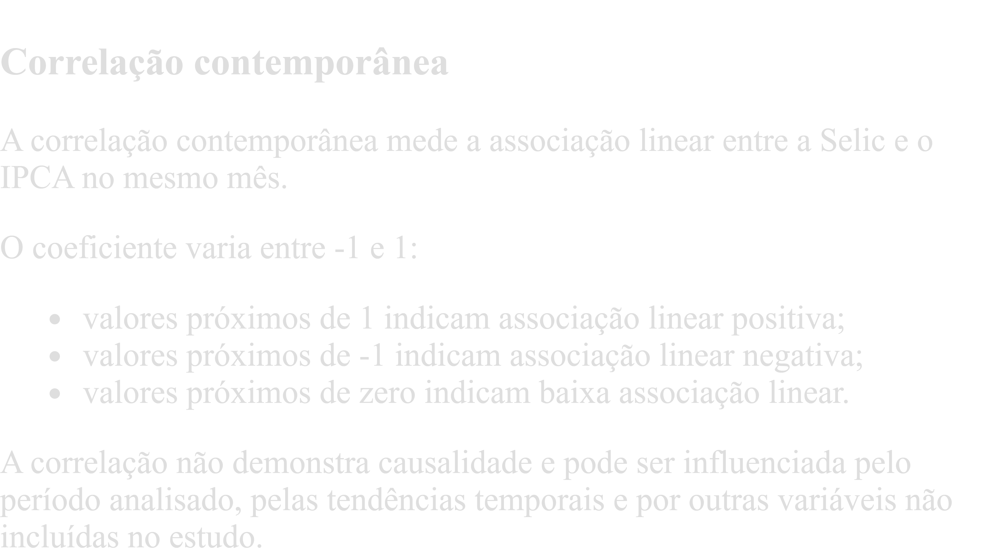

In [126]:
# ============================================================
# CORRELAÇÃO CONTEMPORÂNEA
# ============================================================

correlacao_selic_ipca = (
    comparacao_selic_ipca_valida[
        ["selic", "ipca"]
    ]
    .corr()
    .loc["selic", "ipca"]
)

print(
    "Correlação contemporânea entre "
    "Selic e IPCA:"
)

print(
    f"{correlacao_selic_ipca:.4f}"
)

Correlação contemporânea entre Selic e IPCA:
-0.2003


In [127]:
# Classificação apenas descritiva da magnitude
valor_absoluto_correlacao = abs(
    correlacao_selic_ipca
)

if valor_absoluto_correlacao < 0.20:
    intensidade_correlacao = "muito fraca"
elif valor_absoluto_correlacao < 0.40:
    intensidade_correlacao = "fraca"
elif valor_absoluto_correlacao < 0.60:
    intensidade_correlacao = "moderada"
elif valor_absoluto_correlacao < 0.80:
    intensidade_correlacao = "forte"
else:
    intensidade_correlacao = "muito forte"

if correlacao_selic_ipca > 0:
    direcao_correlacao = "positiva"
elif correlacao_selic_ipca < 0:
    direcao_correlacao = "negativa"
else:
    direcao_correlacao = "nula"

print(
    f"A associação linear observada foi "
    f"{intensidade_correlacao} e "
    f"{direcao_correlacao}."
)

print(
    "\nEsta classificação é apenas descritiva "
    "e não demonstra causalidade."
)

A associação linear observada foi fraca e negativa.

Esta classificação é apenas descritiva e não demonstra causalidade.


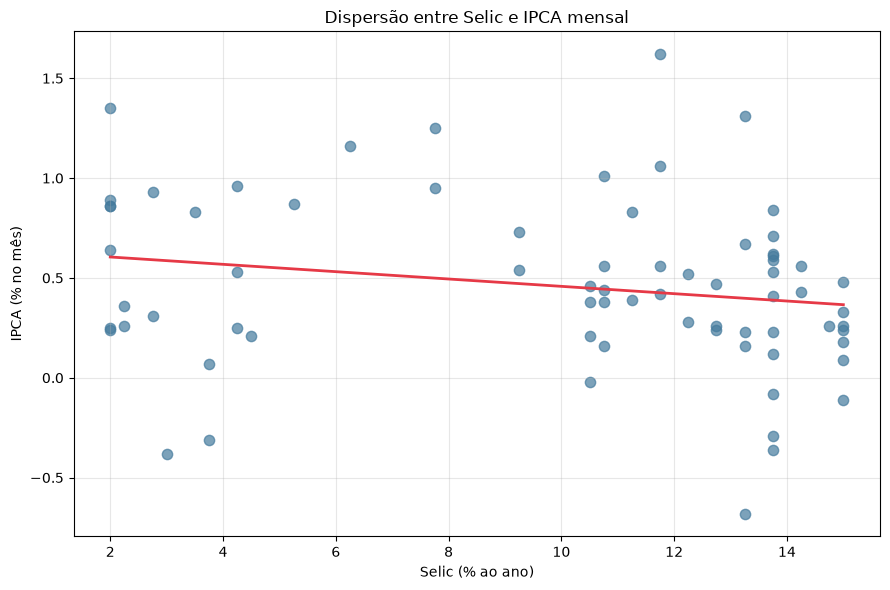

In [128]:
# ============================================================
# GRÁFICO DE DISPERSÃO
# ============================================================

plt.figure(figsize=(9, 6))

sns.regplot(
    data=comparacao_selic_ipca_valida,
    x="selic",
    y="ipca",
    scatter_kws={
        "alpha": 0.7,
        "s": 55,
        "color": "#457b9d"
    },
    line_kws={
        "color": "#e63946",
        "linewidth": 2
    },
    ci=None
)

plt.title(
    "Dispersão entre Selic e IPCA mensal"
)

plt.xlabel(
    "Selic (% ao ano)"
)

plt.ylabel(
    "IPCA (% no mês)"
)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

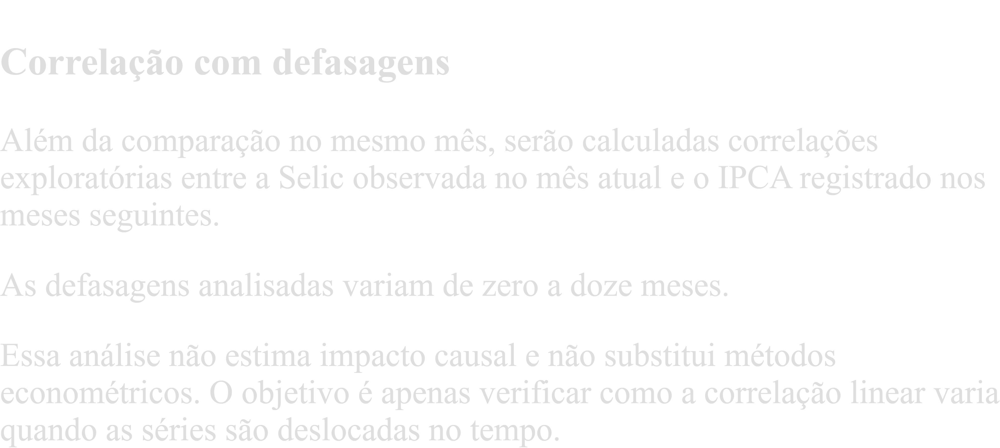

In [129]:
# ============================================================
# CORRELAÇÃO COM DEFASAGENS
# Selic no mês atual versus IPCA futuro
# ============================================================

resultados_defasagem = []

for defasagem in range(0, 13):

    dados_defasados = (
        comparacao_selic_ipca_valida[
            ["mes", "selic", "ipca"]
        ]
        .copy()
    )

    # IPCA futuro associado à Selic atual
    dados_defasados["ipca_futuro"] = (
        dados_defasados["ipca"]
        .shift(-defasagem)
    )

    dados_validos = (
        dados_defasados
        .dropna(
            subset=["selic", "ipca_futuro"]
        )
    )

    correlacao = (
        dados_validos[
            ["selic", "ipca_futuro"]
        ]
        .corr()
        .loc["selic", "ipca_futuro"]
    )

    resultados_defasagem.append({
        "defasagem_meses": defasagem,
        "observacoes": len(dados_validos),
        "correlacao": correlacao
    })

correlacoes_defasadas_selic_ipca = pd.DataFrame(
    resultados_defasagem
)

correlacoes_defasadas_selic_ipca[
    "correlacao"
] = correlacoes_defasadas_selic_ipca[
    "correlacao"
].round(4)

correlacoes_defasadas_selic_ipca

,defasagem_meses,observacoes,correlacao
0,0,72,-0.2003
1,1,71,-0.2558
2,2,70,-0.3087
3,3,69,-0.3585
4,4,68,-0.4240
5,5,67,-0.4863
6,6,66,-0.4986
7,7,65,-0.5141
8,8,64,-0.5146
9,9,63,-0.5111


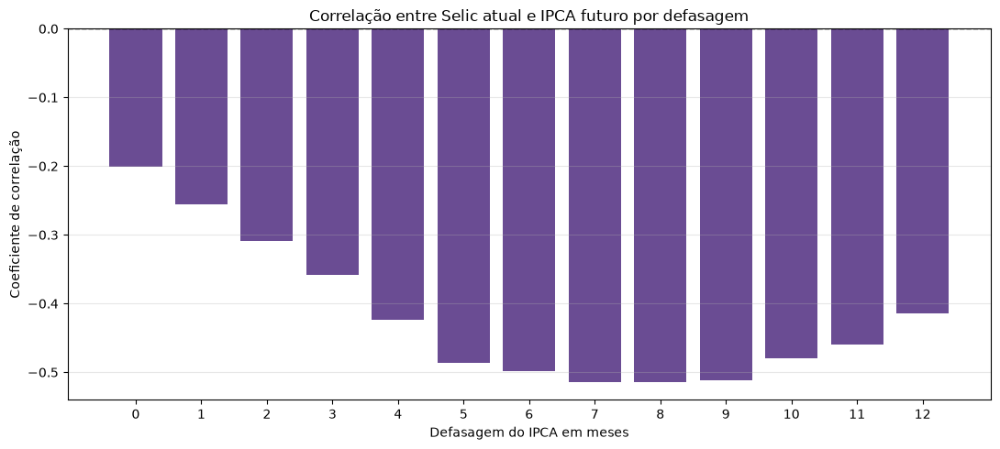

In [130]:
# ============================================================
# GRÁFICO DAS CORRELAÇÕES COM DEFASAGENS
# ============================================================

plt.figure(figsize=(11, 5))

plt.bar(
    correlacoes_defasadas_selic_ipca[
        "defasagem_meses"
    ],
    correlacoes_defasadas_selic_ipca[
        "correlacao"
    ],
    color="#6a4c93"
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Correlação entre Selic atual e IPCA futuro por defasagem"
)

plt.xlabel(
    "Defasagem do IPCA em meses"
)

plt.ylabel(
    "Coeficiente de correlação"
)

plt.xticks(
    range(0, 13)
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [132]:
# ============================================================
# DESTAQUE EXPLORATÓRIO DAS DEFASAGENS
# ============================================================

indice_maior_correlacao_absoluta = (
    correlacoes_defasadas_selic_ipca[
        "correlacao"
    ]
    .abs()
    .idxmax()
)

maior_correlacao_defasada = (
    correlacoes_defasadas_selic_ipca
    .loc[indice_maior_correlacao_absoluta]
)

print(
    "MAIOR CORRELAÇÃO ABSOLUTA OBSERVADA\n"
)

print(
    f"Defasagem: "
    f"{int(maior_correlacao_defasada['defasagem_meses'])} "
    f"mês(es)"
)

print(
    f"Correlação: "
    f"{maior_correlacao_defasada['correlacao']:.4f}"
)

print(
    f"Observações utilizadas: "
    f"{int(maior_correlacao_defasada['observacoes'])}"
)

print(
    "\nO resultado é exploratório e não representa "
    "evidência de causalidade."
)

MAIOR CORRELAÇÃO ABSOLUTA OBSERVADA

Defasagem: 8 mês(es)
Correlação: -0.5146
Observações utilizadas: 64

O resultado é exploratório e não representa evidência de causalidade.


In [133]:
# ============================================================
# RESUMO DA COMPARAÇÃO SELIC X IPCA
# ============================================================

resumo_selic_ipca = pd.DataFrame({
    "Indicador": [
        "Período inicial",
        "Período final",
        "Quantidade de meses",
        "Selic média",
        "Menor Selic",
        "Maior Selic",
        "IPCA médio mensal",
        "Menor IPCA mensal",
        "Maior IPCA mensal",
        "Correlação contemporânea",
        "Defasagem com maior correlação absoluta",
        "Maior correlação absoluta observada"
    ],
    "Resultado": [
        comparacao_selic_ipca_valida[
            "mes"
        ].min().strftime("%m/%Y"),

        comparacao_selic_ipca_valida[
            "mes"
        ].max().strftime("%m/%Y"),

        str(len(comparacao_selic_ipca_valida)),

        (
            f"{comparacao_selic_ipca_valida['selic'].mean():.4f}% a.a."
        ),

        (
            f"{comparacao_selic_ipca_valida['selic'].min():.4f}% a.a."
        ),

        (
            f"{comparacao_selic_ipca_valida['selic'].max():.4f}% a.a."
        ),

        (
            f"{comparacao_selic_ipca_valida['ipca'].mean():.4f}% a.m."
        ),

        (
            f"{comparacao_selic_ipca_valida['ipca'].min():.4f}% a.m."
        ),

        (
            f"{comparacao_selic_ipca_valida['ipca'].max():.4f}% a.m."
        ),

        f"{correlacao_selic_ipca:.4f}",

        (
            f"{int(maior_correlacao_defasada['defasagem_meses'])} "
            f"mês(es)"
        ),

        (
            f"{maior_correlacao_defasada['correlacao']:.4f}"
        )
    ]
})

resumo_selic_ipca

,Indicador,Resultado
0,Período inicial,01/2020
1,Período final,12/2025
2,Quantidade de meses,72
3,Selic média,9.8368% a.a.
4,Menor Selic,2.0000% a.a.
5,Maior Selic,15.0000% a.a.
6,IPCA médio mensal,0.4608% a.m.
7,Menor IPCA mensal,-0.6800% a.m.
8,Maior IPCA mensal,1.6200% a.m.
9,Correlação contemporânea,-0.2003


In [134]:
# ============================================================
# EXPORTAÇÃO
# ============================================================

comparacao_selic_ipca_valida.to_csv(
    pasta_processados
    / "comparacao_selic_ipca_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

correlacoes_defasadas_selic_ipca.to_csv(
    pasta_processados
    / "correlacoes_defasadas_selic_ipca_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_selic_ipca.to_csv(
    pasta_processados
    / "resumo_selic_ipca_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Resultados da comparação Selic × IPCA "
    "exportados com sucesso!"
)

Resultados da comparação Selic × IPCA exportados com sucesso!


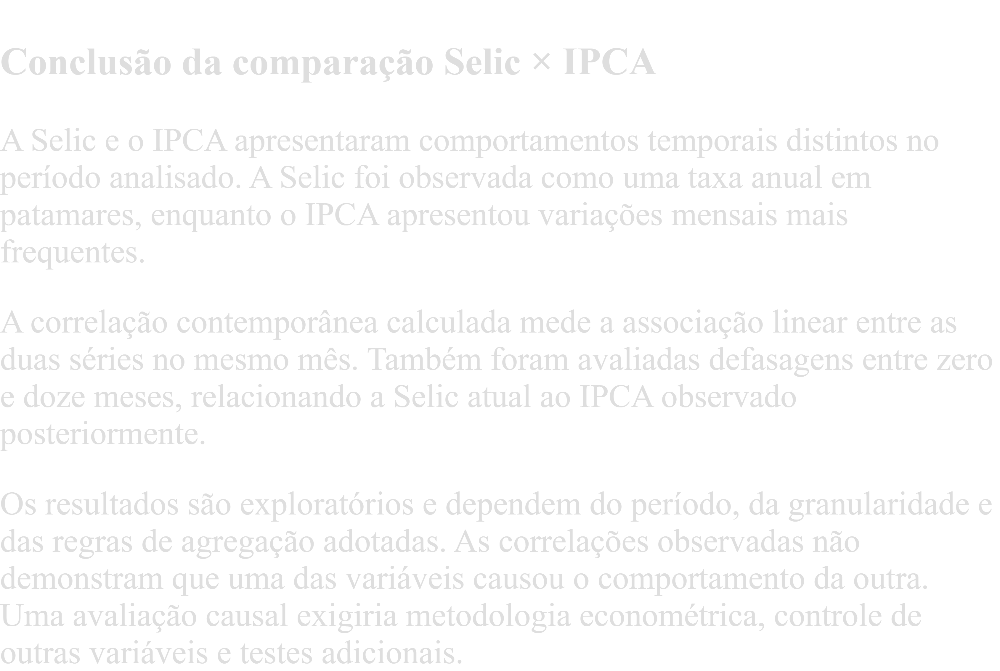

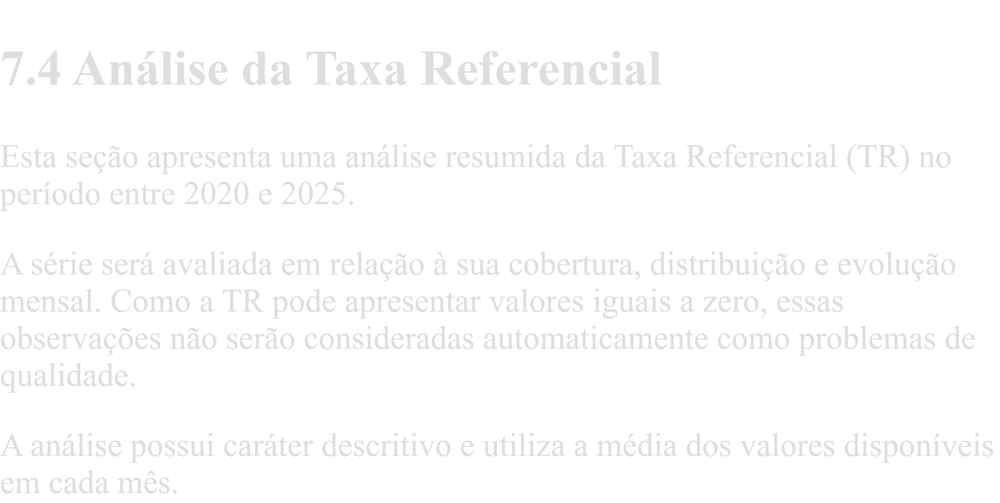

In [135]:
# ============================================================
# ANÁLISE RESUMIDA DA TAXA REFERENCIAL
# ============================================================

# Criar uma cópia da série original
analise_tr = df_tr.copy()

# Garantir ordenação cronológica
analise_tr = (
    analise_tr
    .sort_values("data")
    .reset_index(drop=True)
)

# Garantir que o valor seja numérico
analise_tr["valor"] = pd.to_numeric(
    analise_tr["valor"],
    errors="coerce"
)

# Validar a qualidade básica
print("QUALIDADE E COBERTURA DA TR\n")

print(
    "Quantidade de registros:",
    len(analise_tr)
)

print(
    "Data inicial:",
    analise_tr["data"].min()
)

print(
    "Data final:",
    analise_tr["data"].max()
)

print(
    "Datas nulas:",
    analise_tr["data"].isna().sum()
)

print(
    "Valores nulos:",
    analise_tr["valor"].isna().sum()
)

print(
    "Linhas duplicadas:",
    analise_tr.duplicated().sum()
)

print(
    "Datas duplicadas:",
    analise_tr
    .duplicated(subset=["data"])
    .sum()
)

print(
    "Valores inferiores a zero:",
    (analise_tr["valor"] < 0).sum()
)


QUALIDADE E COBERTURA DA TR

Quantidade de registros: 2232
Data inicial: 2020-01-01 00:00:00
Data final: 2025-12-31 00:00:00
Datas nulas: 0
Valores nulos: 0
Linhas duplicadas: 20
Datas duplicadas: 40
Valores inferiores a zero: 0


In [136]:
# ============================================================
# ESTATÍSTICAS DESCRITIVAS DA TR
# ============================================================

estatisticas_tr = (
    analise_tr["valor"]
    .describe()
)

print("ESTATÍSTICAS DESCRITIVAS DA TR\n")

print(
    f"Quantidade de observações: "
    f"{estatisticas_tr['count']:.0f}"
)

print(
    f"Média: "
    f"{estatisticas_tr['mean']:.6f}"
)

print(
    f"Mediana: "
    f"{estatisticas_tr['50%']:.6f}"
)

print(
    f"Desvio padrão: "
    f"{estatisticas_tr['std']:.6f}"
)

print(
    f"Menor valor: "
    f"{estatisticas_tr['min']:.6f}"
)

print(
    f"Maior valor: "
    f"{estatisticas_tr['max']:.6f}"
)

ESTATÍSTICAS DESCRITIVAS DA TR

Quantidade de observações: 2232
Média: 0.087220
Mediana: 0.077300
Desvio padrão: 0.075960
Menor valor: 0.000000
Maior valor: 0.244300


In [137]:
# ============================================================
# FREQUÊNCIA DE VALORES IGUAIS A ZERO
# ============================================================

quantidade_tr_zero = (
    analise_tr["valor"] == 0
).sum()

quantidade_tr_positiva = (
    analise_tr["valor"] > 0
).sum()

total_tr_valida = (
    analise_tr["valor"]
    .notna()
    .sum()
)

percentual_tr_zero = (
    quantidade_tr_zero
    / total_tr_valida
    * 100
)

percentual_tr_positiva = (
    quantidade_tr_positiva
    / total_tr_valida
    * 100
)

print("DISTRIBUIÇÃO DOS REGISTROS DA TR\n")

print(
    f"Valores iguais a zero: "
    f"{quantidade_tr_zero}"
)

print(
    f"Percentual igual a zero: "
    f"{percentual_tr_zero:.2f}%"
)

print(
    f"\nValores positivos: "
    f"{quantidade_tr_positiva}"
)

print(
    f"Percentual positivo: "
    f"{percentual_tr_positiva:.2f}%"
)

print(
    f"\nTotal de valores válidos: "
    f"{total_tr_valida}"
)

print(
    "\nContagens consistentes:",
    (
        quantidade_tr_zero
        + quantidade_tr_positiva
        == total_tr_valida
    )
)

DISTRIBUIÇÃO DOS REGISTROS DA TR

Valores iguais a zero: 735
Percentual igual a zero: 32.93%

Valores positivos: 1497
Percentual positivo: 67.07%

Total de valores válidos: 2232

Contagens consistentes: True


In [138]:
# ============================================================
# VALIDAÇÃO DA TR MENSAL
# ============================================================

print(
    "Quantidade de meses:",
    len(tr_mensal)
)

print(
    "Mês inicial:",
    tr_mensal["mes"].min()
)

print(
    "Mês final:",
    tr_mensal["mes"].max()
)

print(
    "Valores mensais nulos:",
    tr_mensal["tr"].isna().sum()
)

print(
    "Meses duplicados:",
    tr_mensal
    .duplicated(subset=["mes"])
    .sum()
)

tr_mensal.head()

Quantidade de meses: 72
Mês inicial: 2020-01-01 00:00:00
Mês final: 2025-12-01 00:00:00
Valores mensais nulos: 0
Meses duplicados: 0


,mes,tr
0,2020-01-01,0.0
1,2020-02-01,0.0
2,2020-03-01,0.0
3,2020-04-01,0.0
4,2020-05-01,0.0


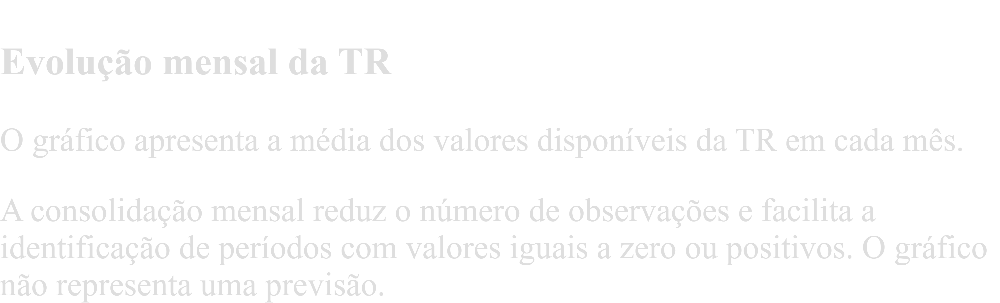

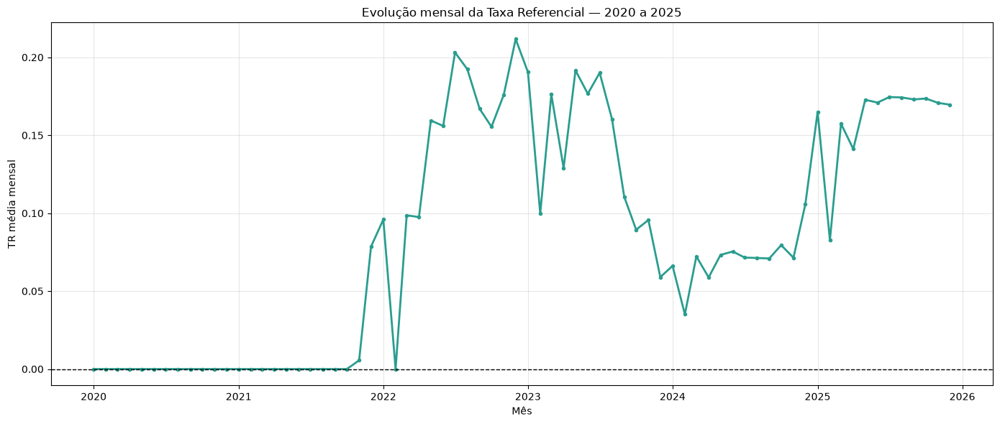

In [139]:
# ============================================================
# EVOLUÇÃO MENSAL DA TR
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    tr_mensal["mes"],
    tr_mensal["tr"],
    color="#2a9d8f",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Evolução mensal da Taxa Referencial — 2020 a 2025"
)

plt.xlabel("Mês")
plt.ylabel("TR média mensal")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [140]:
# ============================================================
# EXTREMOS MENSAIS DA TR
# ============================================================

mes_maior_tr = tr_mensal.loc[
    tr_mensal["tr"].idxmax()
]

mes_menor_tr = tr_mensal.loc[
    tr_mensal["tr"].idxmin()
]

print("EXTREMOS MENSAIS DA TR\n")

print(
    f"Maior média mensal: "
    f"{mes_maior_tr['tr']:.6f}"
)

print(
    f"Mês: "
    f"{mes_maior_tr['mes']:%m/%Y}"
)

print(
    f"\nMenor média mensal: "
    f"{mes_menor_tr['tr']:.6f}"
)

print(
    f"Mês: "
    f"{mes_menor_tr['mes']:%m/%Y}"
)

EXTREMOS MENSAIS DA TR

Maior média mensal: 0.211750
Mês: 12/2022

Menor média mensal: 0.000000
Mês: 01/2020


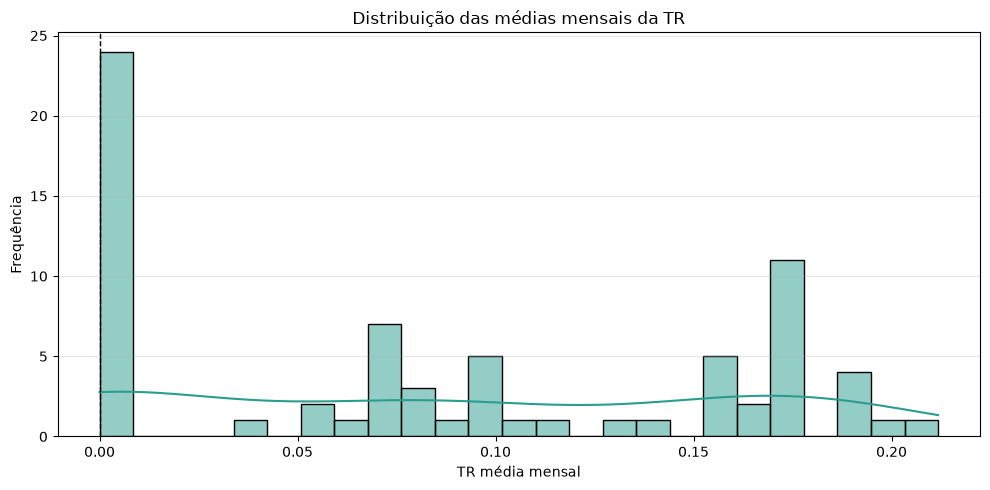

In [141]:
# ============================================================
# DISTRIBUIÇÃO DOS VALORES MENSAIS DA TR
# ============================================================

plt.figure(figsize=(10, 5))

sns.histplot(
    data=tr_mensal,
    x="tr",
    bins=25,
    kde=True,
    color="#2a9d8f"
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title(
    "Distribuição das médias mensais da TR"
)

plt.xlabel("TR média mensal")
plt.ylabel("Frequência")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [142]:
# ============================================================
# RESUMO CONSOLIDADO DA TR
# ============================================================

resumo_tr = pd.DataFrame({
    "Indicador": [
        "Data inicial",
        "Data final",
        "Quantidade de registros originais",
        "Quantidade de meses",
        "Média dos registros originais",
        "Mediana dos registros originais",
        "Menor valor original",
        "Maior valor original",
        "Registros iguais a zero",
        "Percentual igual a zero",
        "Registros positivos",
        "Percentual positivo",
        "Menor média mensal",
        "Mês da menor média mensal",
        "Maior média mensal",
        "Mês da maior média mensal"
    ],
    "Resultado": [
        analise_tr["data"].min().strftime("%d/%m/%Y"),
        analise_tr["data"].max().strftime("%d/%m/%Y"),
        str(len(analise_tr)),
        str(len(tr_mensal)),
        f"{analise_tr['valor'].mean():.6f}",
        f"{analise_tr['valor'].median():.6f}",
        f"{analise_tr['valor'].min():.6f}",
        f"{analise_tr['valor'].max():.6f}",
        str(quantidade_tr_zero),
        f"{percentual_tr_zero:.2f}%",
        str(quantidade_tr_positiva),
        f"{percentual_tr_positiva:.2f}%",
        f"{mes_menor_tr['tr']:.6f}",
        mes_menor_tr["mes"].strftime("%m/%Y"),
        f"{mes_maior_tr['tr']:.6f}",
        mes_maior_tr["mes"].strftime("%m/%Y")
    ]
})

resumo_tr

,Indicador,Resultado
0,Data inicial,01/01/2020
1,Data final,31/12/2025
2,Quantidade de registros originais,2232
3,Quantidade de meses,72
4,Média dos registros originais,0.087220
5,Mediana dos registros originais,0.077300
6,Menor valor original,0.000000
7,Maior valor original,0.244300
8,Registros iguais a zero,735
9,Percentual igual a zero,32.93%


In [143]:
# ============================================================
# EXPORTAÇÃO DA TR
# ============================================================

analise_tr.to_csv(
    pasta_processados
    / "tr_dados_originais_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

tr_mensal.to_csv(
    pasta_processados
    / "tr_mensal_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_tr.to_csv(
    pasta_processados
    / "resumo_tr_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Resultados da TR exportados com sucesso!"
)

Resultados da TR exportados com sucesso!


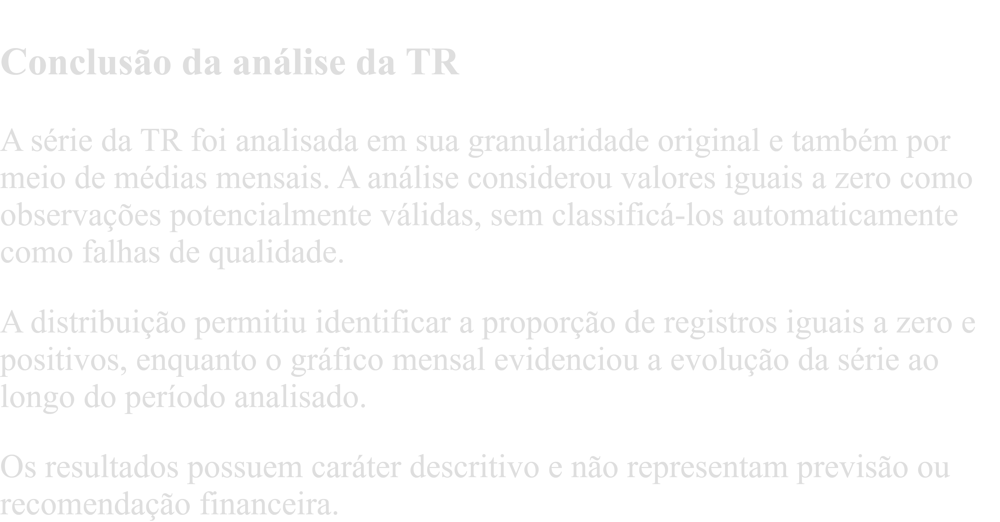

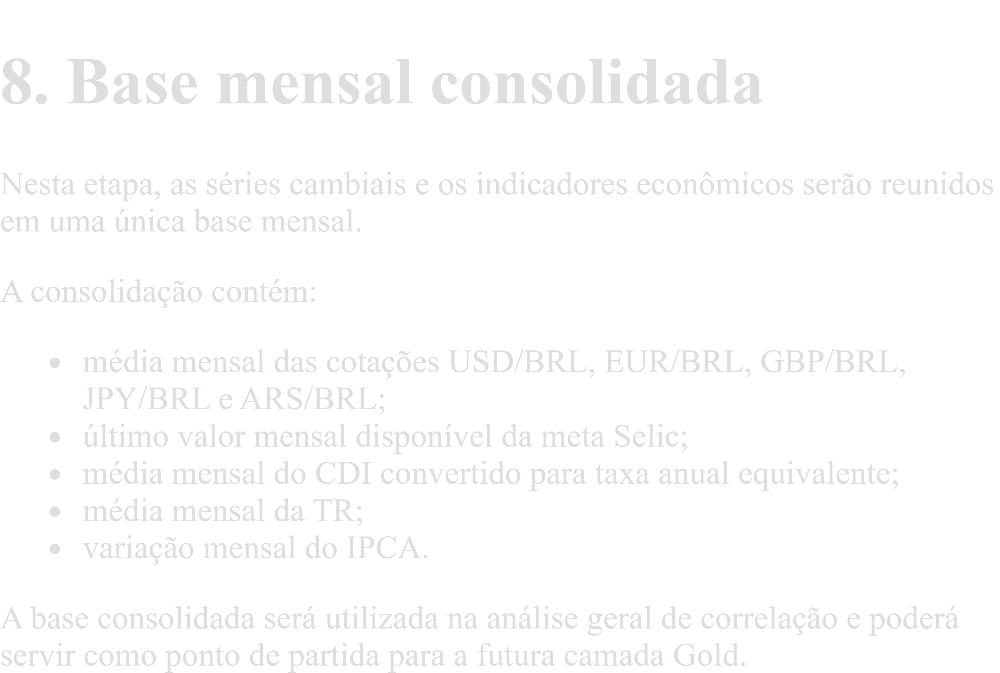

In [144]:
# ============================================================
# PREPARAÇÃO MENSAL DAS SÉRIES CAMBIAIS
# ============================================================

df_cambio_mensal_base = df_cambio.copy()

# Criar referência mensal
df_cambio_mensal_base["mes"] = (
    df_cambio_mensal_base["data"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Calcular a média mensal por moeda
cambio_mensal_longo = (
    df_cambio_mensal_base
    .groupby(
        ["mes", "serie"],
        as_index=False
    )
    .agg(
        valor_medio=("valor", "mean"),
        quantidade_observacoes=("valor", "count")
    )
)

cambio_mensal_longo.head()

,mes,serie,valor_medio,quantidade_observacoes
0,2020-01-01,ARS/BRL,0.436073,22
1,2020-01-01,EUR/BRL,4.605032,22
2,2020-01-01,GBP/BRL,5.424336,22
3,2020-01-01,JPY/BRL,0.037975,22
4,2020-01-01,USD/BRL,4.149464,22


In [145]:
# ============================================================
# COBERTURA MENSAL DAS MOEDAS
# ============================================================

cobertura_mensal_cambio = (
    cambio_mensal_longo
    .groupby("serie")
    .agg(
        quantidade_meses=("mes", "nunique"),
        mes_inicial=("mes", "min"),
        mes_final=("mes", "max"),
        menor_quantidade_mensal=(
            "quantidade_observacoes",
            "min"
        ),
        maior_quantidade_mensal=(
            "quantidade_observacoes",
            "max"
        )
    )
    .reset_index()
)

cobertura_mensal_cambio


,serie,quantidade_meses,mes_inicial,mes_final,menor_quantidade_mensal,maior_quantidade_mensal
0,ARS/BRL,72,2020-01-01,2025-12-01,18,23
1,EUR/BRL,72,2020-01-01,2025-12-01,18,23
2,GBP/BRL,72,2020-01-01,2025-12-01,18,23
3,JPY/BRL,72,2020-01-01,2025-12-01,18,23
4,USD/BRL,72,2020-01-01,2025-12-01,18,23


In [146]:
# ============================================================
# CONVERSÃO DAS MOEDAS PARA O FORMATO LARGO
# ============================================================

cambio_mensal = (
    cambio_mensal_longo
    .pivot(
        index="mes",
        columns="serie",
        values="valor_medio"
    )
    .reset_index()
)

# Renomear as colunas
cambio_mensal = cambio_mensal.rename(
    columns={
        "USD/BRL": "usd_brl",
        "EUR/BRL": "eur_brl",
        "GBP/BRL": "gbp_brl",
        "JPY/BRL": "jpy_brl",
        "ARS/BRL": "ars_brl"
    }
)

# Remover o nome atribuído pelo pivot ao agrupamento
cambio_mensal.columns.name = None

# Ordenar cronologicamente
cambio_mensal = (
    cambio_mensal
    .sort_values("mes")
    .reset_index(drop=True)
)

cambio_mensal.head()

,mes,ars_brl,eur_brl,gbp_brl,jpy_brl,usd_brl
0,2020-01-01,0.436073,4.605032,5.424336,0.037975,4.149464
1,2020-02-01,0.448200,4.737406,5.624306,0.039477,4.341011
2,2020-03-01,0.495673,5.391373,6.030836,0.045356,4.883855
3,2020-04-01,0.531450,5.787965,6.616375,0.049454,5.325580
4,2020-05-01,0.580260,6.152150,6.933565,0.052631,5.643445


In [147]:
colunas_cambio_mensal = [
    "mes",
    "usd_brl",
    "eur_brl",
    "gbp_brl",
    "jpy_brl",
    "ars_brl"
]

cambio_mensal = cambio_mensal[
    colunas_cambio_mensal
]

cambio_mensal.head()

,mes,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
0,2020-01-01,4.149464,4.605032,5.424336,0.037975,0.436073
1,2020-02-01,4.341011,4.737406,5.624306,0.039477,0.448200
2,2020-03-01,4.883855,5.391373,6.030836,0.045356,0.495673
3,2020-04-01,5.325580,5.787965,6.616375,0.049454,0.531450
4,2020-05-01,5.643445,6.152150,6.933565,0.052631,0.580260


In [148]:
# ============================================================
# VALIDAÇÃO DA BASE CAMBIAL MENSAL
# ============================================================

print(
    "Quantidade de meses:",
    len(cambio_mensal)
)

print(
    "Período inicial:",
    cambio_mensal["mes"].min()
)

print(
    "Período final:",
    cambio_mensal["mes"].max()
)

print("\nValores nulos por coluna:")

print(
    cambio_mensal
    .isna()
    .sum()
)

print(
    "\nMeses duplicados:",
    cambio_mensal
    .duplicated(subset=["mes"])
    .sum()
)

Quantidade de meses: 72
Período inicial: 2020-01-01 00:00:00
Período final: 2025-12-01 00:00:00

Valores nulos por coluna:
mes        0
usd_brl    0
eur_brl    0
gbp_brl    0
jpy_brl    0
ars_brl    0
dtype: int64

Meses duplicados: 0


In [149]:
# ============================================================
# BASE ECONÔMICA MENSAL CONSOLIDADA
# ============================================================

base_economica_mensal = (
    df_indicadores_mensais
    .merge(
        cambio_mensal,
        on="mes",
        how="outer"
    )
    .sort_values("mes")
    .reset_index(drop=True)
)

base_economica_mensal.head()

,mes,selic,cdi,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
0,2020-01-01,4.50,4.400116,0.0,0.21,4.149464,4.605032,5.424336,0.037975,0.436073
1,2020-02-01,4.25,4.191684,0.0,0.25,4.341011,4.737406,5.624306,0.039477,0.448200
2,2020-03-01,3.75,3.945446,0.0,0.07,4.883855,5.391373,6.030836,0.045356,0.495673
3,2020-04-01,3.75,3.649983,0.0,-0.31,5.325580,5.787965,6.616375,0.049454,0.531450
4,2020-05-01,3.00,3.012526,0.0,-0.38,5.643445,6.152150,6.933565,0.052631,0.580260


In [150]:
base_economica_mensal = (
    base_economica_mensal
    .rename(
        columns={
            "cdi": "cdi_anual_equivalente"
        }
    )
)

base_economica_mensal.head()

,mes,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
0,2020-01-01,4.50,4.400116,0.0,0.21,4.149464,4.605032,5.424336,0.037975,0.436073
1,2020-02-01,4.25,4.191684,0.0,0.25,4.341011,4.737406,5.624306,0.039477,0.448200
2,2020-03-01,3.75,3.945446,0.0,0.07,4.883855,5.391373,6.030836,0.045356,0.495673
3,2020-04-01,3.75,3.649983,0.0,-0.31,5.325580,5.787965,6.616375,0.049454,0.531450
4,2020-05-01,3.00,3.012526,0.0,-0.38,5.643445,6.152150,6.933565,0.052631,0.580260


In [151]:
# ============================================================
# VALIDAÇÃO DA BASE CONSOLIDADA
# ============================================================

print("VALIDAÇÃO DA BASE ECONÔMICA MENSAL\n")

print(
    "Quantidade de meses:",
    len(base_economica_mensal)
)

print(
    "Mês inicial:",
    base_economica_mensal["mes"].min()
)

print(
    "Mês final:",
    base_economica_mensal["mes"].max()
)

print(
    "\nColunas disponíveis:"
)

print(
    base_economica_mensal.columns.tolist()
)

print(
    "\nValores nulos por coluna:"
)

print(
    base_economica_mensal
    .isna()
    .sum()
)

print(
    "\nMeses duplicados:",
    base_economica_mensal
    .duplicated(subset=["mes"])
    .sum()
)

print(
    "\nLinhas completamente duplicadas:",
    base_economica_mensal
    .duplicated()
    .sum()
)

VALIDAÇÃO DA BASE ECONÔMICA MENSAL

Quantidade de meses: 72
Mês inicial: 2020-01-01 00:00:00
Mês final: 2025-12-01 00:00:00

Colunas disponíveis:
['mes', 'selic', 'cdi_anual_equivalente', 'tr', 'ipca', 'usd_brl', 'eur_brl', 'gbp_brl', 'jpy_brl', 'ars_brl']

Valores nulos por coluna:
mes                      0
selic                    0
cdi_anual_equivalente    0
tr                       0
ipca                     0
usd_brl                  0
eur_brl                  0
gbp_brl                  0
jpy_brl                  0
ars_brl                  0
dtype: int64

Meses duplicados: 0

Linhas completamente duplicadas: 0


In [152]:
# Selecionar somente as colunas numéricas
colunas_numericas_base = (
    base_economica_mensal
    .select_dtypes(include="number")
    .columns
)

valores_infinitos_base = (
    np.isinf(
        base_economica_mensal[
            colunas_numericas_base
        ]
    )
    .sum()
)

print("Valores infinitos por coluna:")
print(valores_infinitos_base)

Valores infinitos por coluna:
selic                    0
cdi_anual_equivalente    0
tr                       0
ipca                     0
usd_brl                  0
eur_brl                  0
gbp_brl                  0
jpy_brl                  0
ars_brl                  0
dtype: int64


In [153]:
# ============================================================
# RESUMO DE QUALIDADE DA BASE MENSAL
# ============================================================

resumo_qualidade_base_mensal = pd.DataFrame({
    "coluna": base_economica_mensal.columns,
    "tipo": [
        str(tipo)
        for tipo in base_economica_mensal.dtypes
    ],
    "valores_validos": [
        base_economica_mensal[coluna]
        .notna()
        .sum()
        for coluna in base_economica_mensal.columns
    ],
    "valores_nulos": [
        base_economica_mensal[coluna]
        .isna()
        .sum()
        for coluna in base_economica_mensal.columns
    ],
    "valores_unicos": [
        base_economica_mensal[coluna]
        .nunique(dropna=True)
        for coluna in base_economica_mensal.columns
    ]
})

resumo_qualidade_base_mensal

,coluna,tipo,valores_validos,valores_nulos,valores_unicos
0,mes,datetime64[us],72,0,72
1,selic,float64,72,0,23
2,cdi_anual_equivalente,float64,72,0,50
3,tr,float64,72,0,50
4,ipca,float64,72,0,57
5,usd_brl,float64,72,0,72
6,eur_brl,float64,72,0,72
7,gbp_brl,float64,72,0,72
8,jpy_brl,float64,72,0,72
9,ars_brl,float64,72,0,72


In [154]:
print("Primeiros meses:")

display(
    base_economica_mensal.head()
)

print("Últimos meses:")

display(
    base_economica_mensal.tail()
)

Primeiros meses:


,mes,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
0,2020-01-01,4.50,4.400116,0.0,0.21,4.149464,4.605032,5.424336,0.037975,0.436073
1,2020-02-01,4.25,4.191684,0.0,0.25,4.341011,4.737406,5.624306,0.039477,0.448200
2,2020-03-01,3.75,3.945446,0.0,0.07,4.883855,5.391373,6.030836,0.045356,0.495673
3,2020-04-01,3.75,3.649983,0.0,-0.31,5.325580,5.787965,6.616375,0.049454,0.531450
4,2020-05-01,3.00,3.012526,0.0,-0.38,5.643445,6.152150,6.933565,0.052631,0.580260


Últimos meses:


,mes,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
67,2025-08-01,15.0,14.899981,0.174274,-0.11,5.446924,6.344214,7.329129,0.036934,0.568362
68,2025-09-01,15.0,14.899981,0.172987,0.48,5.367409,6.299777,7.250273,0.036310,0.572264
69,2025-10-01,15.0,14.899981,0.173584,0.09,5.385526,6.267817,7.192687,0.035580,0.570813
70,2025-11-01,15.0,14.899981,0.170777,0.18,5.340853,6.176216,7.021737,0.034467,0.561663
71,2025-12-01,15.0,14.899981,0.169616,0.33,5.453091,6.388659,7.303268,0.034984,0.586886


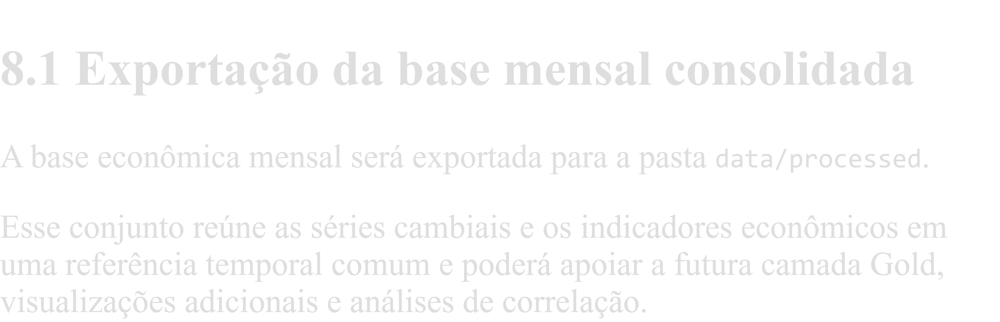

In [155]:
# ============================================================
# EXPORTAÇÃO DA BASE MENSAL CONSOLIDADA
# ============================================================

base_economica_mensal.to_csv(
    pasta_processados
    / "base_economica_mensal_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

cambio_mensal.to_csv(
    pasta_processados
    / "cambio_mensal_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

resumo_qualidade_base_mensal.to_csv(
    pasta_processados
    / "qualidade_base_economica_mensal_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Base econômica mensal e resultados de qualidade "
    "exportados com sucesso!"
)

Base econômica mensal e resultados de qualidade exportados com sucesso!


In [156]:
arquivos_base_mensal = [
    pasta_processados
    / "base_economica_mensal_2020_2025.csv",

    pasta_processados
    / "cambio_mensal_2020_2025.csv",

    pasta_processados
    / "qualidade_base_economica_mensal_2020_2025.csv"
]

print("Arquivos da base mensal:\n")

for arquivo in arquivos_base_mensal:
    print(
        f"- {arquivo.name}: "
        f"{'criado' if arquivo.exists() else 'não encontrado'}"
    )

Arquivos da base mensal:

- base_economica_mensal_2020_2025.csv: criado
- cambio_mensal_2020_2025.csv: criado
- qualidade_base_economica_mensal_2020_2025.csv: criado


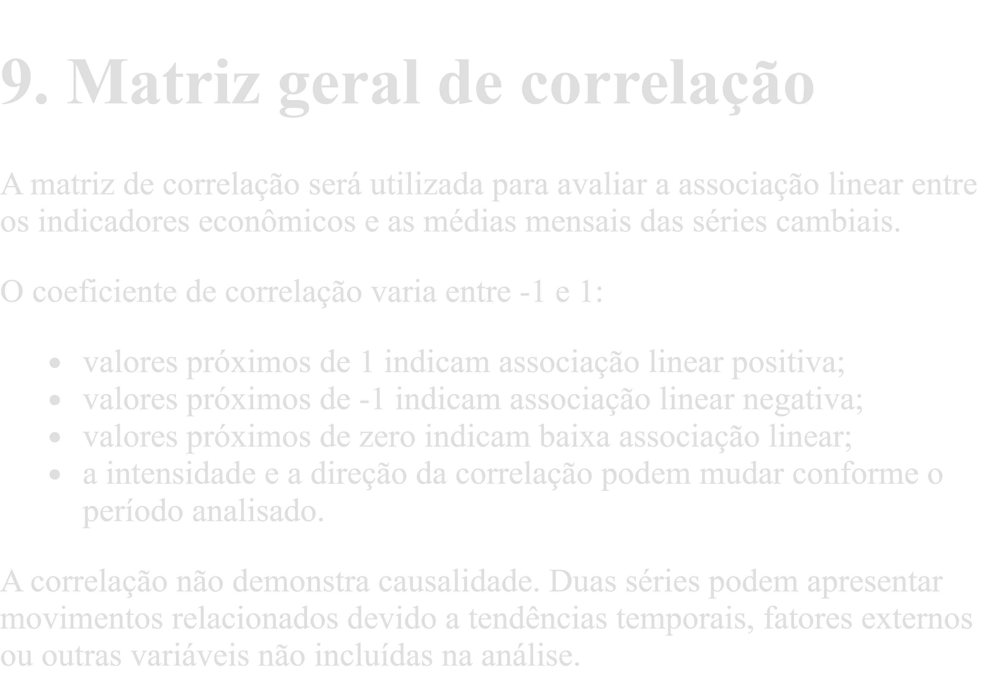

In [157]:
# ============================================================
# SELEÇÃO DAS VARIÁVEIS PARA CORRELAÇÃO
# ============================================================

colunas_correlacao = [
    "selic",
    "cdi_anual_equivalente",
    "tr",
    "ipca",
    "usd_brl",
    "eur_brl",
    "gbp_brl",
    "jpy_brl",
    "ars_brl"
]

dados_correlacao = (
    base_economica_mensal[
        ["mes"] + colunas_correlacao
    ]
    .copy()
)

dados_correlacao.head()

,mes,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
0,2020-01-01,4.50,4.400116,0.0,0.21,4.149464,4.605032,5.424336,0.037975,0.436073
1,2020-02-01,4.25,4.191684,0.0,0.25,4.341011,4.737406,5.624306,0.039477,0.448200
2,2020-03-01,3.75,3.945446,0.0,0.07,4.883855,5.391373,6.030836,0.045356,0.495673
3,2020-04-01,3.75,3.649983,0.0,-0.31,5.325580,5.787965,6.616375,0.049454,0.531450
4,2020-05-01,3.00,3.012526,0.0,-0.38,5.643445,6.152150,6.933565,0.052631,0.580260


In [158]:
# ============================================================
# VALIDAÇÃO DOS DADOS DA CORRELAÇÃO
# ============================================================

print("VALIDAÇÃO DOS DADOS PARA CORRELAÇÃO\n")

print(
    "Quantidade total de meses:",
    len(dados_correlacao)
)

print(
    "Data inicial:",
    dados_correlacao["mes"].min()
)

print(
    "Data final:",
    dados_correlacao["mes"].max()
)

print("\nValores nulos por coluna:")

print(
    dados_correlacao
    .isna()
    .sum()
)

print("\nTipos das colunas:")

print(
    dados_correlacao
    .dtypes
)

VALIDAÇÃO DOS DADOS PARA CORRELAÇÃO

Quantidade total de meses: 72
Data inicial: 2020-01-01 00:00:00
Data final: 2025-12-01 00:00:00

Valores nulos por coluna:
mes                      0
selic                    0
cdi_anual_equivalente    0
tr                       0
ipca                     0
usd_brl                  0
eur_brl                  0
gbp_brl                  0
jpy_brl                  0
ars_brl                  0
dtype: int64

Tipos das colunas:
mes                      datetime64[us]
selic                           float64
cdi_anual_equivalente           float64
tr                              float64
ipca                            float64
usd_brl                         float64
eur_brl                         float64
gbp_brl                         float64
jpy_brl                         float64
ars_brl                         float64
dtype: object


In [159]:
# ============================================================
# QUANTIDADE DE OBSERVAÇÕES VÁLIDAS POR PAR
# ============================================================

mascara_valores_validos = (
    dados_correlacao[colunas_correlacao]
    .notna()
    .astype(int)
)

quantidade_pares_validos = (
    mascara_valores_validos.T
    @ mascara_valores_validos
)

quantidade_pares_validos

,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
selic,72,72,72,72,72,72,72,72,72
cdi_anual_equivalente,72,72,72,72,72,72,72,72,72
tr,72,72,72,72,72,72,72,72,72
ipca,72,72,72,72,72,72,72,72,72
usd_brl,72,72,72,72,72,72,72,72,72
eur_brl,72,72,72,72,72,72,72,72,72
gbp_brl,72,72,72,72,72,72,72,72,72
jpy_brl,72,72,72,72,72,72,72,72,72
ars_brl,72,72,72,72,72,72,72,72,72


In [160]:
# ============================================================
# MATRIZ DE CORRELAÇÃO DE PEARSON
# ============================================================

matriz_correlacao = (
    dados_correlacao[
        colunas_correlacao
    ]
    .corr(method="pearson")
)

matriz_correlacao.round(4)

,selic,cdi_anual_equivalente,tr,ipca,usd_brl,eur_brl,gbp_brl,jpy_brl,ars_brl
selic,1.0000,0.9984,0.8947,-0.2003,0.0319,-0.3174,-0.1954,-0.8304,-0.5326
cdi_anual_equivalente,0.9984,1.0000,0.8963,-0.2210,0.0127,-0.3345,-0.2181,-0.8418,-0.5515
tr,0.8947,0.8963,1.0000,-0.3536,0.0453,-0.2703,-0.2084,-0.6791,-0.4419
ipca,-0.2003,-0.2210,-0.3536,1.0000,0.0477,0.2289,0.2522,0.2987,0.3324
usd_brl,0.0319,0.0127,0.0453,0.0477,1.0000,0.8085,0.8421,0.3058,0.6290
eur_brl,-0.3174,-0.3345,-0.2703,0.2289,0.8085,1.0000,0.9628,0.5923,0.9203
gbp_brl,-0.1954,-0.2181,-0.2084,0.2522,0.8421,0.9628,1.0000,0.4827,0.8607
jpy_brl,-0.8304,-0.8418,-0.6791,0.2987,0.3058,0.5923,0.4827,1.0000,0.8009
ars_brl,-0.5326,-0.5515,-0.4419,0.3324,0.6290,0.9203,0.8607,0.8009,1.0000


In [161]:
# ============================================================
# VALIDAÇÃO DA MATRIZ
# ============================================================

diagonal_igual_um = np.allclose(
    np.diag(matriz_correlacao),
    1
)

matriz_simetrica = np.allclose(
    matriz_correlacao,
    matriz_correlacao.T,
    equal_nan=True
)

valores_no_intervalo = (
    (
        matriz_correlacao
        .stack()
        .between(-1, 1)
    )
    .all()
)

print(
    "Diagonal principal igual a 1:",
    diagonal_igual_um
)

print(
    "Matriz simétrica:",
    matriz_simetrica
)

print(
    "Valores entre -1 e 1:",
    valores_no_intervalo
)

Diagonal principal igual a 1: True
Matriz simétrica: True
Valores entre -1 e 1: True


In [162]:
rotulos_correlacao = {
    "selic": "Selic",
    "cdi_anual_equivalente": "CDI anual",
    "tr": "TR",
    "ipca": "IPCA",
    "usd_brl": "USD/BRL",
    "eur_brl": "EUR/BRL",
    "gbp_brl": "GBP/BRL",
    "jpy_brl": "JPY/BRL",
    "ars_brl": "ARS/BRL"
}

matriz_correlacao_exibicao = (
    matriz_correlacao
    .rename(
        index=rotulos_correlacao,
        columns=rotulos_correlacao
    )
)

matriz_correlacao_exibicao.round(4)

,Selic,CDI anual,TR,IPCA,USD/BRL,EUR/BRL,GBP/BRL,JPY/BRL,ARS/BRL
Selic,1.0000,0.9984,0.8947,-0.2003,0.0319,-0.3174,-0.1954,-0.8304,-0.5326
CDI anual,0.9984,1.0000,0.8963,-0.2210,0.0127,-0.3345,-0.2181,-0.8418,-0.5515
TR,0.8947,0.8963,1.0000,-0.3536,0.0453,-0.2703,-0.2084,-0.6791,-0.4419
IPCA,-0.2003,-0.2210,-0.3536,1.0000,0.0477,0.2289,0.2522,0.2987,0.3324
USD/BRL,0.0319,0.0127,0.0453,0.0477,1.0000,0.8085,0.8421,0.3058,0.6290
EUR/BRL,-0.3174,-0.3345,-0.2703,0.2289,0.8085,1.0000,0.9628,0.5923,0.9203
GBP/BRL,-0.1954,-0.2181,-0.2084,0.2522,0.8421,0.9628,1.0000,0.4827,0.8607
JPY/BRL,-0.8304,-0.8418,-0.6791,0.2987,0.3058,0.5923,0.4827,1.0000,0.8009
ARS/BRL,-0.5326,-0.5515,-0.4419,0.3324,0.6290,0.9203,0.8607,0.8009,1.0000


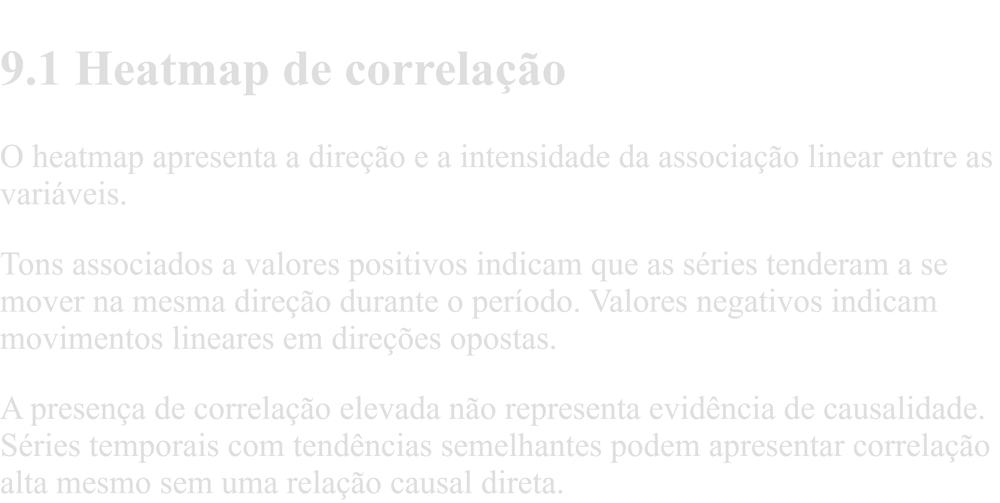

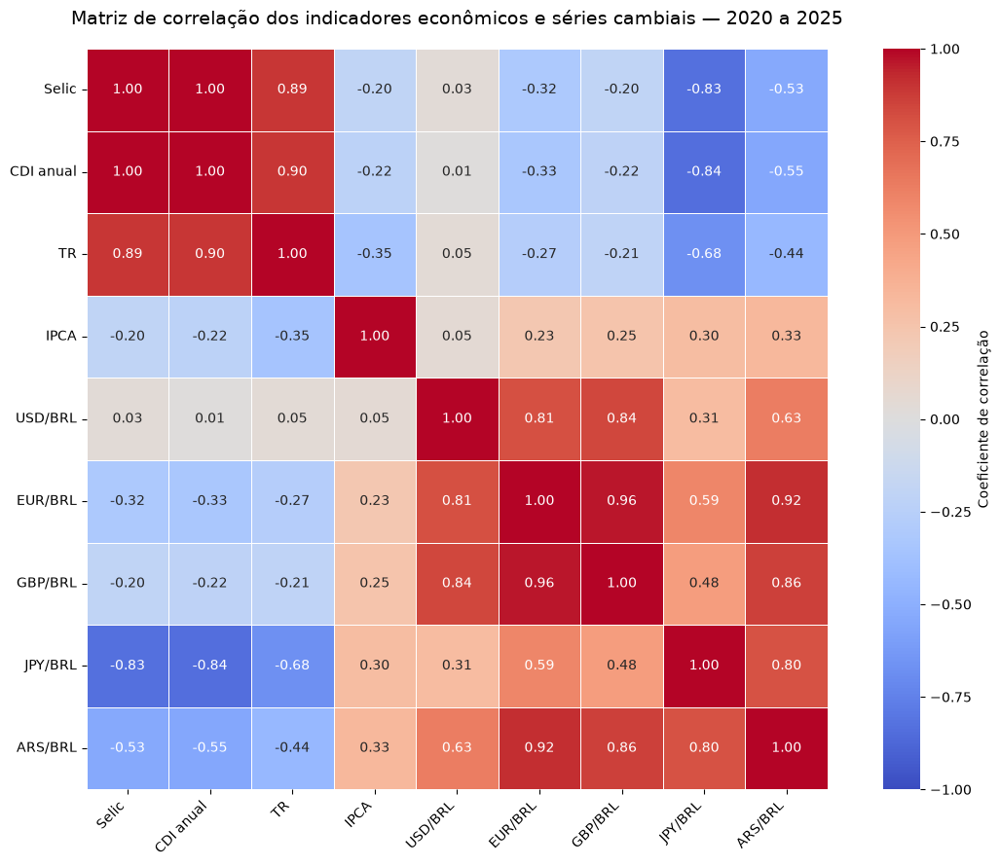

In [163]:
# ============================================================
# HEATMAP DE CORRELAÇÃO
# ============================================================

plt.figure(figsize=(12, 9))

sns.heatmap(
    matriz_correlacao_exibicao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Coeficiente de correlação"
    }
)

plt.title(
    "Matriz de correlação dos indicadores econômicos "
    "e séries cambiais — 2020 a 2025",
    fontsize=14,
    pad=18
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()

In [164]:
# ============================================================
# EXTRAÇÃO DOS PARES ÚNICOS DE CORRELAÇÃO
# ============================================================

mascara_superior = np.triu(
    np.ones(
        matriz_correlacao.shape,
        dtype=bool
    ),
    k=1
)

correlacoes_unicas = (
    matriz_correlacao
    .where(mascara_superior)
    .stack()
    .reset_index()
)

correlacoes_unicas.columns = [
    "variavel_1",
    "variavel_2",
    "correlacao"
]

correlacoes_unicas[
    "correlacao_absoluta"
] = correlacoes_unicas[
    "correlacao"
].abs()

correlacoes_unicas = (
    correlacoes_unicas
    .sort_values(
        "correlacao_absoluta",
        ascending=False
    )
    .reset_index(drop=True)
)

correlacoes_unicas.head(10)

,variavel_1,variavel_2,correlacao,correlacao_absoluta
0,selic,cdi_anual_equivalente,0.998424,0.998424
1,eur_brl,gbp_brl,0.962830,0.962830
2,eur_brl,ars_brl,0.920281,0.920281
3,cdi_anual_equivalente,tr,0.896333,0.896333
4,selic,tr,0.894710,0.894710
5,gbp_brl,ars_brl,0.860732,0.860732
6,usd_brl,gbp_brl,0.842148,0.842148
7,cdi_anual_equivalente,jpy_brl,-0.841835,0.841835
8,selic,jpy_brl,-0.830433,0.830433
9,usd_brl,eur_brl,0.808500,0.808500


In [165]:
correlacoes_unicas["variavel_1_exibicao"] = (
    correlacoes_unicas["variavel_1"]
    .map(rotulos_correlacao)
)

correlacoes_unicas["variavel_2_exibicao"] = (
    correlacoes_unicas["variavel_2"]
    .map(rotulos_correlacao)
)

correlacoes_unicas_exibicao = (
    correlacoes_unicas[
        [
            "variavel_1_exibicao",
            "variavel_2_exibicao",
            "correlacao",
            "correlacao_absoluta"
        ]
    ]
    .rename(
        columns={
            "variavel_1_exibicao": "variavel_1",
            "variavel_2_exibicao": "variavel_2"
        }
    )
)

correlacoes_unicas_exibicao[
    ["correlacao", "correlacao_absoluta"]
] = correlacoes_unicas_exibicao[
    ["correlacao", "correlacao_absoluta"]
].round(4)

correlacoes_unicas_exibicao.head(10)

,variavel_1,variavel_2,correlacao,correlacao_absoluta
0,Selic,CDI anual,0.9984,0.9984
1,EUR/BRL,GBP/BRL,0.9628,0.9628
2,EUR/BRL,ARS/BRL,0.9203,0.9203
3,CDI anual,TR,0.8963,0.8963
4,Selic,TR,0.8947,0.8947
5,GBP/BRL,ARS/BRL,0.8607,0.8607
6,USD/BRL,GBP/BRL,0.8421,0.8421
7,CDI anual,JPY/BRL,-0.8418,0.8418
8,Selic,JPY/BRL,-0.8304,0.8304
9,USD/BRL,EUR/BRL,0.8085,0.8085


In [166]:
# ============================================================
# MAIORES CORRELAÇÕES POSITIVAS
# ============================================================

maiores_correlacoes_positivas = (
    correlacoes_unicas_exibicao
    .query("correlacao > 0")
    .sort_values(
        "correlacao",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)

print("Maiores correlações positivas:")

display(
    maiores_correlacoes_positivas
)

Maiores correlações positivas:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
0,Selic,CDI anual,0.9984,0.9984
1,EUR/BRL,GBP/BRL,0.9628,0.9628
2,EUR/BRL,ARS/BRL,0.9203,0.9203
3,CDI anual,TR,0.8963,0.8963
4,Selic,TR,0.8947,0.8947
5,GBP/BRL,ARS/BRL,0.8607,0.8607
6,USD/BRL,GBP/BRL,0.8421,0.8421
7,USD/BRL,EUR/BRL,0.8085,0.8085
8,JPY/BRL,ARS/BRL,0.8009,0.8009
9,USD/BRL,ARS/BRL,0.6290,0.6290


In [167]:
# ============================================================
# MAIORES CORRELAÇÕES NEGATIVAS
# ============================================================

maiores_correlacoes_negativas = (
    correlacoes_unicas_exibicao
    .query("correlacao < 0")
    .sort_values(
        "correlacao",
        ascending=True
    )
    .head(10)
    .reset_index(drop=True)
)

print("Maiores correlações negativas:")

display(
    maiores_correlacoes_negativas
)

Maiores correlações negativas:


,variavel_1,variavel_2,correlacao,correlacao_absoluta
0,CDI anual,JPY/BRL,-0.8418,0.8418
1,Selic,JPY/BRL,-0.8304,0.8304
2,TR,JPY/BRL,-0.6791,0.6791
3,CDI anual,ARS/BRL,-0.5515,0.5515
4,Selic,ARS/BRL,-0.5326,0.5326
5,TR,ARS/BRL,-0.4419,0.4419
6,TR,IPCA,-0.3536,0.3536
7,CDI anual,EUR/BRL,-0.3345,0.3345
8,Selic,EUR/BRL,-0.3174,0.3174
9,TR,EUR/BRL,-0.2703,0.2703


In [168]:
# ============================================================
# DESTAQUES DA MATRIZ
# ============================================================

maior_correlacao_positiva = (
    correlacoes_unicas
    .loc[
        correlacoes_unicas["correlacao"].idxmax()
    ]
)

maior_correlacao_negativa = (
    correlacoes_unicas
    .loc[
        correlacoes_unicas["correlacao"].idxmin()
    ]
)

maior_correlacao_absoluta = (
    correlacoes_unicas
    .iloc[0]
)

print("DESTAQUES DA MATRIZ DE CORRELAÇÃO\n")

print("Maior correlação positiva:")

print(
    f"{rotulos_correlacao[maior_correlacao_positiva['variavel_1']]} "
    f"× "
    f"{rotulos_correlacao[maior_correlacao_positiva['variavel_2']]}"
)

print(
    f"Coeficiente: "
    f"{maior_correlacao_positiva['correlacao']:.4f}"
)

print("\nMaior correlação negativa:")

print(
    f"{rotulos_correlacao[maior_correlacao_negativa['variavel_1']]} "
    f"× "
    f"{rotulos_correlacao[maior_correlacao_negativa['variavel_2']]}"
)

print(
    f"Coeficiente: "
    f"{maior_correlacao_negativa['correlacao']:.4f}"
)

print("\nMaior correlação absoluta:")

print(
    f"{rotulos_correlacao[maior_correlacao_absoluta['variavel_1']]} "
    f"× "
    f"{rotulos_correlacao[maior_correlacao_absoluta['variavel_2']]}"
)

print(
    f"Coeficiente: "
    f"{maior_correlacao_absoluta['correlacao']:.4f}"
)

print(
    "\nOs resultados são descritivos e não demonstram "
    "relação causal."
)

DESTAQUES DA MATRIZ DE CORRELAÇÃO

Maior correlação positiva:
Selic × CDI anual
Coeficiente: 0.9984

Maior correlação negativa:
CDI anual × JPY/BRL
Coeficiente: -0.8418

Maior correlação absoluta:
Selic × CDI anual
Coeficiente: 0.9984

Os resultados são descritivos e não demonstram relação causal.


In [169]:
# ============================================================
# CORRELAÇÕES DO IPCA COM AS DEMAIS VARIÁVEIS
# ============================================================

correlacoes_ipca = (
    matriz_correlacao["ipca"]
    .drop("ipca")
    .sort_values(
        key=lambda serie: serie.abs(),
        ascending=False
    )
    .reset_index()
)

correlacoes_ipca.columns = [
    "variavel",
    "correlacao_com_ipca"
]

correlacoes_ipca["variavel_exibicao"] = (
    correlacoes_ipca["variavel"]
    .map(rotulos_correlacao)
)

correlacoes_ipca = correlacoes_ipca[
    [
        "variavel_exibicao",
        "correlacao_com_ipca"
    ]
].rename(
    columns={
        "variavel_exibicao": "variavel"
    }
)

correlacoes_ipca[
    "correlacao_com_ipca"
] = correlacoes_ipca[
    "correlacao_com_ipca"
].round(4)

correlacoes_ipca


,variavel,correlacao_com_ipca
0,TR,-0.3536
1,ARS/BRL,0.3324
2,JPY/BRL,0.2987
3,GBP/BRL,0.2522
4,EUR/BRL,0.2289
5,CDI anual,-0.2210
6,Selic,-0.2003
7,USD/BRL,0.0477


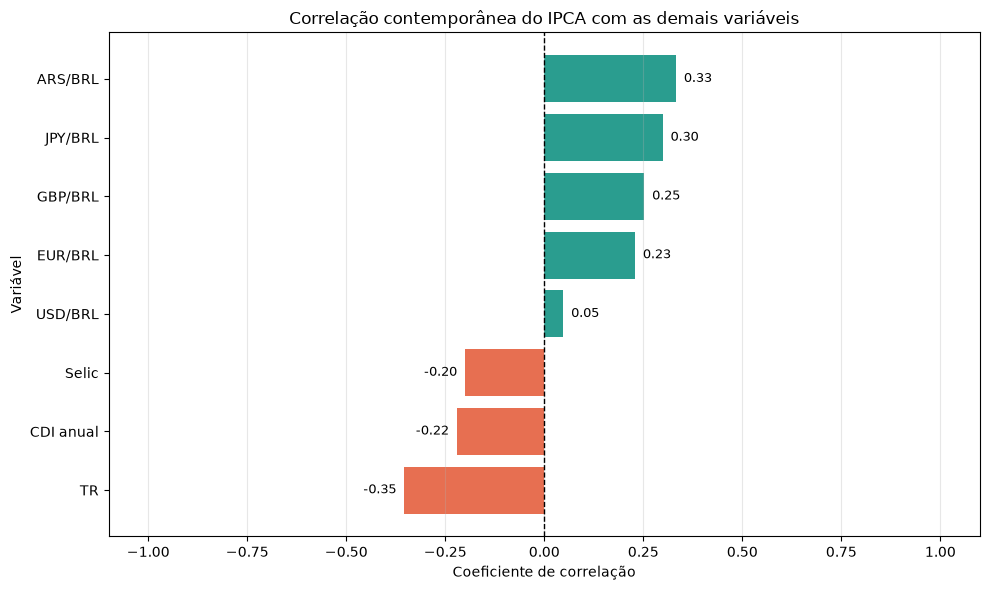

In [170]:
# ============================================================
# GRÁFICO DAS CORRELAÇÕES COM O IPCA
# ============================================================

correlacoes_ipca_grafico = (
    correlacoes_ipca
    .sort_values(
        "correlacao_com_ipca"
    )
    .reset_index(drop=True)
)

cores_ipca = [
    "#2a9d8f" if valor >= 0 else "#e76f51"
    for valor in correlacoes_ipca_grafico[
        "correlacao_com_ipca"
    ]
]

plt.figure(figsize=(10, 6))

barras = plt.barh(
    correlacoes_ipca_grafico["variavel"],
    correlacoes_ipca_grafico[
        "correlacao_com_ipca"
    ],
    color=cores_ipca
)

plt.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1
)

for barra, valor in zip(
    barras,
    correlacoes_ipca_grafico[
        "correlacao_com_ipca"
    ]
):
    deslocamento = 0.02 if valor >= 0 else -0.02
    alinhamento = "left" if valor >= 0 else "right"

    plt.text(
        valor + deslocamento,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}",
        va="center",
        ha=alinhamento,
        fontsize=9
    )

plt.title(
    "Correlação contemporânea do IPCA "
    "com as demais variáveis"
)

plt.xlabel(
    "Coeficiente de correlação"
)

plt.ylabel("Variável")
plt.xlim(-1.1, 1.1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.show()

In [171]:
# ============================================================
# EXPORTAÇÃO DOS RESULTADOS DE CORRELAÇÃO
# ============================================================

matriz_correlacao_exibicao.to_csv(
    pasta_processados
    / "matriz_correlacao_economica_2020_2025.csv",
    encoding="utf-8-sig"
)

quantidade_pares_validos.to_csv(
    pasta_processados
    / "quantidade_observacoes_correlacao_2020_2025.csv",
    encoding="utf-8-sig"
)

correlacoes_unicas_exibicao.to_csv(
    pasta_processados
    / "pares_correlacao_economica_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

correlacoes_ipca.to_csv(
    pasta_processados
    / "correlacoes_ipca_2020_2025.csv",
    index=False,
    encoding="utf-8-sig"
)

print(
    "Resultados da matriz de correlação "
    "exportados com sucesso!"
)


Resultados da matriz de correlação exportados com sucesso!


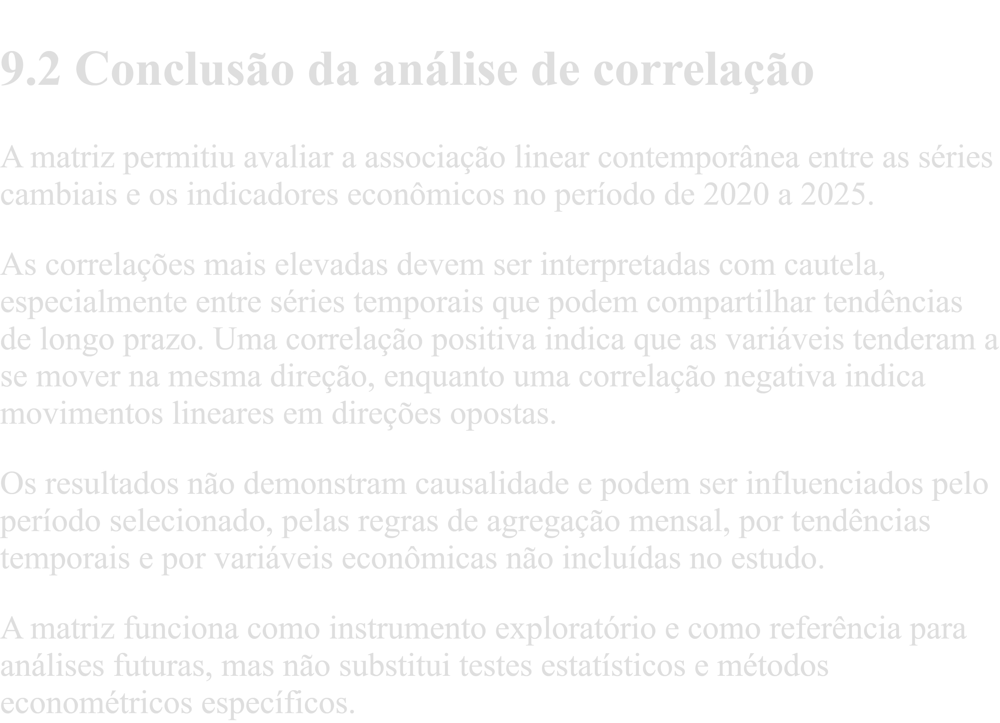

# 10. Conclusão geral

Este EDA explorou séries públicas do Banco Central do Brasil referentes ao período entre 2020 e 2025.

A análise contemplou cinco séries cambiais:

- USD/BRL;
- EUR/BRL;
- GBP/BRL;
- JPY/BRL;
- ARS/BRL.

Também foram analisados quatro indicadores econômicos:

- Selic;
- CDI;
- Taxa Referencial;
- IPCA.

Inicialmente, a série USD/BRL foi utilizada para validar o fluxo local de coleta, tratamento, avaliação de qualidade e visualização. Em seguida, o processo foi expandido para as demais moedas e indicadores por meio de uma função reutilizável de consulta à API SGS do Banco Central.

As verificações de qualidade incluíram análise de valores nulos, duplicidades, cobertura temporal, tipos de dados e valores incompatíveis com as regras adotadas. Os dados foram preservados em sua granularidade original e, posteriormente, consolidados na frequência mensal para permitir análises integradas.

Na análise cambial, as moedas foram comparadas por meio de um índice Base 100, evitando a comparação direta entre cotações com escalas diferentes. Também foram calculadas as variações acumuladas e a volatilidade histórica, representada pelo desvio padrão das variações percentuais diárias.

A comparação entre Selic e CDI exigiu a conversão do CDI diário em uma taxa anual equivalente, considerando 252 dias úteis. Após essa transformação, as séries passaram a ser comparáveis na mesma unidade. A diferença entre as taxas foi expressa em pontos percentuais.

A análise entre Selic e IPCA considerou que as séries possuem unidades distintas. Por esse motivo, não foi realizada uma subtra